In [1]:
import pandas as pd
import numpy as np
import h5py as h # for the mat file data manupulation

data_path = '/Users/icarus/Desktop/SPODcode/spod_matlab/spod_complete_continuous_database.mat'
target_st = 0.1

# lets take the st 0.1 first mode value
with h.File(data_path, 'r') as file:
    st_vector = np.squeeze(file['St_vector'][:])
    mode = 0
    
    target_fi = int(np.argmin(np.abs(st_vector - target_st)))
    actual_st = st_vector[target_fi]
 
    print(f"Target St: {actual_st:.4f} (Python index {target_fi})")
    
    a_real_series = file['A_coeffs_continuous_real'][:, mode, target_fi]
    a_imag_series = file['A_coeffs_continuous_imag'][:, mode, target_fi]
    
    t_uniform = np.squeeze(file['t_uniform'][:])


Target St: 0.0854 (Python index 2)


In [2]:
# import random, numpy as np, torch

# def seed_everything(seed=42):
#     random.seed(seed)
#     np.random.seed(seed)
#     torch.manual_seed(seed)
#     torch.cuda.manual_seed_all(seed)

# seed_everything(42)

In [3]:
############ ODE FIT ################

In [4]:
# combine
z_raw = (a_real_series + 1j * a_imag_series).flatten()
num_full_steps = len(z_raw)
t_model = t_uniform[:num_full_steps]

# # derivatives
# # using the analytical derivative as cdm is noisy
# def compute_derivatives(series, t_block):
#     da_dt = np.zeros_like(series, dtype=complex)
#     # Central differences
#     da_dt[1:-1] = (series[2:] - series[:-2]) / (t_block[2:] - t_block[:-2])
#     # Boundary differences
#     da_dt[0]  = (-3 * series[0]  + 4 * series[1]  - series[2])  / (t_block[2]  - t_block[0])
#     da_dt[-1] = ( 3 * series[-1] - 4 * series[-2] + series[-3]) / (t_block[-1] - t_block[-3])
#     return da_dt

# da1_dt_raw = compute_derivatives(a_1_raw, t_model)

# boundaries
train_end_idx = 2700
val_end_idx   = 3000

# train, val, and test
z_train    = z_raw[:train_end_idx]

z_val      = z_raw[train_end_idx:val_end_idx]

z_test     = z_raw[val_end_idx:]

t_train = t_model[:train_end_idx]
t_val   = t_model[train_end_idx:val_end_idx]
t_test  = t_model[val_end_idx:]

print("="*50)
# print(f"Train shapes: States {a_1_train.shape} | Derivs {da1_dt_train.shape}")
# print(f"Val shapes:   States {a_1_val.shape}   | Derivs {da1_dt_val.shape}")
# print(f"Test shapes:  States {a_1_test.shape}  | Derivs {da1_dt_test.shape}")
print("="*50)


# finite/central differencing is noisy, so this is not good for training, we use analytical in the next block

In [5]:
import numpy as np

# parameters for non-dim
Uj = 302.0  # Jet velocity [m/s]
Dj = 0.0169  # Jet diameter [m]
tau_scale = Uj / Dj  # Convective time factor tau = Uj/Dj (~17,869.82 s^-1)

# non-Dimensional Time Step dt*
dt_physical = np.mean(np.diff(t_model))  # Physical dt (~1.02e-5 s)
dt = dt_physical * tau_scale  # dt* in convective time units (~0.18)


# finite differences USING dt*
def get_derivatives(z, dt_star):
    """Calculates 1st and 2nd time derivatives using non-dimensional time step dt*."""
    # First derivative w.r.t. t* (Non-dimensional velocity)
    dz_dt = np.gradient(z, dt_star)

    # Second derivative w.r.t. t* (Non-dimensional acceleration)
    d2z_dt2 = np.gradient(dz_dt, dt_star)

    return dz_dt, d2z_dt2


#  derivatives per partition (evaluated strictly in t* domain)
dz_dt_train, d2z_dt2_train = get_derivatives(z_train, dt)
dz_dt_val, d2z_dt2_val = get_derivatives(z_val, dt)
dz_dt_test, d2z_dt2_test = get_derivatives(z_test, dt)

# features lib (Theta) - [z, dz_dt, z^2]
Theta_train = np.column_stack([z_train, dz_dt_train, z_train**2])

# direct OLS solve on well-conditioned non-dimensional acceleration targets
Xi, residuals, rank, s = np.linalg.lstsq(
    Theta_train, d2z_dt2_train, rcond=None
)

# extract Non-Dimensional Parameters
L_z_nondim = Xi[0]  # Coefficient for z
L_dz_nondim = Xi[1]  # Coefficient for z_dot
G_nondim = Xi[2]  # Coefficient for z^2

# revert to physical

L_z_discovered = L_z_nondim * (tau_scale**2)  # [1/s^2]
L_dz_discovered = L_dz_nondim * tau_scale  # [1/s]
G_discovered = G_nondim * (tau_scale**2)  # [1/(mag * s^2)]

# revert derivative arrays back to physical SI scale for downstream validation/plotting
dz_dt_train = dz_dt_train * tau_scale
d2z_dt2_train = d2z_dt2_train * (tau_scale**2)

dz_dt_val = dz_dt_val * tau_scale
d2z_dt2_val = d2z_dt2_val * (tau_scale**2)

dz_dt_test = dz_dt_test * tau_scale
d2z_dt2_test = d2z_dt2_test * (tau_scale**2)

# Display
print("=================================================================")
print("      OPERATOR INFERENCE (CONVERTED BACK TO PHYSICAL SI)         ")
print("=================================================================")
print(f"Non-Dim Time Step (dt*): {dt:.4f} (vs Physical dt: {dt_physical:.4e} s)")
print("-----------------------------------------------------------------")
print(f"L_z  (State Linear):    {L_z_discovered:.4e} s^-2")
print(f"L_dz (Velocity Damping): {L_dz_discovered:.4e} s^-1")
print(f"G    (Quadratic):       {G_discovered:.4e}")
print("=================================================================")

# Verification of shapes
print(
    f"Train shapes: States {z_train.shape} | Theta {Theta_train.shape} | Target {d2z_dt2_train.shape}"
)
print(
    f"Val shapes:   States {z_val.shape}   | Derivs {dz_dt_val.shape}   | Target {d2z_dt2_val.shape}"
)
print(
    f"Test shapes:  States {z_test.shape}  | Derivs {dz_dt_test.shape}  | Target {d2z_dt2_test.shape}"
)

      OPERATOR INFERENCE (CONVERTED BACK TO PHYSICAL SI)         
Non-Dim Time Step (dt*): 0.1830 (vs Physical dt: 1.0240e-05 s)
-----------------------------------------------------------------
L_z  (State Linear):    1.0114e+08-1.3713e+05j s^-2
L_dz (Velocity Damping): 1.5435e+01+2.0687e+04j s^-1
G    (Quadratic):       1.8142e+02-4.7751e+02j
Train shapes: States (2700,) | Theta (2700, 3) | Target (2700,)
Val shapes:   States (300,)   | Derivs (300,)   | Target (300,)
Test shapes:  States (2348,)  | Derivs (2348,)  | Target (2348,)


In [6]:
import numpy as np

# ============================================================
# Conjugate ablation / partial R²
#
# Existing dictionary:
#   [z, dz, z^2]
#
# Added conjugate dictionary:
#   [z_bar, z*z_bar, z_bar^2]
# ============================================================

# ---------- Helpers ----------
def complex_nrmse(y_true, y_pred):
    rmse = np.sqrt(np.mean(np.abs(y_true - y_pred)**2))
    scale = np.sqrt(np.mean(np.abs(y_true - np.mean(y_true))**2))
    return rmse / scale


def complex_r2(y_true, y_pred):
    ss_res = np.sum(np.abs(y_true - y_pred)**2)
    ss_tot = np.sum(np.abs(y_true - np.mean(y_true))**2)
    return 1.0 - ss_res / ss_tot


# ============================================================
# 1. Baseline fit in CURRENT PHYSICAL UNITS
# ============================================================

Theta_base_train = np.column_stack([
    z_train,
    dz_dt_train,
    z_train**2,
])

Xi_base, *_ = np.linalg.lstsq(
    Theta_base_train,
    d2z_dt2_train,
    rcond=None,
)

pred_base_train = Theta_base_train @ Xi_base
res_base_train = d2z_dt2_train - pred_base_train


# ============================================================
# 2. Candidate omitted conjugate features
# ============================================================

Theta_omit_train = np.column_stack([
    np.conj(z_train),                  # z_bar
    z_train * np.conj(z_train),        # z*z_bar = |z|^2
    np.conj(z_train)**2,               # z_bar^2
])


# ============================================================
# 3. NAIVE TEST:
#    How much baseline residual can omitted features fit directly?
# ============================================================

Xi_omit_naive, *_ = np.linalg.lstsq(
    Theta_omit_train,
    res_base_train,
    rcond=None,
)

res_after_naive = (
    res_base_train
    - Theta_omit_train @ Xi_omit_naive
)

naive_fraction = (
    1.0
    - np.sum(np.abs(res_after_naive)**2)
    / np.sum(np.abs(res_base_train)**2)
)


# ============================================================
# 4. CONDITIONAL / PARTIAL R² TEST
#
# Remove from each omitted feature anything already expressible
# by the baseline dictionary.
# ============================================================

# Projection of omitted columns onto baseline feature space
B, *_ = np.linalg.lstsq(
    Theta_base_train,
    Theta_omit_train,
    rcond=None,
)

Theta_omit_resid = (
    Theta_omit_train
    - Theta_base_train @ B
)

# Fit the baseline acceleration residual using ONLY the genuinely
# new directions supplied by the conjugate features.
Xi_omit_partial, *_ = np.linalg.lstsq(
    Theta_omit_resid,
    res_base_train,
    rcond=None,
)

res_after_partial = (
    res_base_train
    - Theta_omit_resid @ Xi_omit_partial
)

partial_r2 = (
    1.0
    - np.sum(np.abs(res_after_partial)**2)
    / np.sum(np.abs(res_base_train)**2)
)


# ============================================================
# 5. Full expanded model for direct comparison
# ============================================================

Theta_full_train = np.column_stack([
    z_train,
    dz_dt_train,
    np.conj(z_train),
    z_train**2,
    z_train * np.conj(z_train),
    np.conj(z_train)**2,
])

Xi_full, *_ = np.linalg.lstsq(
    Theta_full_train,
    d2z_dt2_train,
    rcond=None,
)

pred_full_train = Theta_full_train @ Xi_full


# ============================================================
# 6. HELD-OUT TEST
# ============================================================

Theta_base_test = np.column_stack([
    z_test,
    dz_dt_test,
    z_test**2,
])

Theta_full_test = np.column_stack([
    z_test,
    dz_dt_test,
    np.conj(z_test),
    z_test**2,
    z_test * np.conj(z_test),
    np.conj(z_test)**2,
])

pred_base_test = Theta_base_test @ Xi_base
pred_full_test = Theta_full_test @ Xi_full


# ============================================================
# 7. RESULTS
# ============================================================

print("=" * 70)
print("CONJUGATE FEATURE ABLATION")
print("=" * 70)

print("\nTRAINING ACCELERATION")
print("-" * 70)

print(
    f"Baseline:   "
    f"NRMSE = {complex_nrmse(d2z_dt2_train, pred_base_train):.6f} | "
    f"R2 = {complex_r2(d2z_dt2_train, pred_base_train):.8f}"
)

print(
    f"Conjugates: "
    f"NRMSE = {complex_nrmse(d2z_dt2_train, pred_full_train):.6f} | "
    f"R2 = {complex_r2(d2z_dt2_train, pred_full_train):.8f}"
)

print("\nRESIDUAL EXPLANATION")
print("-" * 70)

print(
    "Naive fraction of baseline residual explained by "
    f"conjugates: {100 * naive_fraction:.6f}%"
)

print(
    "Conditional / partial fraction of baseline residual explained "
    f"by genuinely new conjugate directions: {100 * partial_r2:.6f}%"
)


print("\nHELD-OUT TEST ACCELERATION")
print("-" * 70)

print(
    f"Baseline:   "
    f"NRMSE = {complex_nrmse(d2z_dt2_test, pred_base_test):.6f} | "
    f"R2 = {complex_r2(d2z_dt2_test, pred_base_test):.8f}"
)

print(
    f"Conjugates: "
    f"NRMSE = {complex_nrmse(d2z_dt2_test, pred_full_test):.6f} | "
    f"R2 = {complex_r2(d2z_dt2_test, pred_full_test):.8f}"
)


print("\nCONDITION NUMBERS")
print("-" * 70)
print(f"Baseline dictionary: {np.linalg.cond(Theta_base_train):.6e}")
print(f"Expanded dictionary: {np.linalg.cond(Theta_full_train):.6e}")


print("\nFULL MODEL COEFFICIENTS")
print("-" * 70)

names = [
    "z",
    "dz",
    "z_bar",
    "z^2",
    "|z|^2",
    "z_bar^2",
]

for name, coef in zip(names, Xi_full):
    print(
        f"{name:8s}: "
        f"{coef.real:+.6e} "
        f"{coef.imag:+.6e}j   "
        f"|coef|={abs(coef):.6e}"
    )

print("=" * 70)

CONJUGATE FEATURE ABLATION

TRAINING ACCELERATION
----------------------------------------------------------------------
Baseline:   NRMSE = 0.079123 | R2 = 0.99373960
Conjugates: NRMSE = 0.078938 | R2 = 0.99376875

RESIDUAL EXPLANATION
----------------------------------------------------------------------
Naive fraction of baseline residual explained by conjugates: 0.462401%
Conditional / partial fraction of baseline residual explained by genuinely new conjugate directions: 0.465524%

HELD-OUT TEST ACCELERATION
----------------------------------------------------------------------
Baseline:   NRMSE = 0.068291 | R2 = 0.99533635
Conjugates: NRMSE = 0.068704 | R2 = 0.99527973

CONDITION NUMBERS
----------------------------------------------------------------------
Baseline dictionary: 4.467723e+04
Expanded dictionary: 4.480833e+04

FULL MODEL COEFFICIENTS
----------------------------------------------------------------------
z       : +1.013453e+08 -1.218074e+05j   |coef|=1.013454e+08
dz

FIRST-ORDER COMPLEX CARRIER
lambda = -2.557726e+01 +1.006775e+04j
|lambda| = 1.006779e+04

Growth/decay rate sigma = -2.557726e+01 s^-1
Angular frequency omega = 1.006775e+04 rad/s
Frequency f = 1602.333 Hz

FIRST-DERIVATIVE FIT
----------------------------------------------------------------------
Train: NRMSE = 0.232098 | R2 = 0.946131
Test:  NRMSE = 0.229420 | R2 = 0.947367

IMPLIED ACCELERATION FIT
----------------------------------------------------------------------
Train: NRMSE = 0.429875 | R2 = 0.815208
Test:  NRMSE = 0.422304 | R2 = 0.821659

THREE-TERM SECOND-ORDER ACCELERATION
----------------------------------------------------------------------
Test: NRMSE = 0.068291 | R2 = 0.995336


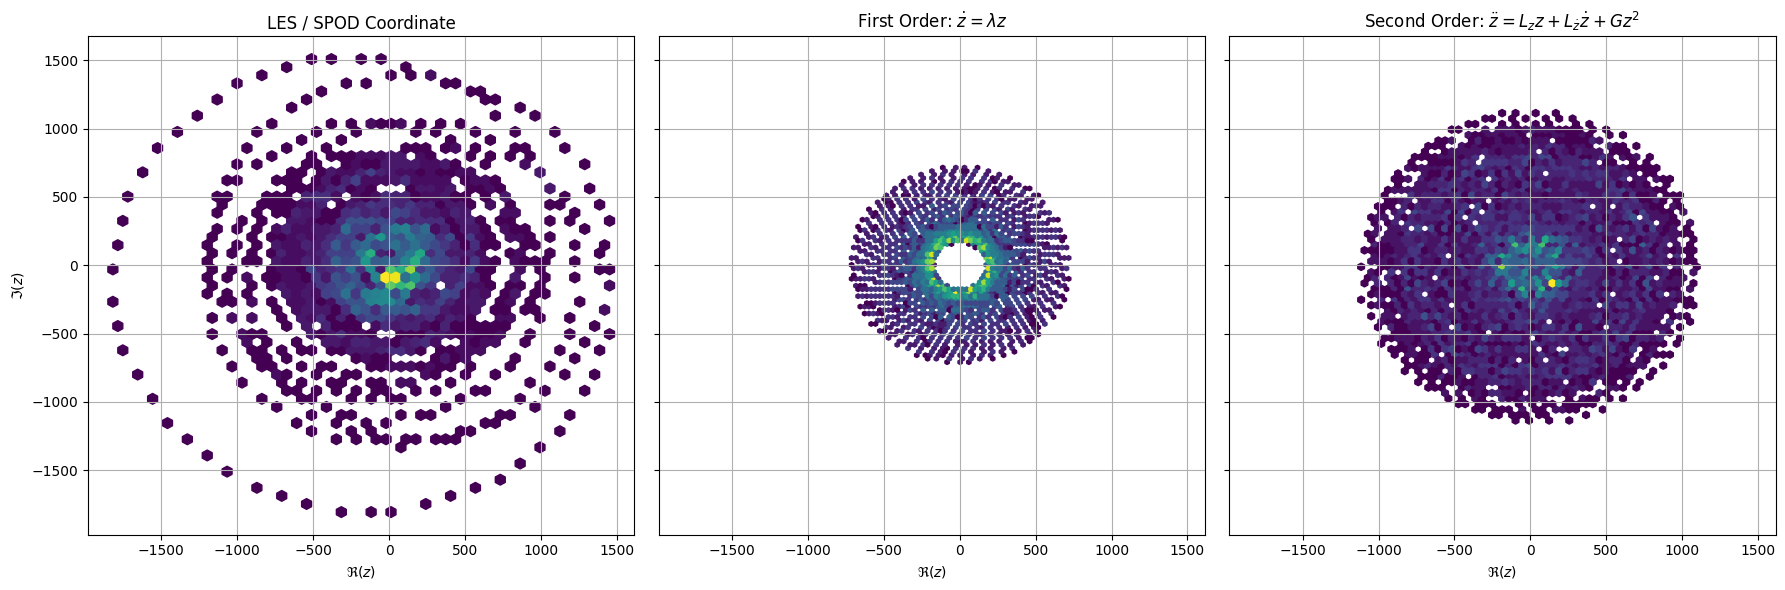

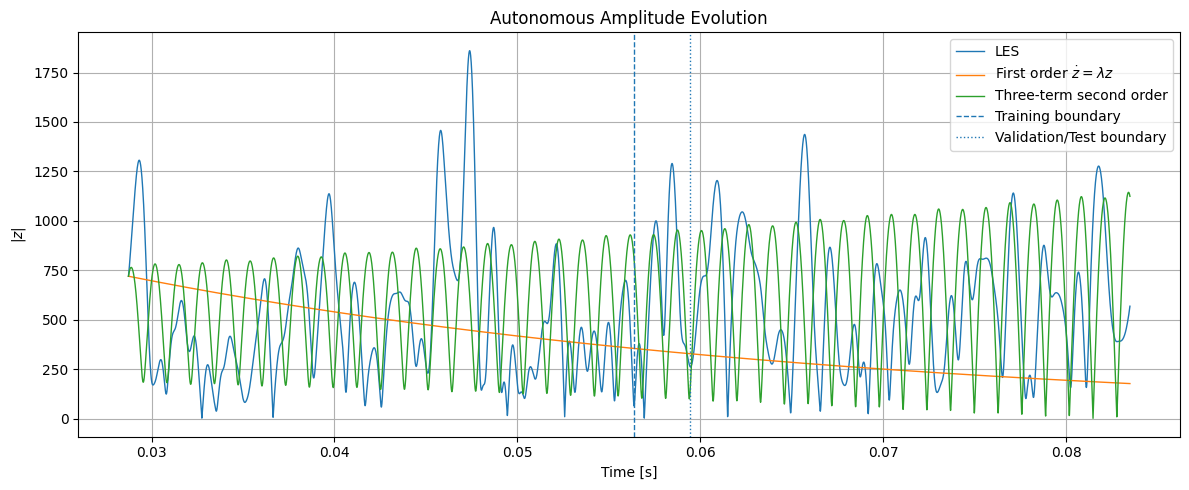

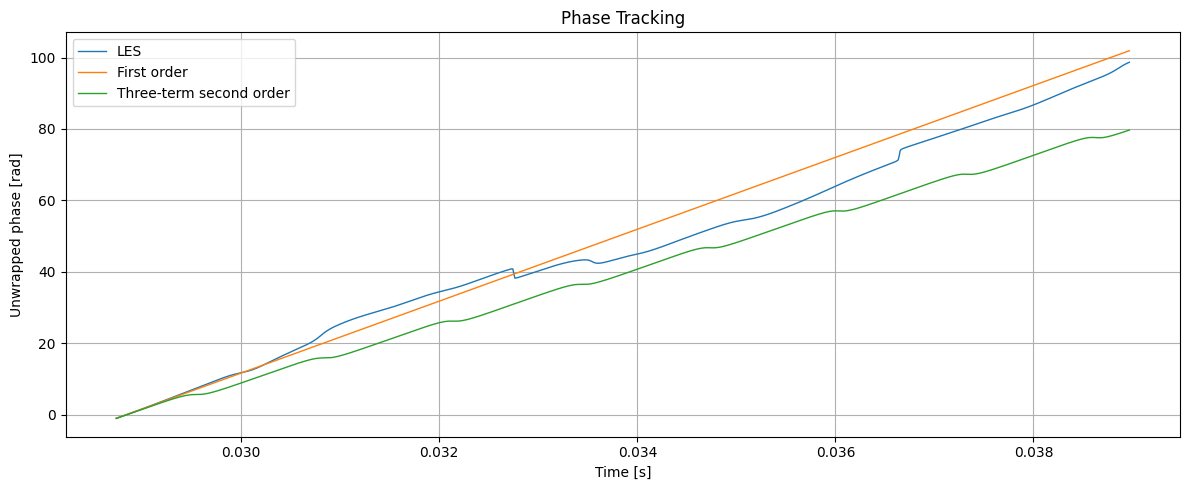

In [7]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


# ============================================================
# FIRST-ORDER COMPLEX CARRIER
#
#       dz/dt = lambda * z
#
# Solution:
#       z(t) = z0 * exp(lambda*t)
# ============================================================


def complex_nrmse(y_true, y_pred):
    rmse = np.sqrt(np.mean(np.abs(y_true - y_pred)**2))
    scale = np.sqrt(np.mean(np.abs(y_true - np.mean(y_true))**2))
    return rmse / scale


def complex_r2(y_true, y_pred):
    ss_res = np.sum(np.abs(y_true - y_pred)**2)
    ss_tot = np.sum(np.abs(y_true - np.mean(y_true))**2)
    return 1.0 - ss_res / ss_tot


# ============================================================
# 1. FIT FIRST-ORDER MODEL
#
# dz = lambda*z
# ============================================================

Theta_first = z_train[:, None]

lambda_fit, *_ = np.linalg.lstsq(
    Theta_first,
    dz_dt_train,
    rcond=None
)

lambda_fit = lambda_fit[0]

print("=" * 70)
print("FIRST-ORDER COMPLEX CARRIER")
print("=" * 70)

print(f"lambda = {lambda_fit.real:+.6e} {lambda_fit.imag:+.6e}j")
print(f"|lambda| = {abs(lambda_fit):.6e}")

# Physical interpretation
growth_rate = lambda_fit.real
omega = lambda_fit.imag
frequency = omega / (2 * np.pi)

print(f"\nGrowth/decay rate sigma = {growth_rate:.6e} s^-1")
print(f"Angular frequency omega = {omega:.6e} rad/s")
print(f"Frequency f = {frequency:.3f} Hz")


# ============================================================
# 2. VELOCITY / FIRST-DERIVATIVE FIT
# ============================================================

dz_pred_train = lambda_fit * z_train
dz_pred_test = lambda_fit * z_test

print("\nFIRST-DERIVATIVE FIT")
print("-" * 70)

print(
    f"Train: NRMSE = {complex_nrmse(dz_dt_train, dz_pred_train):.6f} | "
    f"R2 = {complex_r2(dz_dt_train, dz_pred_train):.6f}"
)

print(
    f"Test:  NRMSE = {complex_nrmse(dz_dt_test, dz_pred_test):.6f} | "
    f"R2 = {complex_r2(dz_dt_test, dz_pred_test):.6f}"
)


# ============================================================
# 3. IMPLIED ACCELERATION
#
# dz/dt = lambda*z
#
# therefore
#
# d2z/dt2 = lambda^2*z
# ============================================================

d2z_pred_train_first = (lambda_fit**2) * z_train
d2z_pred_test_first = (lambda_fit**2) * z_test

print("\nIMPLIED ACCELERATION FIT")
print("-" * 70)

print(
    f"Train: NRMSE = "
    f"{complex_nrmse(d2z_dt2_train, d2z_pred_train_first):.6f} | "
    f"R2 = {complex_r2(d2z_dt2_train, d2z_pred_train_first):.6f}"
)

print(
    f"Test:  NRMSE = "
    f"{complex_nrmse(d2z_dt2_test, d2z_pred_test_first):.6f} | "
    f"R2 = {complex_r2(d2z_dt2_test, d2z_pred_test_first):.6f}"
)


# ============================================================
# 4. CURRENT THREE-TERM SECOND-ORDER MODEL
#
# Refit in physical units for direct comparison
# ============================================================

Theta_three_train = np.column_stack([
    z_train,
    dz_dt_train,
    z_train**2,
])

Xi_three, *_ = np.linalg.lstsq(
    Theta_three_train,
    d2z_dt2_train,
    rcond=None
)

L_z, L_dz, G = Xi_three

Theta_three_test = np.column_stack([
    z_test,
    dz_dt_test,
    z_test**2,
])

d2z_pred_three_test = Theta_three_test @ Xi_three

print("\nTHREE-TERM SECOND-ORDER ACCELERATION")
print("-" * 70)

print(
    f"Test: NRMSE = "
    f"{complex_nrmse(d2z_dt2_test, d2z_pred_three_test):.6f} | "
    f"R2 = {complex_r2(d2z_dt2_test, d2z_pred_three_test):.6f}"
)


# ============================================================
# 5. AUTONOMOUS FIRST-ORDER ROLLOUT
#
# Since lambda is constant, exact integration is available:
#
# z(t) = z0 exp(lambda * (t-t0))
# ============================================================

t_eval = np.asarray(t_model)

z0 = z_train[0]

z_sim_first = z0 * np.exp(
    lambda_fit * (t_eval - t_eval[0])
)


# ============================================================
# 6. CURRENT SECOND-ORDER AUTONOMOUS ROLLOUT
# ============================================================

def ode_three_term(t, y):
    z = y[0] + 1j*y[1]
    dz = y[2] + 1j*y[3]

    d2z = (
        L_z * z
        + L_dz * dz
        + G * z**2
    )

    return [
        dz.real,
        dz.imag,
        d2z.real,
        d2z.imag,
    ]


y0 = [
    z_train[0].real,
    z_train[0].imag,
    dz_dt_train[0].real,
    dz_dt_train[0].imag,
]

sol_three = solve_ivp(
    ode_three_term,
    (t_eval[0], t_eval[-1]),
    y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-6,
    atol=1e-8,
)

z_sim_three = (
    sol_three.y[0]
    + 1j*sol_three.y[1]
)


# ============================================================
# 7. PHASE-SPACE COMPARISON
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    sharex=True,
    sharey=True
)

axes[0].hexbin(
    z_train.real,
    z_train.imag,
    gridsize=50,
    mincnt=1
)
axes[0].set_title("LES / SPOD Coordinate")

axes[1].hexbin(
    z_sim_first.real,
    z_sim_first.imag,
    gridsize=50,
    mincnt=1
)
axes[1].set_title(r"First Order: $\dot z=\lambda z$")

axes[2].hexbin(
    z_sim_three.real,
    z_sim_three.imag,
    gridsize=50,
    mincnt=1
)
axes[2].set_title(
    r"Second Order: $\ddot z=L_z z+L_{\dot z}\dot z+Gz^2$"
)

for ax in axes:
    ax.set_xlabel(r"$\Re(z)$")
    ax.grid(True)

axes[0].set_ylabel(r"$\Im(z)$")

plt.tight_layout()
plt.show()


# ============================================================
# 8. AMPLITUDE COMPARISON
# ============================================================

# Full LES / SPOD reference trajectory
z_ref = np.asarray(z_raw)

# Common available length
n_common = min(
    len(t_eval),
    len(z_ref),
    len(z_sim_first),
    len(z_sim_three)
)

t_plot = t_eval[:n_common]
z_ref_plot = z_ref[:n_common]
z_first_plot = z_sim_first[:n_common]
z_three_plot = z_sim_three[:n_common]


plt.figure(figsize=(12, 5))

plt.plot(
    t_plot,
    np.abs(z_ref_plot),
    label="LES",
    linewidth=1
)

plt.plot(
    t_plot,
    np.abs(z_first_plot),
    label=r"First order $\dot z=\lambda z$",
    linewidth=1
)

plt.plot(
    t_plot,
    np.abs(z_three_plot),
    label=r"Three-term second order",
    linewidth=1
)

# Mark train / validation boundaries
plt.axvline(
    t_model[train_end_idx],
    linestyle="--",
    linewidth=1,
    label="Training boundary"
)

plt.axvline(
    t_model[val_end_idx],
    linestyle=":",
    linewidth=1,
    label="Validation/Test boundary"
)

plt.xlabel("Time [s]")
plt.ylabel(r"$|z|$")
plt.title("Autonomous Amplitude Evolution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. PHASE COMPARISON
# ============================================================

phase_data = np.unwrap(np.angle(z_ref_plot))
phase_first = np.unwrap(np.angle(z_first_plot))
phase_three = np.unwrap(np.angle(z_three_plot))

n_phase = min(1000, n_common)

plt.figure(figsize=(12, 5))

plt.plot(
    t_plot[:n_phase],
    phase_data[:n_phase],
    label="LES",
    linewidth=1
)

plt.plot(
    t_plot[:n_phase],
    phase_first[:n_phase],
    label="First order",
    linewidth=1
)

plt.plot(
    t_plot[:n_phase],
    phase_three[:n_phase],
    label="Three-term second order",
    linewidth=1
)

plt.xlabel("Time [s]")
plt.ylabel("Unwrapped phase [rad]")
plt.title("Phase Tracking")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# this is for previous iteration and not required here so commented out
# # pure finite diff
# def get_derivatives(z, dt):
#     """Calculates 1st and 2nd time derivatives using pure central finite differences."""
#     # first derivative (velocity) [1/s]
#     dz_dt = np.gradient(z, dt)

#     # second derivative (acceleration) [1/s^2]
#     d2z_dt2 = np.gradient(dz_dt, dt)

#     return dz_dt, d2z_dt2


# # compute derivatives per partition
# dt = np.mean(np.diff(t_model))

# dz_dt_train, d2z_dt2_train = get_derivatives(z_train, dt)
# dz_dt_val, d2z_dt2_val = get_derivatives(z_val, dt)
# dz_dt_test, d2z_dt2_test = get_derivatives(z_test, dt)

# # feature Library (Theta) and Target (d2z_dt2)
# Theta_train = np.column_stack([z_train, dz_dt_train, z_train**2])

# # direct OLS solve on raw acceleration targets
# Xi, residuals, rank, s = np.linalg.lstsq(
#     Theta_train, d2z_dt2_train, rcond=None
# )

# # extract parameters
# L_z_discovered = Xi[0]  # Coefficient for z
# L_dz_discovered = Xi[1]  # Coefficient for z_dot
# G_discovered = Xi[2]  # Coefficient for z^2

# # Display
# print(f"L_z  (State Linear):    {L_z_discovered:.4e}")
# print(f"L_dz (Velocity Damping): {L_dz_discovered:.4e}")
# print(f"G    (Quadratic):       {G_discovered:.4e}")

# # verification of shapes
# print(
#     f"Train shapes: States {z_train.shape} | Theta {Theta_train.shape} | Target {d2z_dt2_train.shape}"
# )
# print(
#     f"Val shapes:   States {z_val.shape}   | Derivs {dz_dt_val.shape}   | Target {d2z_dt2_val.shape}"
# )
# print(
#     f"Test shapes:  States {z_test.shape}  | Derivs {dz_dt_test.shape}  | Target {d2z_dt2_test.shape}"
# )

In [9]:
# checking the mean and std

x_mean = np.array([z_train.real.mean(), z_train.imag.mean()])
x_std  = np.array([z_train.real.std(),  z_train.imag.std()])

print(f"x_mean: {x_mean}")
print(f"x_std:  {x_std}")

x_mean: [1.0740283 2.16792  ]
x_std:  [425.17947 424.21368]


In [10]:
# --- Metrics ---

# helper function to get ode prediction
def get_prediction(z, dz_dt, L_z, L_dz, G):
    """Predicts the second derivative (acceleration) using the discovered operators."""
    return (L_z * z) + (L_dz * dz_dt) + (G * (z**2))

# train eval
d2z_dt2_pred_train = get_prediction(z_train, dz_dt_train, L_z_discovered, L_dz_discovered, G_discovered)
res_train = d2z_dt2_train - d2z_dt2_pred_train

# relative error
rel_err_train = np.linalg.norm(res_train) / np.linalg.norm(d2z_dt2_train)

# NRMSE and R^2 (Variance Explained)
var_train = np.sum(np.abs(d2z_dt2_train - np.mean(d2z_dt2_train))**2)
nrmse_train = np.sqrt(np.sum(np.abs(res_train)**2) / var_train)
r2_train = 1 - (nrmse_train**2)

print(f"[TRAIN] Rel. Error: {rel_err_train * 100:5.2f}%, NRMSE: {nrmse_train:.4f}, R²: {r2_train * 100:5.2f}%")

# val eval
d2z_dt2_pred_val = get_prediction(z_val, dz_dt_val, L_z_discovered, L_dz_discovered, G_discovered)
res_val = d2z_dt2_val - d2z_dt2_pred_val

# relative error
rel_err_val = np.linalg.norm(res_val) / np.linalg.norm(d2z_dt2_val)

# NRMSE and R^2 (Variance Explained)
var_val = np.sum(np.abs(d2z_dt2_val - np.mean(d2z_dt2_val))**2)
nrmse_val = np.sqrt(np.sum(np.abs(res_val)**2) / var_val)
r2_val = 1 - (nrmse_val**2)

print(f"[VAL]   Rel. Error: {rel_err_val * 100:5.2f}%, NRMSE: {nrmse_val:.4f}, R²: {r2_val * 100:5.2f}%")

# test eval
d2z_dt2_pred_test = get_prediction(z_test, dz_dt_test, L_z_discovered, L_dz_discovered, G_discovered)
res_test = d2z_dt2_test - d2z_dt2_pred_test

# relative error
rel_err_test = np.linalg.norm(res_test) / np.linalg.norm(d2z_dt2_test)

# NRMSE and R^2 (Variance Explained)
var_test = np.sum(np.abs(d2z_dt2_test - np.mean(d2z_dt2_test))**2)
nrmse_test = np.sqrt(np.sum(np.abs(res_test)**2) / var_test)
r2_test = 1 - (nrmse_test**2)

print(f"[TEST]  Rel. Error: {rel_err_test * 100:5.2f}%, NRMSE: {nrmse_test:.4f}, R²: {r2_test * 100:5.2f}%")

[TRAIN] Rel. Error:  7.91%, NRMSE: 0.0791, R²: 99.37%
[VAL]   Rel. Error:  7.45%, NRMSE: 0.0745, R²: 99.45%
[TEST]  Rel. Error:  6.83%, NRMSE: 0.0683, R²: 99.53%


In [11]:
# --- integration ---
def ode(t, y):
    # Unpack the 4D state vector (z_real, z_imag, dz_real, dz_imag)
    z = y[0] + 1j * y[1]
    dz_dt = y[2] + 1j * y[3]
    
    # second derivative (acceleration) using discovered operators
    d2z_dt2 = (L_z_discovered * z) + (L_dz_discovered * dz_dt) + (G_discovered * (z**2))
    
    # return the derivatives of the 4 state variables:
    # [d(z_real)/dt, d(z_imag)/dt, d(dz_real)/dt, d(dz_imag)/dt]
    return [dz_dt.real, dz_dt.imag, d2z_dt2.real, d2z_dt2.imag]

# full dataset time
t_eval_full = t_model
t_span_full = (t_eval_full[0], t_eval_full[-1])

# concat
z_full = np.concatenate([z_train, z_val, z_test])
dz_dt_full = np.concatenate([dz_dt_train, dz_dt_val, dz_dt_test])

# we need both the initial amplitude AND initial velocity for initial state 
initial_state_full = [
    z_full[0].real, 
    z_full[0].imag, 
    dz_dt_full[0].real, 
    dz_dt_full[0].imag
]

from scipy.integrate import solve_ivp

sol_full = solve_ivp(
    ode, 
    t_span_full, 
    initial_state_full, 
    t_eval=t_eval_full, 
    method='RK45', 
    rtol=1e-8, 
    atol=1e-10
)

# rollout
z_pred_full = sol_full.y[0] + 1j * sol_full.y[1]

# --- Metrics ---
# Train: 0 to train_end_idx
# Test: val_end_idx to End
z_true_train = z_full[:train_end_idx]
z_pred_train = z_pred_full[:train_end_idx]

z_true_test = z_full[val_end_idx:]
z_pred_test = z_pred_full[val_end_idx:]

def get_envelope_r2(true, pred):
    true_env, pred_env = np.abs(true), np.abs(pred)
    # Variance-explained formulation: R^2 = 1 - (SS_res / SS_tot)
    return 1 - (np.sum((true_env - pred_env)**2) / 
                np.sum((true_env - np.mean(true_env))**2))

envelope_r2_train = get_envelope_r2(z_true_train, z_pred_train)
envelope_r2_test  = get_envelope_r2(z_true_test, z_pred_test)

print("="*65)
print(f"Train Wave Envelope Variance Explained (R²): {envelope_r2_train * 100:.2f}%")
print(f"Test Wave Envelope Variance Explained (R²):  {envelope_r2_test * 100:.2f}%")
print("="*65)

# Energy Captured
true_var_test = np.var(z_true_test)
pred_var_test = np.var(z_pred_test)
energy_captured_test = (pred_var_test / true_var_test) * 100

print(f"Total Structural Test Energy Captured:       {energy_captured_test:.2f}%")
print("="*65)

Train Wave Envelope Variance Explained (R²): -49.17%
Test Wave Envelope Variance Explained (R²):  -159.44%
Total Structural Test Energy Captured:       126.56%


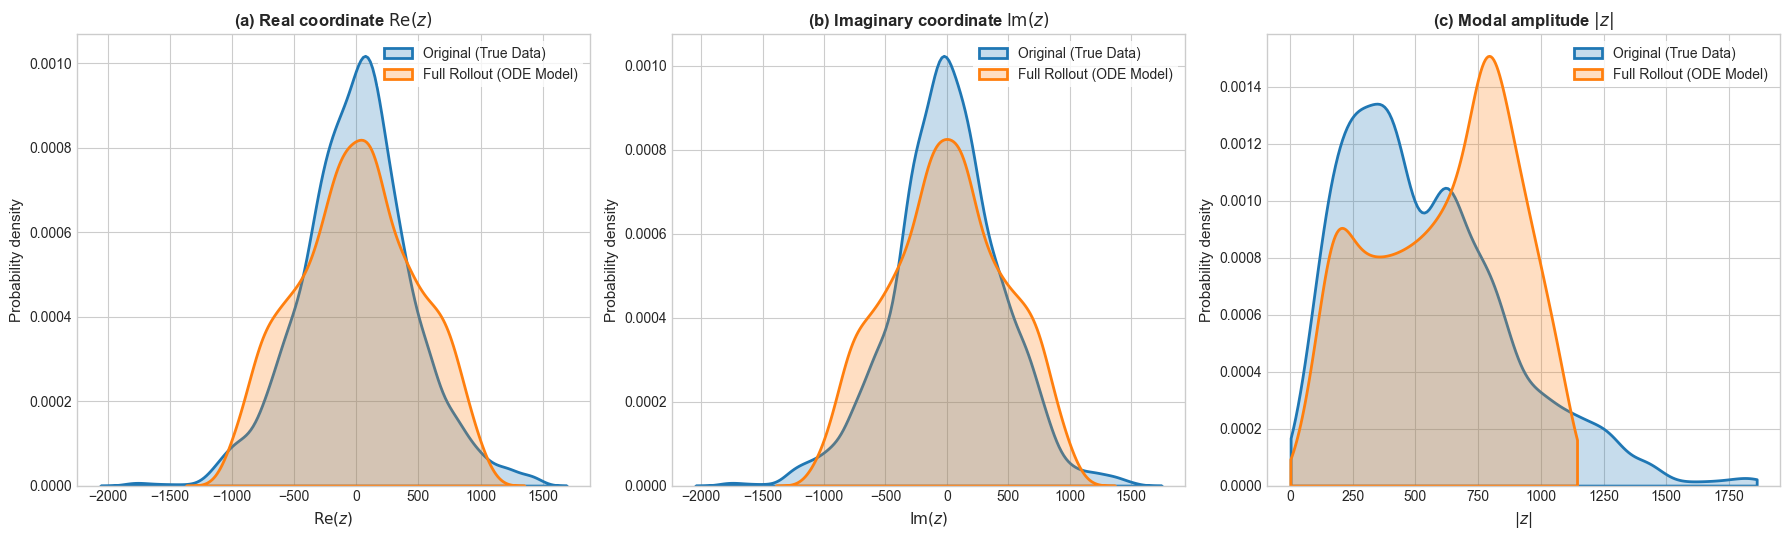

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

true_signal = np.asarray(z_full).ravel()
pred_signal = np.asarray(z_pred_full).ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

panels = [
    (np.real, r'(a) Real coordinate $\operatorname{Re}(z)$',
     r'$\operatorname{Re}(z)$'),
    (np.imag, r'(b) Imaginary coordinate $\operatorname{Im}(z)$',
     r'$\operatorname{Im}(z)$'),
    (np.abs, r'(c) Modal amplitude $|z|$',
     r'$|z|$')
]

for ax, (transform, title, xlabel) in zip(axes, panels):
    for signal, label, color in [
        (true_signal, 'Original (True Data)', '#1f77b4'),
        (pred_signal, 'Full Rollout (ODE Model)', '#ff7f0e')
    ]:
        sns.kdeplot(
            x=transform(signal),
            ax=ax,
            label=label,
            fill=True,
            alpha=0.25,
            color=color,
            linewidth=2,
            **({'cut': 0, 'clip': (0, None)}
               if transform is np.abs else {})
        )

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Probability density', fontsize=11)
    ax.legend(frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.savefig('kde_distribution_comparison.png', dpi=300,
            bbox_inches='tight')
plt.show()

<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:34: SyntaxWarning: invalid escape sequence '\m'
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_29858/2932045485.py:19: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_xlabel('Real Part $\mathcal{R}(z)$')
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_29858/2932045485.py:20: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_ylabel('Imaginary Part $\mathcal{I}(z)$')
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_29858/2932045485.py:33: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_xlabel('Real Part $\mathcal{R}(z)$')
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipyk

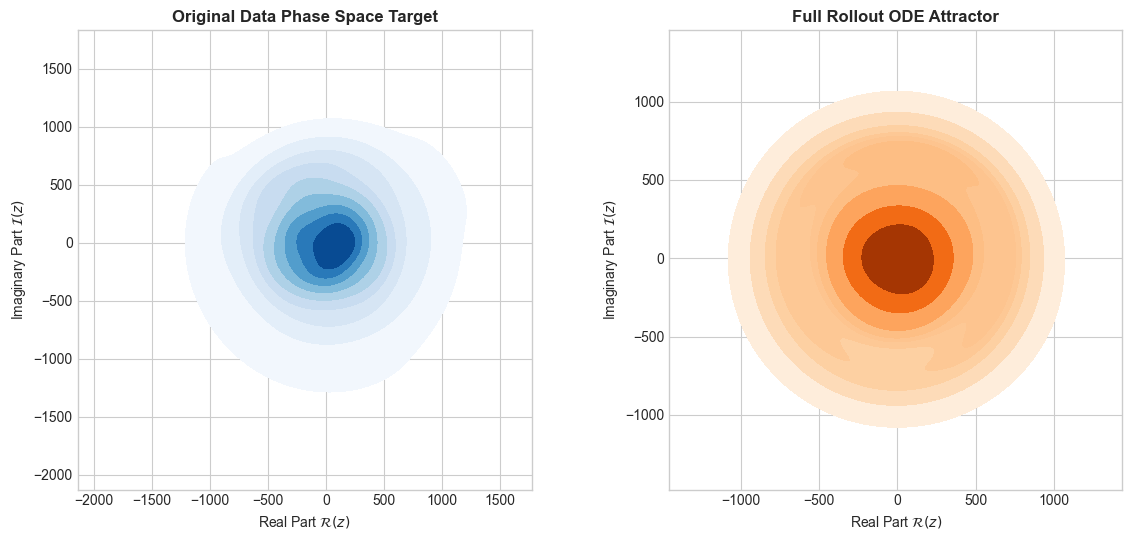

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

# 2D Density for Original Data (z_full)
sns.kdeplot(
    x=np.real(z_full), 
    y=np.imag(z_full), 
    ax=axes[0], 
    cmap="Blues", 
    fill=True, 
    thresh=0.05
)
axes[0].set_title('Original Data Phase Space Target', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Real Part $\mathcal{R}(z)$')
axes[0].set_ylabel('Imaginary Part $\mathcal{I}(z)$')
axes[0].set_aspect('equal', 'box')

# 2D Density for the ODE Rollout (z_pred_full)
sns.kdeplot(
    x=np.real(z_pred_full), 
    y=np.imag(z_pred_full), 
    ax=axes[1], 
    cmap="Oranges", 
    fill=True, 
    thresh=0.05
)
axes[1].set_title('Full Rollout ODE Attractor', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Real Part $\mathcal{R}(z)$')
axes[1].set_ylabel('Imaginary Part $\mathcal{I}(z)$')
axes[1].set_aspect('equal', 'box')

plt.tight_layout()
plt.savefig('kde_phase_space_comparison.png', dpi=300)
plt.show()

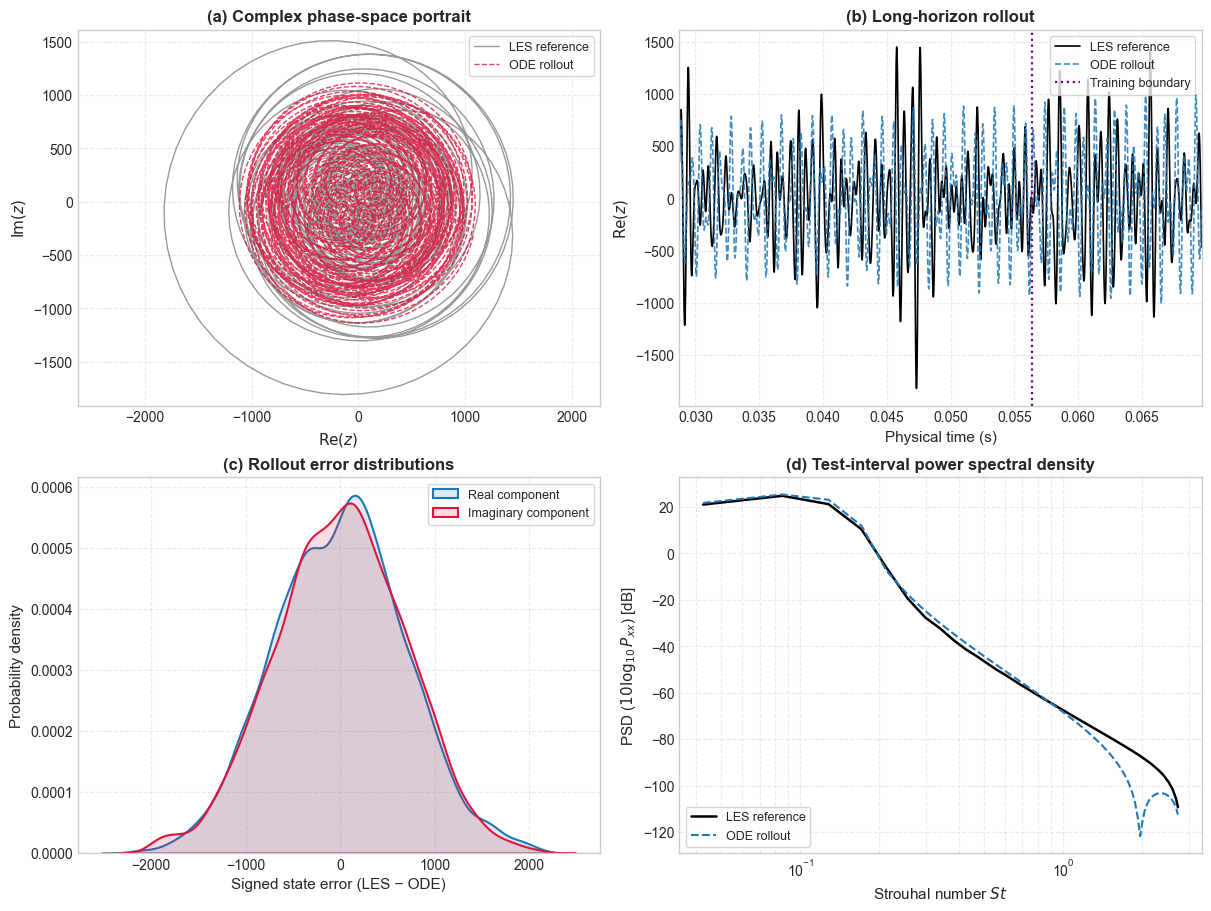

Saved: sindy_model_evaluation.png
Saved: sindy_model_evaluation.pdf


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from find_spectrum import hann2, pwelch2

# =====================================================================
# FIGURE STYLE AND LAYOUT
# =====================================================================
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'sans-serif',
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
})

fig, axs = plt.subplots(
    2, 2,
    figsize=(12, 9),
    layout='constrained'
)
axs = axs.ravel()

# =====================================================================
# 1. COMPLEX PHASE-SPACE PORTRAIT
# =====================================================================
ax = axs[0]

ax.plot(
    z_full.real,
    z_full.imag,
    label='LES reference',
    color='black',
    alpha=0.4,
    lw=1
)

ax.plot(
    z_pred_full.real,
    z_pred_full.imag,
    label='ODE rollout',
    color='crimson',
    linestyle='--',
    alpha=0.8,
    lw=1
)

ax.set_title("(a) Complex phase-space portrait", fontweight='bold')
ax.set_xlabel(r"$\mathrm{Re}(z)$")
ax.set_ylabel(r"$\mathrm{Im}(z)$")
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best', frameon=True)

# =====================================================================
# 2. LONG-HORIZON ROLLOUT
# =====================================================================
ax = axs[1]

plot_len = min(
    4000,
    len(z_full),
    len(z_pred_full),
    len(t_model)
)
time_axis = t_model[:plot_len]

ax.plot(
    time_axis,
    z_full[:plot_len].real,
    label='LES reference',
    color='black',
    lw=1.2
)

ax.plot(
    time_axis,
    z_pred_full[:plot_len].real,
    label='ODE rollout',
    color='#1f77b4',
    linestyle='--',
    lw=1.2,
    alpha=0.85
)

if 0 <= train_end_idx < plot_len:
    train_boundary = t_model[train_end_idx]
    ax.axvline(
        x=train_boundary,
        color='purple',
        linestyle=':',
        lw=1.6,
        label='Training boundary'
    )

ax.set_title("(b) Long-horizon rollout", fontweight='bold')
ax.set_xlabel("Physical time (s)")
ax.set_ylabel(r"$\mathrm{Re}(z)$")
ax.set_xlim(time_axis[0], time_axis[-1])
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right', frameon=True)

# =====================================================================
# 3. KDE OF ROLLOUT STATE ERRORS
# =====================================================================
ax = axs[2]

residuals = z_full - z_pred_full
res_real = residuals.real
res_imag = residuals.imag

sns.kdeplot(
    res_real,
    ax=ax,
    label='Real component',
    color='#1f77b4',
    fill=True,
    alpha=0.15,
    linewidth=1.5
)

sns.kdeplot(
    res_imag,
    ax=ax,
    label='Imaginary component',
    color='crimson',
    fill=True,
    alpha=0.15,
    linewidth=1.5
)

ax.set_title("(c) Rollout error distributions", fontweight='bold')
ax.set_xlabel("Signed state error (LES − ODE)")
ax.set_ylabel("Probability density")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper right', frameon=True)

# =====================================================================
# 4. POWER SPECTRAL DENSITY — TEST PARTITION
# =====================================================================
ax = axs[3]

dt = np.mean(np.diff(t_model))
fs = 1.0 / dt

nFFT = 128
window = hann2(nFFT)

Pxx_true, F_true = pwelch2(
    z_full[val_end_idx:],
    nFFT,
    fs,
    window
)

Pxx_pred, F_pred = pwelch2(
    z_pred_full[val_end_idx:],
    nFFT,
    fs,
    window
)

Dj = 0.0169
Uj = 302.0

Pxx_true = np.asarray(Pxx_true).real.ravel()
Pxx_pred = np.asarray(Pxx_pred).real.ravel()
F_true = np.asarray(F_true).ravel()
F_pred = np.asarray(F_pred).ravel()

St_true = F_true * Dj / Uj
St_pred = F_pred * Dj / Uj

# Positive frequencies only on the logarithmic horizontal axis.
positive_true = St_true > 0
positive_pred = St_pred > 0

# Prevent log10(0) without changing positive spectral values.
tiny = np.finfo(float).tiny
psd_true_db = 10 * np.log10(np.maximum(Pxx_true, tiny))
psd_pred_db = 10 * np.log10(np.maximum(Pxx_pred, tiny))

ax.semilogx(
    St_true[positive_true],
    psd_true_db[positive_true],
    label='LES reference',
    color='black',
    lw=1.8
)

ax.semilogx(
    St_pred[positive_pred],
    psd_pred_db[positive_pred],
    label='ODE rollout',
    color='#1f77b4',
    linestyle='--',
    lw=1.5
)

ax.set_title("(d) Test-interval power spectral density",
             fontweight='bold')
ax.set_xlabel(r"Strouhal number $St$")
ax.set_ylabel(r"PSD ($10\log_{10}P_{xx}$) [dB]")
ax.grid(True, which='both', linestyle='--', alpha=0.4)
ax.legend(loc='lower left', frameon=True)

# =====================================================================
# SAVE FIGURE
# =====================================================================
fig.savefig(
    'sindy_model_evaluation.png',
    dpi=400,
    bbox_inches='tight'
)

fig.savefig(
    'sindy_model_evaluation.pdf',
    bbox_inches='tight'
)

plt.show()

print("Saved: sindy_model_evaluation.png")
print("Saved: sindy_model_evaluation.pdf")

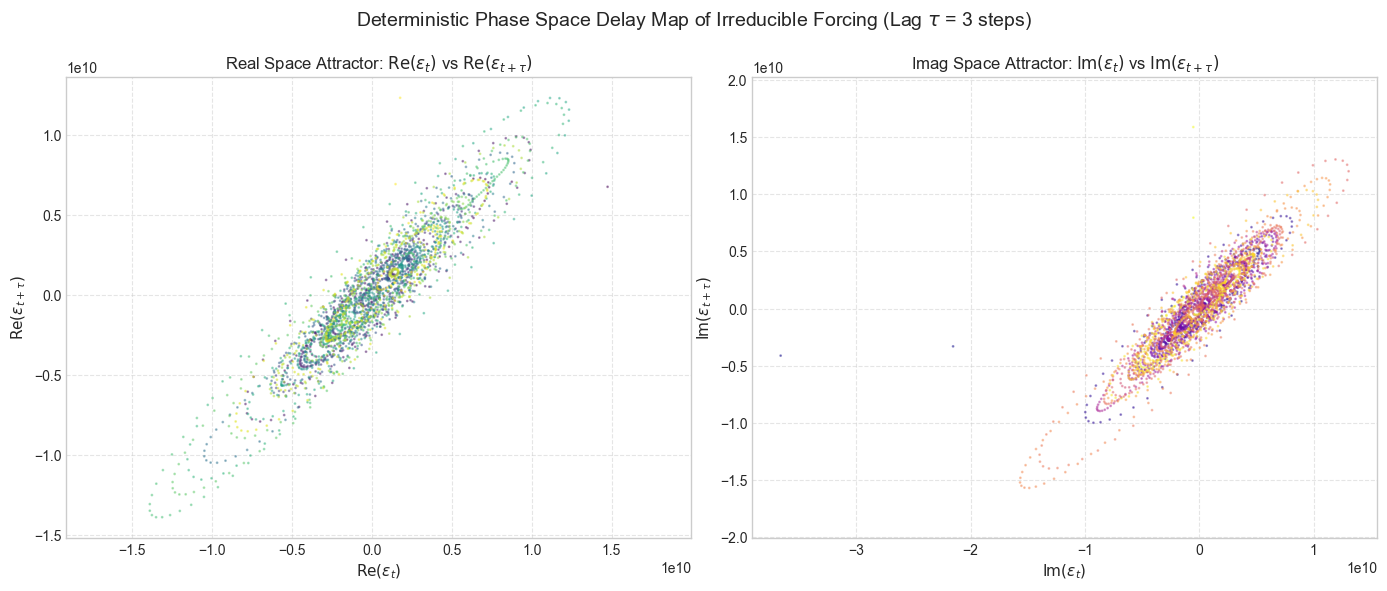

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# compute forcing term (the residual of your 2nd-order ODE)
# predict the acceleration (second derivative)
d2z_dt2_pred = (L_z_discovered * z_train) + (L_dz_discovered * dz_dt_train) + (G_discovered * (z_train**2))

# irreducible forcing is the error in the acceleration
epsilon_train = d2z_dt2_train - d2z_dt2_pred

# time-delay Embedding setup
delay_lag = 3 
e_real = epsilon_train.real
e_imag = epsilon_train.imag

# prepare segments for plotting
e_real_current, e_real_delayed = e_real[:-delay_lag], e_real[delay_lag:]
e_imag_current, e_imag_delayed = e_imag[:-delay_lag], e_imag[delay_lag:]

# setup plot
fig_delay, axs_delay = plt.subplots(1, 2, figsize=(14, 6))
plt.rcParams.update({'font.size': 11, 'font.family': 'sans-serif'})

# Axis 1: Real Component Delay Portrait
ax = axs_delay[0]
ax.scatter(e_real_current, e_real_delayed, c=np.arange(len(e_real_current)), 
           cmap='viridis', s=1, alpha=0.4, label='Temporal Trajectory')
ax.set_title(r"Real Space Attractor: $\mathrm{Re}(\epsilon_t)$ vs $\mathrm{Re}(\epsilon_{t+\tau})$")
ax.set_xlabel(r"$\mathrm{Re}(\epsilon_t)$")
ax.set_ylabel(r"$\mathrm{Re}(\epsilon_{t+\tau})$")
ax.grid(True, linestyle='--', alpha=0.5)
ax.axis('equal')

# Axis 2: Imaginary Component Delay Portrait
ax = axs_delay[1]
ax.scatter(e_imag_current, e_imag_delayed, c=np.arange(len(e_imag_current)), 
           cmap='plasma', s=1, alpha=0.4, label='Temporal Trajectory')
ax.set_title(r"Imag Space Attractor: $\mathrm{Im}(\epsilon_t)$ vs $\mathrm{Im}(\epsilon_{t+\tau})$")
ax.set_xlabel(r"$\mathrm{Im}(\epsilon_t)$")
ax.set_ylabel(r"$\mathrm{Im}(\epsilon_{t+\tau})$")
ax.grid(True, linestyle='--', alpha=0.5)
ax.axis('equal')

plt.suptitle(f"Deterministic Phase Space Delay Map of Irreducible Forcing (Lag $\\tau$ = {delay_lag} steps)", fontsize=14, y=0.98)
plt.tight_layout()

# Save and display (make sure %matplotlib inline is at the top of your notebook if you get the Agg warning!)
plt.savefig('epsilon_phase_space_delay_map.png', dpi=300)
plt.show()

<>:38: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\m'
<>:38: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\m'
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_29858/2867220901.py:38: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel("Theoretical $\mathrm{Im}(\epsilon)$ (via Hilbert Transform)")
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_29858/2867220901.py:39: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel("Actual $\mathrm{Im}(\epsilon)$")


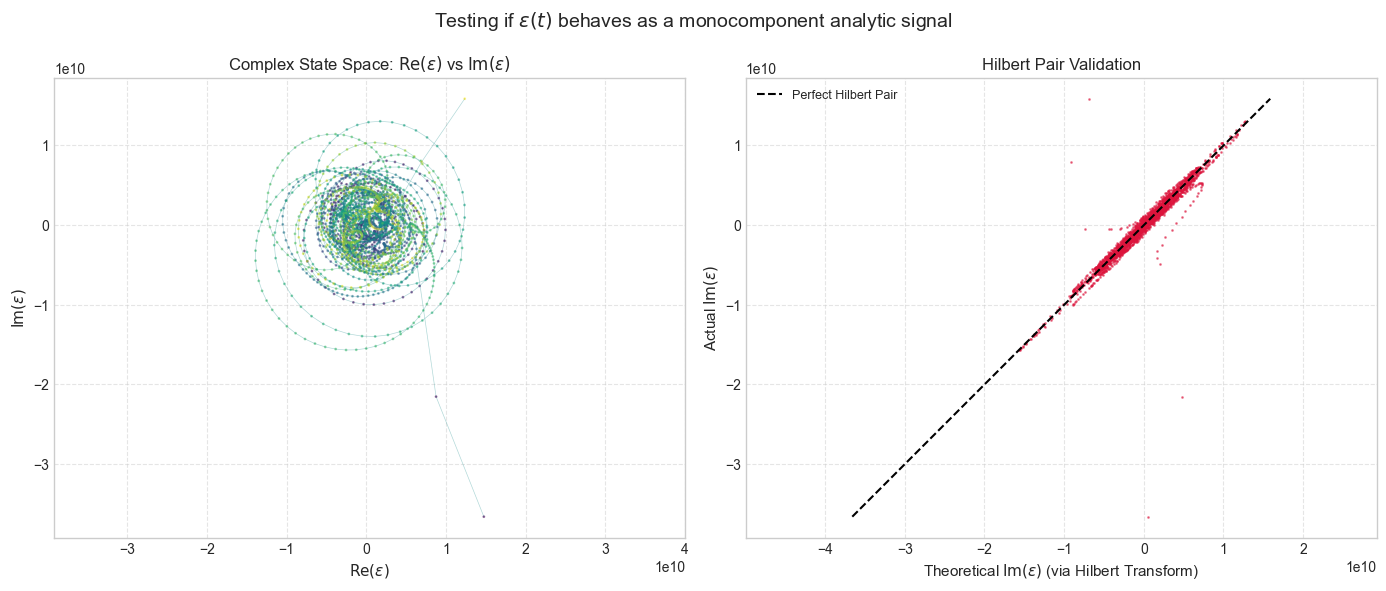

Correlation between actual and theoretical Hilbert imaginary part: 0.9552


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert

# need to check if the eps is hilbert pair or not for validation

# hilbert transform of the real part
# is the original signal and the imaginary part is the Hilbert transform.
analytic_epsilon = hilbert(epsilon_train.real)
theoretical_imag = analytic_epsilon.imag
actual_imag = epsilon_train.imag

# plot
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
plt.rcParams.update({'font.size': 11, 'font.family': 'sans-serif'})

# Axis 1: Complex State Space
ax = axs[0]
ax.plot(epsilon_train.real, actual_imag, color='teal', alpha=0.3, lw=0.5)
ax.scatter(epsilon_train.real, actual_imag, c=np.arange(len(epsilon_train)), 
           cmap='viridis', s=1, alpha=0.5)
ax.set_title(r"Complex State Space: $\mathrm{Re}(\epsilon)$ vs $\mathrm{Im}(\epsilon)$")
ax.set_xlabel(r"$\mathrm{Re}(\epsilon)$")
ax.set_ylabel(r"$\mathrm{Im}(\epsilon)$")
ax.grid(True, linestyle='--', alpha=0.5)
ax.axis('equal')

# Axis 2: Hilbert Pair Validation
ax = axs[1]
ax.scatter(theoretical_imag, actual_imag, c='crimson', s=1, alpha=0.5)

# plot the perfect correlation line
lims = [min(np.min(theoretical_imag), np.min(actual_imag)), 
        max(np.max(theoretical_imag), np.max(actual_imag))]
ax.plot(lims, lims, 'k--', lw=1.5, label='Perfect Hilbert Pair')

ax.set_title("Hilbert Pair Validation")
ax.set_xlabel("Theoretical $\mathrm{Im}(\epsilon)$ (via Hilbert Transform)")
ax.set_ylabel("Actual $\mathrm{Im}(\epsilon)$")
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
ax.axis('equal')

plt.suptitle(r"Testing if $\epsilon(t)$ behaves as a monocomponent analytic signal", fontsize=14, y=0.98)
plt.tight_layout()
plt.savefig('epsilon_hilbert_validation.png', dpi=300)
plt.show()

# correlation check
correlation = np.corrcoef(theoretical_imag, actual_imag)[0, 1]
print(f"Correlation between actual and theoretical Hilbert imaginary part: {correlation:.4f}")

In [17]:
%matplotlib inline

Dominant Epsilon Real Frequency:      572.19 Hz
Dominant Epsilon Imaginary Frequency: 572.19 Hz


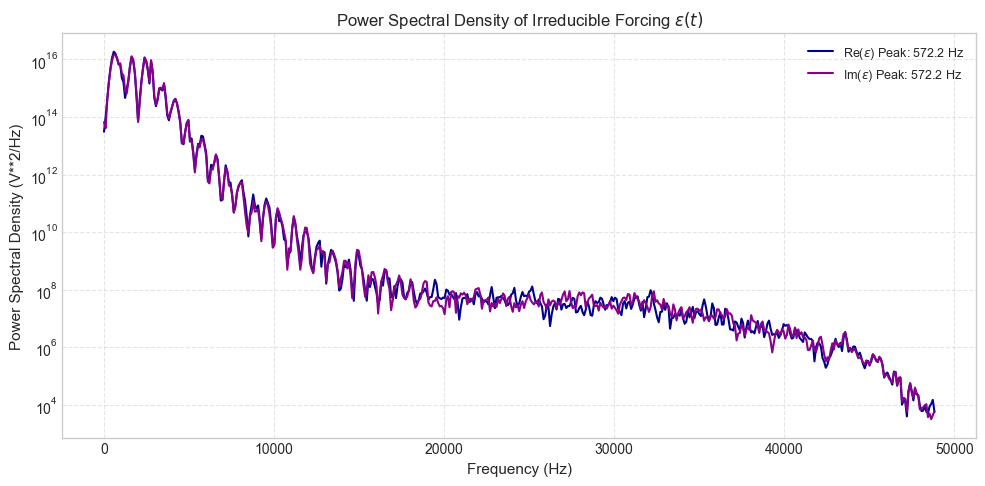

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# fs is the sampling frequency (Hz)
fs = 1.0 / dt  

# Power Spectral Density via Welch method
frequencies_re, psd_re = welch(epsilon_train.real, fs=fs, nperseg=1024)
frequencies_im, psd_im = welch(epsilon_train.imag, fs=fs, nperseg=1024)

# dominant peak frequencies
peak_freq_re = frequencies_re[np.argmax(psd_re)]
peak_freq_im = frequencies_im[np.argmax(psd_im)]

print(f"Dominant Epsilon Real Frequency:      {peak_freq_re:.2f} Hz")
print(f"Dominant Epsilon Imaginary Frequency: {peak_freq_im:.2f} Hz")

# plot spectrum
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(frequencies_re, psd_re, color='darkblue', lw=1.5, label=f'Re($\\epsilon$) Peak: {peak_freq_re:.1f} Hz')
ax.semilogy(frequencies_im, psd_im, color='darkmagenta', lw=1.5, label=f'Im($\\epsilon$) Peak: {peak_freq_im:.1f} Hz')

ax.set_title("Power Spectral Density of Irreducible Forcing $\\epsilon(t)$")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power Spectral Density (V**2/Hz)")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

In [19]:
frequencies_re, psd_re = welch(epsilon_train.real, fs=fs, nperseg=512, noverlap=256)
frequencies_im, psd_im = welch(epsilon_train.imag, fs=fs, nperseg=512, noverlap=256)

def band_centroid(freqs, psd, band):
    mask = (freqs >= band[0]) & (freqs <= band[1])
    return np.sum(freqs[mask] * psd[mask]) / np.sum(psd[mask])

fund_re = band_centroid(frequencies_re, psd_re, (700, 1600))
harm_re = band_centroid(frequencies_re, psd_re, (1900, 2700))
fund_im = band_centroid(frequencies_im, psd_im, (700, 1600))
harm_im = band_centroid(frequencies_im, psd_im, (1900, 2700))

print(f"Re: fundamental centroid = {fund_re:.1f} Hz, harmonic centroid = {harm_re:.1f} Hz, ratio = {harm_re/fund_re:.3f}")
print(f"Im: fundamental centroid = {fund_im:.1f} Hz, harmonic centroid = {harm_im:.1f} Hz, ratio = {harm_im/fund_im:.3f}")

Re: fundamental centroid = 1070.7 Hz, harmonic centroid = 2435.5 Hz, ratio = 2.275
Im: fundamental centroid = 1076.7 Hz, harmonic centroid = 2436.4 Hz, ratio = 2.263


In [20]:
############ ML Training ################

In [21]:
# # # epsilon is deterministic, non-local and has memory
# # # we use property of FNO here as non-local kernel
import torch
import torch.nn as nn
import torch.nn.functional as F


torch.manual_seed(42)

# class SpectralConv1d(nn.Module):
#     def __init__(self, in_channels, out_channels, modes):
#         super(SpectralConv1d, self).__init__()
#         self.in_channels  = in_channels
#         self.out_channels = out_channels
#         self.modes        = modes

#         scale = (1.0 / (in_channels * out_channels)) ** 0.5
#         self.weights = nn.Parameter(
#             scale * torch.randn(in_channels, out_channels, self.modes, dtype=torch.complex128)
#         )

#     def forward(self, x):
#         x_ft         = torch.fft.rfft(x, norm="ortho")
#         weights_cast = self.weights.to(x_ft.dtype)

#         out_ft = torch.einsum(
#             "bix,iox->box",
#             x_ft[:, :, :self.modes],
#             weights_cast
#         )

#         expected_size = x.size(-1) // 2 + 1
#         padding_len   = expected_size - self.modes
#         if padding_len > 0:
#             out_ft = F.pad(out_ft, (0, padding_len))

#         x = torch.fft.irfft(out_ft, n=x.size(-1), norm="ortho")
#         return x

    
# class FNO1d(nn.Module):
#     def __init__(self, L_scalar, N1_scalar, dt, steps=8, modes=16, width=64, num_layers=4):
#         super().__init__()
#         self.dt = dt
#         self.steps = steps
#         self.modes = modes
#         self.width = width

#         self.register_buffer('L_tensor', torch.tensor(L_scalar, dtype=torch.complex64))
#         self.register_buffer('N1_tensor', torch.tensor(N1_scalar, dtype=torch.complex64))
#         # self.L_tensor = nn.Parameter(torch.tensor(L_scalar, dtype=torch.complex64))
#         # self.N1_tensor = nn.Parameter(torch.tensor(N1_scalar, dtype=torch.complex64))

#         self.lift = nn.Sequential(
#             nn.Linear(3, self.width),
#             nn.GELU(),
#             nn.Linear(self.width, self.width)
#         )

#         self.spectral_layers = nn.ModuleList([
#             SpectralConv1d(self.width, self.width, self.modes) for _ in range(num_layers)
#         ])
#         self.skip_layers = nn.ModuleList([
#             nn.Conv1d(self.width, self.width, 1) for _ in range(num_layers)
#         ])
#         self.norm_layers = nn.ModuleList([
#             nn.InstanceNorm1d(self.width, affine=True) for _ in range(num_layers)
#         ])

#         self.fc1 = nn.Linear(self.width, 128)
#         # lets capture the mean and std
#         # ode solves for psd and phase, so only need to distort the kde
#         self.fc2 = nn.Linear(128, 2)

#         nn.init.xavier_uniform_(self.fc2.weight, gain=1e-4) 
#         nn.init.zeros_(self.fc2.bias)


#     def rk4_step(self, z, dt, rhs_func):
#         k1 = rhs_func(z)
#         k2 = rhs_func(z + 0.5 * dt * k1)
#         k3 = rhs_func(z + 0.5 * dt * k2)
#         k4 = rhs_func(z + dt * k3)
#         return z + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    
#     # re and im are hilbert pairs, so reducing the search space
#     def hilbert(self, x):
#         # x: [B, steps], real
#         N = x.shape[-1]
#         Xf = torch.fft.rfft(x, dim=-1)       # [B, N//2+1]
#         # multiply by -i*sign(f) to get imaginary part of analytic signal
#         h = torch.ones(N // 2 + 1, device=x.device)
#         h[0] = 0          # DC component = 0
#         h[-1] = 0         # Nyquist = 0
#         Xf_shifted = Xf * h * (-1j)
#         return torch.fft.irfft(Xf_shifted, n=N, dim=-1)
    
#     # def low_pass_filter(self, x):
#     #     """Strictly truncates high frequencies to match spectral layers."""
#     #     x_ft = torch.fft.rfft(x, norm='ortho')
#     #     out_ft = torch.zeros_like(x_ft)
#     #     out_ft[:, :, :self.modes] = x_ft[:, :, :self.modes]
#     #     return torch.fft.irfft(out_ft, n=x.size(-1), norm='ortho')

#     def forward(self, x):
#         # ─── FNO ENVELOPE TRACKING ───
#         h = x.permute(0, 2, 1)         # [B, T_hist, 2]
#         h = self.add_temporal_grid(h)  # [B, T_hist, 3]
#         h = self.lift(h)               # [B, T_hist, width]
#         h = h.permute(0, 2, 1)         # [B, width, T_hist]

#         for spec, skip, norm in zip(self.spectral_layers, self.skip_layers, self.norm_layers):
#             h = h + F.gelu(norm(spec(h) + skip(h)))   # [B, width, T_hist]

#         # Compress temporal dimension smoothly to generate global context
#         h_latent = torch.mean(h, dim=-1) # [B, width]
#         h_latent = F.gelu(self.fc1(h_latent))  # [B, 128]

#         # Extract sequence statistics
#         stats = self.fc2(h_latent).view(-1, self.steps, 2)  # [B, steps, 2]
        
#         # Now mean and std vary continuously over every point in time!
#         pred_mean = stats[:, :, 0]  # [B, steps]
#         pred_std  = F.softplus(stats[:, :, 1]) + 1e-5  # [B, steps]

#         # ─── PURE PHYSICS ROLLOUT ─────────────────────────────────────
#         real_init = x[:, 0, -1]
#         imag_init = x[:, 1, -1]
#         z_state = torch.complex(real_init, imag_init)

#         trajectory = []
#         for i in range(self.steps):
#             def rhs(z):
#                 return self.L_tensor * z + self.N1_tensor * (z ** 2)
#             z_state = self.rk4_step(z_state, self.dt, rhs)
#             trajectory.append(z_state)

#         stacked_ode = torch.stack(trajectory, dim=1)  # [B, steps]
#         ode_out = torch.stack([stacked_ode.real, stacked_ode.imag], dim=1)  # [B, 2, steps]

#         return ode_out, pred_mean, pred_std


#     def add_temporal_grid(self, x):
#         batch_size, seq_len, _ = x.shape
#         grid = torch.linspace(0.0, 1.0, steps=seq_len,
#         dtype=torch.float64, device=x.device)
#         grid = grid.view(1, seq_len, 1).expand(batch_size, -1, -1)
#         return torch.cat((x, grid), dim=-1)


In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DualBranchSpectralConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, modes, pad_size=32):
        super(DualBranchSpectralConv1d, self).__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.modes        = modes
        self.pad_size     = pad_size  # number of grid points to pad on each side

        scale = (1.0 / (in_channels * out_channels)) ** 0.5
        self.weights = nn.Parameter(
            scale * torch.randn(in_channels, out_channels, self.modes, dtype=torch.complex128)
        )

    def forward(self, h_hist, h_ode):
        batch_size = h_hist.shape[0]

        # concatenate history and ODE states along the channel dimension
        h_joint = torch.cat([h_hist, h_ode], dim=1)  # [batch, channels, spatial_grid]
        
        # spatial padding padding to create a periodic buffer zone for the FFT
        h_padded = F.pad(h_joint, (self.pad_size, self.pad_size), mode='reflect')
        padded_len = h_padded.size(-1)
        h_ft = torch.fft.rfft(h_padded, norm="ortho")

        out_ft = torch.zeros(
            batch_size, self.out_channels, padded_len // 2 + 1,
            device=h_padded.device, dtype=torch.complex128
        )
        out_ft[:, :, :self.modes] = torch.einsum(
            "bix,iox->box",
            h_ft[:, :, :self.modes],
            self.weights
        )

        output_padded = torch.fft.irfft(out_ft, n=padded_len, norm="ortho")

        # strip the padding off to return to the original spatial domain size
        output = output_padded[..., self.pad_size: -self.pad_size]

        return output

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchdiffeq import odeint_adjoint as odeint

# ─── UPDATED 2ND-ORDER ODE SOLVER ─────────────────────────────────────
class ODEField(nn.Module):
    def __init__(self, L_z_tensor, L_dz_tensor, G_tensor):
        super().__init__()
        self.L_z_tensor = L_z_tensor
        self.L_dz_tensor = L_dz_tensor
        self.G_tensor = G_tensor

    def forward(self, t, state):
        # state is stacked [position, velocity] -> shape: [2, Batch_size]
        z = state[0]
        dz_dt = state[1]
        
        # 2nd-Order SINDy equation: acceleration = L_z(z) + L_dz(dz_dt) + G(z^2)
        d2z_dt2 = (self.L_z_tensor * z) + (self.L_dz_tensor * dz_dt) + (self.G_tensor * (z ** 2))
        
        # Return state derivative: [velocity, acceleration]
        return torch.stack([dz_dt, d2z_dt2], dim=0)


class FNO1d(nn.Module):
    # Notice the updated initial parameters (L_z, L_dz, G)
    def __init__(self, L_z_scalar, L_dz_scalar, G_scalar, dt, norm_params, steps=64, modes=16, width=64, num_layers=3):
        super().__init__()
        self.dt = dt
        self.steps = steps
        self.modes = modes
        self.width = width

        # trainable or fixed SINDy parameters
        # self.register_buffer('L_z_tensor', torch.tensor(L_z_scalar, dtype=torch.complex128))
        # self.register_buffer('L_dz_tensor', torch.tensor(L_dz_scalar, dtype=torch.complex128))
        # self.register_buffer('G_tensor', torch.tensor(G_scalar, dtype=torch.complex128))
        self.L_z_tensor = nn.Parameter(torch.tensor(L_z_scalar, dtype=torch.complex128))
        self.L_dz_tensor = nn.Parameter(torch.tensor(L_dz_scalar, dtype=torch.complex128))
        self.G_tensor = nn.Parameter(torch.tensor(G_scalar, dtype=torch.complex128))

        # vector field initialized with all 3 discovered parameters
        self.vector_field = ODEField(self.L_z_tensor, self.L_dz_tensor, self.G_tensor)

        self.register_buffer('x_mean', torch.tensor(norm_params['x_mean'], dtype=torch.float32))
        self.register_buffer('x_std',  torch.tensor(norm_params['x_std'],  dtype=torch.float32))
        self.register_buffer('ode_mean', torch.tensor(norm_params['ode_mean'], dtype=torch.float32))
        self.register_buffer('ode_std',  torch.tensor(norm_params['ode_std'],  dtype=torch.float32))
        self.register_buffer('out_mean', torch.tensor(norm_params['out_mean'], dtype=torch.float32))
        self.register_buffer('out_std',  torch.tensor(norm_params['out_std'],  dtype=torch.float32))

        # project coordinates + time grid -> width representation
        self.lift = nn.Sequential(
            nn.Linear(3, self.width),
            nn.GELU(),
            nn.Linear(self.width, self.width)
        )
        
        self.lift_ode = nn.Sequential(
            nn.Linear(3, self.width),
            nn.GELU(),
            nn.Linear(self.width, self.width)
        )

        self.spectral_layers = nn.ModuleList([
            DualBranchSpectralConv1d(self.width * 2, self.width, self.modes) for _ in range(num_layers)
        ])
        self.skip_layers_hist = nn.ModuleList([
            nn.Conv1d(self.width, self.width, 1) for _ in range(num_layers)
        ])
        self.skip_layers_ode = nn.ModuleList([
            nn.Conv1d(self.width, self.width, 1) for _ in range(num_layers)
        ])
        self.norm_layers = nn.ModuleList([
            nn.InstanceNorm1d(self.width, affine=True) for _ in range(num_layers)
        ])

        # ─── original fno pointwise head from the 2020 paper ──────────────────
        self.fc1 = nn.Conv1d(self.width, 128, kernel_size=1)
        self.fc2 = nn.Conv1d(128, 2, kernel_size=1)

        # init weights
        # nn.init.xavier_uniform_(self.fc1.weight)
        # nn.init.zeros_(self.fc1.bias)
        # nn.init.xavier_uniform_(self.fc2.weight) 

        self.apply(self._init_weights)

        self.dropout = nn.Dropout(p=0.3)

    def _init_weights(self, m):
        if isinstance(m, (nn.Linear, nn.Conv1d)):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    
    def add_temporal_grid(self, x):
        batch_size, seq_len, _ = x.shape
        grid_hist = torch.linspace(-1.0, 0.0, steps=seq_len, dtype=x.dtype, device=x.device)
        grid_hist = grid_hist.view(1, seq_len, 1).expand(batch_size, -1, -1)
        return torch.cat((x, grid_hist), dim=-1)
    
    def add_temporal_grid_ode(self, x):
        batch_size, seq_len, _ = x.shape
        grid_ode = torch.linspace(0.0, 1.0, steps=seq_len, dtype=x.dtype, device=x.device)
        grid_ode = grid_ode.view(1, seq_len, 1).expand(batch_size, -1, -1)
        return torch.cat((x, grid_ode), dim=-1)

    def forward(self, x):
        # ─── PATH A: pure physics time-integration ─────────────────────
        # Extract the current state z(t) and previous state z(t-1)
        z_curr = torch.complex(x[:, 0, -1], x[:, 1, -1])
        z_prev = torch.complex(x[:, 0, -2], x[:, 1, -2])
        
        # compute exact polar derivative to find initial velocity dz/dt
        r_curr, r_prev = torch.abs(z_curr), torch.abs(z_prev)
        phase_curr, phase_prev = torch.angle(z_curr), torch.angle(z_prev)
        
        dr_dt = (r_curr - r_prev) / self.dt
        
        # phase unwrapping equivalent for PyTorch
        dphase = phase_curr - phase_prev
        dphase = (dphase + torch.pi) % (2 * torch.pi) - torch.pi 
        omega = dphase / self.dt
        
        dz_dt_init = (dr_dt + 1j * r_curr * omega) * torch.exp(1j * phase_curr)

        # stack state for the 2nd-order ODE solver: [position, velocity]
        state_init = torch.stack([z_curr, dz_dt_init], dim=0) # Shape: [2, B]

        # t_steps = torch.linspace(
        #     self.dt, 
        #     self.steps * self.dt, 
        #     steps=self.steps, 
        #     dtype=torch.float64,  
        #     device=x.device       
        # )

        # # run Integration
        # # returns shape: [Time, 2, Batch] -> (T, State/Vel, B)
        # stacked_ode_complex = odeint(
        #     self.vector_field, 
        #     state_init, 
        #     t_steps,
        #     method='rk4', 
        #     options={'step_size': self.dt}
        # )

        # # extract only the position trajectory (index 0) and transpose to [B, T]
        # z_trajectory = stacked_ode_complex[:, 0, :].permute(1, 0)

        t_steps = torch.arange(
        self.steps + 1,
        dtype=torch.float64,
        device=x.device,
    ) * self.dt

        stacked_ode_complex = odeint(
        self.vector_field,
        state_init,
        t_steps,
        method="rk4",
        options={"step_size": self.dt},
    )

        # Exclude the initial state; return dt, 2*dt, ..., steps*dt.
        z_trajectory = stacked_ode_complex[1:, 0, :].permute(1, 0)
            
        # seperate back into Real and Imaginary for the neural network branch
        ode_out = torch.stack([z_trajectory.real, z_trajectory.imag], dim=1)  # Shape: [B, 2, 64]
        
        # ─── PATH B: fno dual branch ──────────────────────────
        x_perm = x.permute(0, 2, 1)
        ode_perm = ode_out.permute(0, 2, 1)

        x_perm = (x_perm - self.x_mean) / self.x_std
        ode_perm = (ode_perm - self.ode_mean) / self.ode_std

        x_with_grids = self.add_temporal_grid(x_perm)
        ode_with_grids = self.add_temporal_grid_ode(ode_perm)

        x_with_grids = x_with_grids.to(self.lift[0].weight.dtype)
        ode_with_grids = ode_with_grids.to(self.lift_ode[0].weight.dtype)
        
        h_hist = self.lift(x_with_grids).permute(0, 2, 1)      
        h_ode = self.lift_ode(ode_with_grids).permute(0, 2, 1) 
        
        for spec, skip_h, skip_o, norm in zip(self.spectral_layers, self.skip_layers_hist, self.skip_layers_ode, self.norm_layers):
            spectral_features = spec(h_hist, h_ode)
            h_combined = F.gelu(norm(spectral_features))
            h_hist = skip_h(h_hist) + h_combined
            h_ode = skip_o(h_ode) + h_combined
            
        h_combined = h_combined.contiguous()

        # pointwise linear projections
        h_latent = F.gelu(self.fc1(h_combined))       # [B, 128, 64]
        h_latent = self.dropout(h_latent)
        stats = self.fc2(h_latent)                    # [B, 2, 64]

        pred_mean = stats[:, 0]
        pred_std  = F.softplus(stats[:, 1]) + 1e-2
        pred_mean = pred_mean * self.out_std + self.out_mean
        pred_std  = pred_std * self.out_std

        return ode_out, pred_mean, pred_std

In [24]:
# data loader
from torch.utils.data import Dataset, DataLoader

class JetTrajectoryDataset(Dataset):
    def __init__(self, complex_data, history_len=64, pred_len=64, stride=1):
        """
        complex_data: 1D NumPy array of complex coefficients for the St = 0.1 mode.
        """
        self.history_len = history_len
        self.pred_len = pred_len
        total_window = history_len + pred_len
        
        # splot complex data into a 2-channel real tensor: shape [2, Total_Time_Steps]
        self.data = np.stack([complex_data.real, complex_data.imag], axis=0).astype(np.float32)
        
        # calculate all valid starting indices for a stride of 1
        self.indices = list(range(0, self.data.shape[1] - total_window + 1, stride))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        start_idx = self.indices[idx]
        mid_idx = start_idx + self.history_len
        end_idx = mid_idx + self.pred_len
        
        # slice out the input history and future target windows
        X = self.data[:, start_idx:mid_idx]  # Shape: [2, 64]
        Y = self.data[:, mid_idx:end_idx]    # Shape: [2, 16]
        
        return torch.tensor(X), torch.tensor(Y)

train_dataset = JetTrajectoryDataset(z_train, history_len=64, pred_len=64, stride=1)
train_loader  = DataLoader(train_dataset, batch_size=8, shuffle=True)
    
val_dataset   = JetTrajectoryDataset(z_val, history_len=64, pred_len=64, stride=1)
val_loader    = DataLoader(val_dataset, batch_size=8, shuffle=False)

print("="*60)
print(f"Data Loaders successfully mapped to pre-scaled datasets!")
print("="*60)
print(f"Total Training Batches Available:   {len(train_loader)}")
print(f"Total Validation Batches Available: {len(val_loader)}")
print("="*60)

Data Loaders successfully mapped to pre-scaled datasets!
Total Training Batches Available:   322
Total Validation Batches Available: 22


In [25]:
import numpy as np

history_len = train_dataset.history_len
pred_len    = train_dataset.pred_len
starts      = np.array(train_dataset.indices)

# extract current and previous points to establish initial position & velocity
curr_idx = starts + history_len - 1
prev_idx = curr_idx - 1

z_curr = train_dataset.data[0, curr_idx] + 1j * train_dataset.data[1, curr_idx]
z_prev = train_dataset.data[0, prev_idx] + 1j * train_dataset.data[1, prev_idx]

# polar finite difference for exact initial velocity (matches PyTorch forward pass)
r_curr, r_prev = np.abs(z_curr), np.abs(z_prev)
phase_curr, phase_prev = np.angle(z_curr), np.angle(z_prev)

dr_dt = (r_curr - r_prev) / dt
dphase = (phase_curr - phase_prev + np.pi) % (2 * np.pi) - np.pi 
omega = dphase / dt

dz0_dt = (dr_dt + 1j * r_curr * omega) * np.exp(1j * phase_curr)
z0 = z_curr

# 2nd-Order RK4 Rollout
def rk4_rollout(z0, dz0, L_z, L_dz, G, dt, steps):
    # RHS function takes and returns a stacked [z, dz] vector
    def rhs(state):
        z, dz = state[0], state[1]
        d2z = (L_z * z) + (L_dz * dz) + (G * (z ** 2))
        return np.array([dz, d2z])
    
    # init state array: Shape [2, num_windows]
    state = np.array([z0, dz0])
    traj = np.empty((steps, z0.shape[0]), dtype=np.complex128)
    
    for i in range(steps):
        k1 = rhs(state)
        k2 = rhs(state + 0.5 * dt * k1)
        k3 = rhs(state + 0.5 * dt * k2)
        k4 = rhs(state + dt * k3)
        
        # advance both position and velocity
        state = state + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        
        # store only the spatial position trajectory for the neural net
        traj[i] = state[0] 
        
    return traj  # Shape: [steps, num_windows]

# run the 2nd-order rollout across the dataset using discovered parameters
ode_traj = rk4_rollout(z0, dz0_dt, L_z_discovered, L_dz_discovered, G_discovered, dt, pred_len)

# calc normalizations purely from the physical z-trajectory
ode_mean = np.array([ode_traj.real.mean(), ode_traj.imag.mean()])
ode_std  = np.array([ode_traj.real.std(),  ode_traj.imag.std()])

print(f"ode_mean: {ode_mean}")
print(f"ode_std:  {ode_std}")

ode_mean: [-0.70032882 -0.15072333]
ode_std:  [418.29608746 418.24215199]


In [26]:
import torch
# check the range of dataset
# we extract the very first batch from train_loader
first_batch_X, first_batch_Y = next(iter(train_loader))

print("="*60)
print("             BATCH DATA LAYER INSPECTION             ")
print("="*60)
print(f"Input History (X) Shape:  {first_batch_X.shape}  -> [Batch, Channels, History]")
print(f"Future Target (Y) Shape:  {first_batch_Y.shape}  -> [Batch, Channels, Prediction]")
print("---"*20)
print(f"X (Pressure State) Max:   {torch.max(first_batch_X):.4e}")
print(f"X (Pressure State) Min:   {torch.min(first_batch_X):.4e}")
print(f"X (Pressure State) Mean:  {torch.mean(first_batch_X):.4e}")
print("---"*20)
print(f"Y (Future Target)  Max:   {torch.max(first_batch_Y):.4e}")
print(f"Y (Future Target)  Min:   {torch.min(first_batch_Y):.4e}")
print(f"Y (Future Target)  Mean:  {torch.mean(first_batch_Y):.4e}")
print("="*60)

# print the raw tensor contents of the very first sample in the batch
print("\nFirst Sample Input (X) Slice [Channels, First 5 Steps]:")
print(first_batch_X[0, :, :5])

             BATCH DATA LAYER INSPECTION             
Input History (X) Shape:  torch.Size([8, 2, 64])  -> [Batch, Channels, History]
Future Target (Y) Shape:  torch.Size([8, 2, 64])  -> [Batch, Channels, Prediction]
------------------------------------------------------------
X (Pressure State) Max:   1.5091e+03
X (Pressure State) Min:   -1.8197e+03
X (Pressure State) Mean:  -2.6596e+01
------------------------------------------------------------
Y (Future Target)  Max:   1.3714e+03
Y (Future Target)  Min:   -8.5631e+02
Y (Future Target)  Mean:  4.8023e+01

First Sample Input (X) Slice [Channels, First 5 Steps]:
tensor([[134.0395,  73.8610,  15.5166, -40.7251, -94.6180],
        [745.5048, 741.0967, 732.1652, 718.9788, 701.8074]])


In [27]:
history_len = train_dataset.history_len
pred_len    = train_dataset.pred_len
starts      = np.array(train_dataset.indices)

# index every target window at once: [num_windows, pred_len]
target_idx = starts[:, None] + history_len + np.arange(pred_len)[None, :]

Yr = train_dataset.data[0][target_idx]
Yi = train_dataset.data[1][target_idx]
target_magnitude = np.sqrt(Yr**2 + Yi**2)

out_mean = target_magnitude.mean()
out_std  = target_magnitude.std()

print(f"out_mean: {out_mean}")
print(f"out_std:  {out_std}")

out_mean: 474.21112060546875
out_std:  329.88653564453125


In [ ]:
import torch.optim as optim
import torch

norm_params = {
    'x_mean': x_mean, 'x_std': x_std,
    'ode_mean': ode_mean, 'ode_std': ode_std,
    'out_mean': out_mean, 'out_std': out_std
}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# init FNO1d with all three 2nd-order ODE parameters
model = FNO1d(
    L_z_scalar=L_z_discovered, 
    L_dz_scalar=L_dz_discovered, 
    G_scalar=G_discovered, 
    dt=dt, 
    modes=8, 
    width=64, 
    steps=64,
    norm_params=norm_params 
)

model = model.double().to(device)


# criterion = RelativeH1Loss()
# criterion = nn.MSELoss()
# from torch.optim.lr_scheduler import CosineAnnealingLR

# use AdamW, as its seems to be good on sciml tasks
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
# optimizer = torch.optim.Adam(
#     model.parameters(), 
#     lr=1e-3,          # learning rate to make the updates count
#     #eps=1e-15,        # Drops Adam's internal safety gate so it can process 1e-8 gradients
#     weight_decay=1e-4
# )

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

In [ ]:
# this is the uncolored training one
# uncomment this for training the model

import torch
import torch.nn as nn
import torch.nn.functional as F

# config and hyperparams
epochs = 100
patience = 20
patience_counter = 0
best_val_loss = float('inf')
num_mc_samples = 100  # number of particles/samples for Energy Score

# model.to(device)

print("Epoch Progress Logs (Energy Score Train / Energy Score Val):")
print("-" * 80)

# def compute_energy_score(samples, target):
#     """
#     Trajectory-level Energy Score Loss for Temporal Sequences.
#     samples: [M, B, T] (M Monte Carlo samples, Batch, Time steps)
#     target:  [B, T]    (Ground truth temporal sequence)
#     """
#     # Reshape to treat the entire T-step sequence as a single trajectory vector [M, B, T] -> [M, B, T]
#     # 1. Distance between predicted path trajectories and true target path (L2 norm over entire time path)
#     term1 = torch.mean(torch.norm(samples - target.unsqueeze(0), p=2, dim=-1), dim=0) # [B]
    
#     # 2. Distance between pairs of predicted path trajectories (Trajectory dispersion)
#     diff = torch.norm(samples.unsqueeze(1) - samples.unsqueeze(0), p=2, dim=-1) # [M, M, B]
#     term2 = 0.5 * torch.mean(diff, dim=(0, 1)) # [B]
    
    # return torch.mean(term1 - term2)

def compute_energy_score(samples, target):
    """
    Dimension-normalized Energy Score (average error per time step).
    """
    T = target.size(-1)  # Sequence length (e.g., 64)
    
    term1 = torch.mean(torch.norm(samples - target.unsqueeze(0), p=2, dim=-1), dim=0)
    diff = torch.norm(samples.unsqueeze(1) - samples.unsqueeze(0), p=2, dim=-1)
    term2 = 0.5 * torch.mean(diff, dim=(0, 1))
    
    es = torch.mean(term1 - term2)
    
    # normalize by the square root of the dimensions (root-sum-square scaling)
    return es / torch.sqrt(torch.tensor(float(T), device=samples.device))


for epoch in range(epochs):
    # ─── training phase (ENERGY SCORE) ────────────────────────────────
    model.train()
    running_train_loss = 0.0
    
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        
        # forward pass (Outputs shape: [B, 64])
        ode_pred, pred_mean_raw, pred_std_raw = model(batch_x)

        # target sequence statistics to preserve full time dimension
        true_complex = torch.complex(batch_y[:, 0, :], batch_y[:, 1, :])
        true_magnitude = torch.abs(true_complex)  # Shape: [B, T]

        # map predictions and targets to normalized Z-score scale
        pred_mean_norm = (pred_mean_raw - model.out_mean) / model.out_std
        pred_std_norm = torch.clamp(pred_std_raw / model.out_std, min=1e-6)

        true_target_norm = (true_magnitude - model.out_mean) / model.out_std

        # draw non-Gaussian Monte Carlo particles across the full temporal sequence
        # eps_noise shape: [num_mc_samples, B, T]
        eps_noise = torch.randn(
            num_mc_samples, pred_mean_norm.size(0), pred_mean_norm.size(1), device=device
        )
        
        # broadcast shapes: [1, B, T] + ([1, B, T] * [M, B, T]) -> [M, B, T]
        pred_samples = pred_mean_norm.unsqueeze(0) + pred_std_norm.unsqueeze(0) * eps_noise

        # compute Energy Score Loss natively across the sequence
        loss = compute_energy_score(pred_samples, true_target_norm)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # no memorization dawg
        optimizer.step()
        
        running_train_loss += loss.item() * batch_x.size(0)
        
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    
    # ─── validation phase (ENERGY SCORE) ───────────────────────────────
    model.eval()
    running_val_loss = 0.0
    
    with torch.no_grad():
        for val_x, val_y in val_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)
            
            _, val_pred_mean_raw, val_pred_std_raw = model(val_x)
            
            # target statistics to preserve full time dimension
            val_true_complex = torch.complex(val_y[:, 0, :], val_y[:, 1, :])
            val_true_magnitude = torch.abs(val_true_complex) # Shape: [B, T]

            # map parameters to normalized Z-score scale
            q_mean = (val_pred_mean_raw - model.out_mean) / model.out_std
            q_std = torch.clamp(val_pred_std_raw / model.out_std, min=1e-6)

            val_true_target_norm = (val_true_magnitude - model.out_mean) / model.out_std

            # draw validation Monte Carlo particle samples [M, B, T]
            val_noise = torch.randn(
                num_mc_samples, q_mean.size(0), q_mean.size(1), device=device
            )
            val_pred_samples = q_mean.unsqueeze(0) + q_std.unsqueeze(0) * val_noise

            # compute Energy Score on Validation set
            val_loss = compute_energy_score(val_pred_samples, val_true_target_norm)
            
            running_val_loss += val_loss.item() * val_x.size(0)
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    
    # Step scheduler based on validation score
    scheduler.step(epoch_val_loss)
    
    if (epoch + 1) % 2 == 0 or epoch == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch [{epoch+1:3d}/{epochs}] | "
              f"Train Energy-Score: {epoch_train_loss:.06e} | "
              f"Val Energy-Score: {epoch_val_loss:.06e} | "
              f"LR: {current_lr:.2e}"
        )
        
    # early stopping and checkpointing
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), "best_model.pt")  # Save best weights
    else:
        patience_counter += 1
        
    if patience_counter >= patience:
        print("-" * 80)
        print(f"[Early Stopping Triggered] No improvement detected for {patience} epochs.")
        print(f"Optimal Validation Energy Score: {best_val_loss:.06e}")
        break

print("=" * 80)
print("Training Completed Successfully!")
print("=" * 80)

In [58]:
# import math
# import copy
# import torch


# # this is the colored noise training one

# epochs = 100
# patience = 20
# num_mc_samples = 100

# patience_counter = 0
# best_val_loss = float("inf")
# best_state = None

# model.to(device)


# def compute_energy_score(samples, target):
#     """
#     samples: [M, B, T]
#     target:  [B, T]

#     Same dimension-normalized empirical Energy Score
#     """
#     term1 = torch.linalg.vector_norm(
#         samples - target.unsqueeze(0), dim=-1
#     ).mean(dim=0)

#     # Pairwise trajectory distances without allocating [M, M, B, T].
#     trajectories = samples.permute(1, 0, 2).contiguous()  # [B, M, T]
#     distances = torch.cdist(
#         trajectories,
#         trajectories,
#         p=2,
#         compute_mode="donot_use_mm_for_euclid_dist",
#     )
#     term2 = 0.5 * distances.mean(dim=(-2, -1))

#     return (term1 - term2).mean() / math.sqrt(target.size(-1))


# def sample_coherent_noise(ode_pred, num_samples, dtype):
#     """
#     ode_pred: [B, 2, T], physical-scale real/imaginary carrier output.
#     Returns:  [M, B, T].

#     Implements your NumPy inference noise construction in PyTorch.
#     Gradients remain connected through the carrier-dependent filter.
#     """
#     carrier = torch.complex(
#         ode_pred[:, 0, :].to(dtype=dtype),
#         ode_pred[:, 1, :].to(dtype=dtype),
#     )

#     spectrum = torch.fft.fft(carrier, dim=-1).abs()
#     envelope = spectrum / (
#         spectrum.sum(dim=-1, keepdim=True) + 1e-8
#     )

#     batch_size, pred_len = carrier.shape
#     white_noise = torch.randn(
#         num_samples,
#         batch_size,
#         pred_len,
#         device=carrier.device,
#         dtype=dtype,
#     )

#     shaped_noise = torch.fft.ifft(
#         torch.fft.fft(white_noise, dim=-1) * envelope.unsqueeze(0),
#         dim=-1,
#     ).real

#     # np.std uses population variance: unbiased=False is essential.
#     noise_mean = shaped_noise.mean(dim=-1, keepdim=True)
#     noise_std = shaped_noise.std(
#         dim=-1, keepdim=True, unbiased=False
#     )

#     return (shaped_noise - noise_mean) / (noise_std + 1e-5)


# def batch_energy_score(batch_x, batch_y):
#     ode_pred, pred_mean_raw, pred_std_raw = model(batch_x)

#     true_magnitude = torch.abs(
#         torch.complex(batch_y[:, 0, :], batch_y[:, 1, :])
#     )

#     coherent_noise = sample_coherent_noise(
#         ode_pred,
#         num_samples=num_mc_samples,
#         dtype=pred_mean_raw.dtype,
#     )

#     # Sample and clip in PHYSICAL units, exactly as in inference.
#     # Do not introduce another scale clamp absent from inference.
#     radius_samples = (
#         pred_mean_raw.unsqueeze(0)
#         + pred_std_raw.unsqueeze(0) * coherent_noise
#     ).clamp_min(0.0)

#     # Standardize AFTER clipping: zero physical radius is generally
#     # not zero on the standardized scale.
#     samples_norm = (radius_samples - model.out_mean) / model.out_std
#     target_norm = (true_magnitude - model.out_mean) / model.out_std

#     return compute_energy_score(samples_norm, target_norm)


# print("Epoch Progress Logs (Colored-Noise Energy Score Train / Val):")
# print("-" * 80)

# for epoch in range(epochs):
#     model.train()
#     running_train_loss = 0.0
#     train_count = 0

#     for batch_x, batch_y in train_loader:
#         batch_x = batch_x.to(device)
#         batch_y = batch_y.to(device)

#         optimizer.zero_grad(set_to_none=True)

#         loss = batch_energy_score(batch_x, batch_y)
#         if not torch.isfinite(loss):
#             raise FloatingPointError(
#                 f"Non-finite training loss at epoch {epoch + 1}."
#             )

#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(
#             model.parameters(),
#             max_norm=1.0,
#             error_if_nonfinite=True,
#         )
#         optimizer.step()

#         batch_size = batch_x.size(0)
#         running_train_loss += loss.item() * batch_size
#         train_count += batch_size

#     model.eval()
#     running_val_loss = 0.0
#     val_count = 0

#     with torch.no_grad():
#         for val_x, val_y in val_loader:
#             val_x = val_x.to(device)
#             val_y = val_y.to(device)

#             # Same colored, standardized, clipped sampler as training.
#             val_loss = batch_energy_score(val_x, val_y)
#             if not torch.isfinite(val_loss):
#                 raise FloatingPointError(
#                     f"Non-finite validation loss at epoch {epoch + 1}."
#                 )

#             batch_size = val_x.size(0)
#             running_val_loss += val_loss.item() * batch_size
#             val_count += batch_size

#     if train_count == 0 or val_count == 0:
#         raise ValueError("Training and validation loaders must be nonempty.")

#     epoch_train_loss = running_train_loss / train_count
#     epoch_val_loss = running_val_loss / val_count

#     scheduler.step(epoch_val_loss)

#     if (epoch + 1) % 2 == 0 or epoch == 0:
#         current_lr = optimizer.param_groups[0]["lr"]
#         print(
#             f"Epoch [{epoch + 1:3d}/{epochs}] | "
#             f"Train Energy-Score: {epoch_train_loss:.6e} | "
#             f"Val Energy-Score: {epoch_val_loss:.6e} | "
#             f"LR: {current_lr:.2e}"
#         )

#     if epoch_val_loss < best_val_loss:
#         best_val_loss = epoch_val_loss
#         patience_counter = 0
#         best_state = copy.deepcopy(model.state_dict())
#         torch.save(best_state, "best_model1.pt")
#     else:
#         patience_counter += 1

#     if patience_counter >= patience:
#         print("-" * 80)
#         print(
#             f"[Early stopping] No improvement for {patience} epochs."
#         )
#         break

# # we uses the best validation checkpoint.
# model.load_state_dict(best_state)
# model.eval()

# print("=" * 80)
# print(f"Best validation Energy Score: {best_val_loss:.6e}")
# print("Training complete. Best weights restored and saved to best_model.pt.")
# print("=" * 80)

In [ ]:
# # load the model if need to reload

# import torch
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# state_dict = torch.load("best_model.pt", map_location=device, weights_only=True)
# model.load_state_dict(state_dict)
# model.to(device)
# # set to eval
# model.eval()

# print("Model loaded successfully and ready for inference!")

Model loaded successfully and ready for inference!


In [48]:
for batch_x, batch_y in train_loader:
    true_complex = torch.complex(batch_y[:, 0, :], batch_y[:, 1, :])
    true_magnitude = torch.abs(true_complex)
    true_mean_raw = torch.mean(true_magnitude, dim=-1)
    
    print("--- DATA SCALE SANITY CHECK ---")
    print(f"Target Wave (batch_y) Shape:      {batch_y.shape}")
    print(f"Target Mean (unnormalized) Max:  {true_mean_raw.max().item():.3f}")
    print(f"Target Mean (unnormalized) Min:  {true_mean_raw.min().item():.3f}")
    print(f"Your Model out_mean Buffer:      {model.out_mean.item():.3f}")
    print(f"Your Model out_std Buffer:       {model.out_std.item():.3f}")
    break

--- DATA SCALE SANITY CHECK ---
Target Wave (batch_y) Shape:      torch.Size([8, 2, 64])
Target Mean (unnormalized) Max:  762.346
Target Mean (unnormalized) Min:  158.296
Your Model out_mean Buffer:      474.211
Your Model out_std Buffer:       329.887


In [ ]:
# L  (Linear):    -2.5829e+01+1.0080e+04j
# N1 (Quadratic): -1.5630e-01-5.6573e-02j

In [ ]:
# print("Pred Mean Min/Max:", pred_mean_raw.min().item(), pred_mean_raw.max().item())
# print("Pred Std  Min/Max:", pred_std_raw.min().item(), pred_std_raw.max().item())

NameError: name 'pred_mean_raw' is not defined

In [ ]:
# print("Sample Pred Mean (first 5 steps):", val_pred_mean_raw[0, :5].cpu().numpy())
# print("Sample Pred Std  (first 5 steps):", val_pred_std_raw[0, :5].cpu().numpy())

Sample Pred Mean (first 5 steps): [344.45315518]
Sample Pred Std  (first 5 steps): [25.36909088]


In [ ]:
# points
# its not possible to model mode 2 as a standalone mode, as the psd is not correct and does matches perfectly
# as psd is corresponed to noise, then noise generation doesnt explores all trajectories
# if we want to do mode 2, then my hypothesis is that we need to do mode 1 + mode 2 both together because of the spod math-
# for temporal coefficient generation

In [ ]:
# # gradient died or not
# model.train()
# batch_x, batch_y = next(iter(train_loader))
# batch_x, batch_y = batch_x.to(device), batch_y.to(device)

# optimizer.zero_grad()
# predictions = model(batch_x)
# test_loss = criterion(predictions, batch_y)
# print(test_loss)
# test_loss.backward()

# print("=== LAYER-BY-LAYER GRADIENT TRACKING ===")
# for name, param in model.named_parameters():
#     if param.grad is not None:
#         grad_norm = param.grad.norm().item()
#         status = "✅ ALIVE" if grad_norm > 0 else "❌ ZERO-VALUED"
#         print(f"{name:<25} | Grad Norm: {grad_norm:.4e} | Status: {status}")
#     else:
#         print(f"{name:<25} | Grad Norm: None          | Status: 🛑 DETACHED")

In [ ]:
############ Inference ################

In [ ]:
# # This is the original, dont change this anyhow
import numpy as np
import torch
from torchdiffeq import odeint_adjoint as odeint

# model in evaluation mode
model.eval()

# prepare GROUND TRUTH & TIME VARIABLES
a_1_trimmed_reconstructed = np.concatenate([z_train, z_val, z_test])
true_data_full = np.stack(
    [a_1_trimmed_reconstructed.real, a_1_trimmed_reconstructed.imag], axis=0
).astype(np.float32)

total_snapshots = true_data_full.shape[1]
history_len = 64
pred_len    = 64
t_eval_full = t_model[:total_snapshots]

# physics global INTEGRATION OVER ENTIRE TIMELINE
print("Running global continuous native ODE anchor via torchdiffeq...")
with torch.no_grad():
    t_steps_global = torch.linspace(
        model.dt, 
        total_snapshots * model.dt, 
        steps=total_snapshots, 
        dtype=torch.float64, 
        device=device
    )
    
    # extract t=0 and t=1 to compute exact initial polar velocity for the 2nd-order ODE
    z_0 = true_data_full[0, 0] + 1j * true_data_full[1, 0]
    z_1 = true_data_full[0, 1] + 1j * true_data_full[1, 1]
    
    r_0, r_1 = np.abs(z_0), np.abs(z_1)
    phase_0, phase_1 = np.angle(z_0), np.angle(z_1)
    
    dr_dt = (r_1 - r_0) / model.dt
    dphase = (phase_1 - phase_0 + np.pi) % (2 * np.pi) - np.pi
    omega = dphase / model.dt
    
    dz0_dt = (dr_dt + 1j * r_0 * omega) * np.exp(1j * phase_0)
    
    # stack [position, velocity] for the 2nd-order state initialization
    z_init_global = torch.tensor(z_0, dtype=torch.complex128, device=device)
    dz0_init_global = torch.tensor(dz0_dt, dtype=torch.complex128, device=device)
    state_init_global = torch.stack([z_init_global, dz0_init_global], dim=0)
    
    # run integration (returns shape: [Time, State, ...])
    sol_global_complex = odeint(
        model.vector_field, 
        state_init_global, 
        t_steps_global, 
        method='rk4', 
        options={'step_size': model.dt}
    )
    
    # slice [:, 0] to extract ONLY the spatial position track, ignoring velocity
    sol_global_complex = sol_global_complex[:, 0].cpu().numpy()
    pred_real_pure_global = sol_global_complex.real
    pred_imag_pure_global = sol_global_complex.imag

# ensemble CONFIGURATION
num_realizations = 30
print(f"Generating ensemble of {num_realizations} stochastic realizations...")

all_realizations_real = []
all_realizations_imag = []

# loop over stochastic seeds (Autoregressive Rollout Engine)
for seed in range(num_realizations):
    np.random.seed(seed)
    current_history = torch.tensor(true_data_full[:, :history_len]).unsqueeze(0).to(device)  
    corrected_chunks = [true_data_full[:, :history_len]]
    
    with torch.no_grad():
        for start_idx in range(history_len, total_snapshots, pred_len):
            if start_idx + pred_len > total_snapshots:
                break

            # (velocity extraction happens dynamically inside model.forward)
            ode_window, mu_win, std_win = model(current_history)
            
            # original squeeze conversions
            mu_w = mu_win.squeeze().cpu().numpy()     # Instantly maps to shape (64,)
            sigma_w = std_win.squeeze().cpu().numpy() # Instantly maps to shape (64,)
            
            # extract pristine phase angles from the continuous internal solver output
            chunk = ode_window.squeeze(0).cpu().numpy()  
            chunk_complex = chunk[0, :] + 1j * chunk[1, :]
            theta_window = np.angle(chunk_complex) 
            
            # compute power spectrum of current window for coherent noise shaping
            state_fft = np.fft.fft(chunk_complex)
            r_power_spectrum = np.abs(state_fft)
            decay_envelope = r_power_spectrum / (np.sum(r_power_spectrum) + 1e-8)
            
            # synthesize and shape stochastic noise profile
            white_noise = np.random.normal(0.0, 1.0, size=pred_len)
            noise_fft = np.fft.fft(white_noise)
            shaped_noise_fft = noise_fft * decay_envelope
            coherent_noise_complex = np.fft.ifft(shaped_noise_fft)
            coherent_noise = np.real(coherent_noise_complex)
            coherent_noise = (coherent_noise - np.mean(coherent_noise)) / (np.std(coherent_noise) + 1e-5)
            
            # map stochastic amplitude variations on top of unbinned FNO statistics
            r_corrected = mu_w + (coherent_noise * sigma_w)
            r_corrected = np.clip(r_corrected, 0, None)
            
            # reconstruct Cartesian targets using aligned internal phase arrays
            real_corrected = r_corrected * np.cos(theta_window)
            imag_corrected = r_corrected * np.sin(theta_window)
            
            pred_numpy = np.stack([real_corrected, imag_corrected], axis=0) 
            corrected_chunks.append(pred_numpy)
            
            # push forward the timeline window by replacing lookback memory blocks
            old_history_np = current_history.squeeze(0).cpu().numpy()
            new_history = np.concatenate([old_history_np, pred_numpy], axis=1)[:, -history_len:]
            current_history = torch.tensor(new_history, dtype=torch.float32).unsqueeze(0).to(device)
            
    realization_full = np.concatenate(corrected_chunks, axis=1)
    all_realizations_real.append(realization_full[0, :])
    all_realizations_imag.append(realization_full[1, :])

# import numpy as np
from scipy.signal import butter, filtfilt

# # design the filter
# need to design custom filter for each st, which I didnot like, so went with ode psd decay filter
# if custom filter needed, uncomment below
# # b, a = butter(N=4, Wn=0.1, btype='low')

# # convert to arrays
# matrix_real = np.array(all_realizations_real)
# matrix_imag = np.array(all_realizations_imag)

# # matrix_real = filtfilt(b, a, matrix_real, axis=-1)
# # matrix_imag = filtfilt(b, a, matrix_imag, axis=-1)


# # Calculate global UQ statistics
# mean_real, std_real = np.mean(matrix_real, axis=0), np.std(matrix_real, axis=0)
# mean_imag, std_imag = np.mean(matrix_imag, axis=0), np.std(matrix_imag, axis=0)
# num_predicted_steps = mean_real.shape[0]

# true_data_matched = true_data_full[:, :num_predicted_steps]

# # save MATRIX A: LINE TRACKERS & TIME REFERENCES
# np.savetxt('fno_sindy_ensemble_summary.txt', np.column_stack([
#     t_eval_full[:num_predicted_steps],
#     true_data_matched[0, :], true_data_matched[1, :],
#     mean_real, std_real, mean_imag, std_imag,
#     pred_real_pure_global[:num_predicted_steps], pred_imag_pure_global[:num_predicted_steps]
# ]), header='t true_real true_imag mean_real std_real mean_imag std_imag pred_real_pure pred_imag_pure', comments='')

# # save MATRIX B: FULL FLATTENED ARRAYS FOR UQ DISTRIBUTION PLOTS
# np.savetxt('fno_sindy_ensemble_distributions.txt', np.column_stack([
#     matrix_real.flatten(),
#     matrix_imag.flatten()
# ]), header='flat_real flat_imag', comments='')

# print("Data exported successfully via native torchdiffeq pipelines. Ready for UQ script!")


Running global continuous native ODE anchor via torchdiffeq...
Generating ensemble of 30 stochastic realizations...


In [ ]:
# import numpy as np

# matrix_real = np.array(all_realizations_real)
# matrix_imag = np.array(all_realizations_imag)

# # recombine into a complex array to stitch phases and amplitudes simultaneously
# num_realizations, total_steps = matrix_real.shape
# X_complex = matrix_real + 1j * matrix_imag

# chunk_size = 64
# num_chunks = total_steps // chunk_size
# blend_steps = 10  # Smoothly fade out the jump over 5 steps so it's completely seamless

# # apply Boundary Seam Blending
# for c in range(1, num_chunks):
#     start_idx = c * chunk_size
    
#     for i in range(num_realizations):
#         # Calculate the exact jump vector at the seam
#         previous_end_val = X_complex[i, start_idx - 1]
#         current_start_val = X_complex[i, start_idx]
#         delta = current_start_val - previous_end_val
        
#         # smoothly distribute the delta over the next few steps using a linear ramp
#         for step in range(blend_steps):
#                     idx = start_idx + step
#                     if idx < total_steps:
#                         # Cosine weight goes smoothly from 1.0 down to 0.0 with 0 slope at both ends
#                         weight = 0.5 * (1.0 + np.cos(np.pi * step / blend_steps))
#                         X_complex[i, idx] -= delta * weight

# # overwrite original arrays with the stitched continuous data
# matrix_real = np.real(X_complex)
# matrix_imag = np.imag(X_complex)

In [ ]:
# convert lists to solid arrays
matrix_real = np.array(all_realizations_real)
matrix_imag = np.array(all_realizations_imag)

N = 5312
num_realizations = matrix_real.shape[0]

# get the normalized ODE PSD mask
ref_signal = sol_global_complex[:N]
ref_signal = (ref_signal - np.mean(ref_signal)) / (np.std(ref_signal) + 1e-12)
ode_fn = np.fft.fft(ref_signal)
ode_psd = np.abs(ode_fn)
ode_mask = ode_psd / (np.max(ode_psd) + 1e-12)

# dynamic global hanning filter
# smooth half-Hann taper spanning from frequency 0 to Nyquist (N // 2)
half_hann = 0.5 * (1.0 + np.cos(np.linspace(0, np.pi, N // 2 + 1)))
# make it symmetric to cover both positive and negative frequencies
spectral_window = np.concatenate([half_hann, np.flip(half_hann[1:-1])])
# ------------------------------------------------------------

# apply mask, match KDE, and apply global Hanning filter
filtered_real_list = []
filtered_imag_list = []

for i in range(num_realizations):
    raw_fno = matrix_real[i, :N] + 1j * matrix_imag[i, :N]
    
    # extract raw FNO radius
    fno_radius = np.abs(raw_fno)
    
    # go to frequency domain and apply the ODE mask
    fno_fft = np.fft.fft(raw_fno)
    fno_fft_filtered = fno_fft * ode_mask
    
    # return to time domain
    clean_signal = np.fft.ifft(fno_fft_filtered)
    clean_radius = np.abs(clean_signal)
    clean_phase = np.angle(clean_signal)
    
    # quantile-match to preserve FNO's exact KDE profile
    sort_idx = np.argsort(clean_radius)
    unsort_idx = np.argsort(sort_idx)
    sorted_fno_radius = np.sort(fno_radius)
    matched_radius = sorted_fno_radius[unsort_idx]
    
    # Reconstruct the matched signal
    matched_signal = matched_radius * np.exp(1j * clean_phase)
    
    # apply the global Hanning filter directly in the frequency domain
    # This smooths out all high-frequency transitions with zero sharp boundaries
    matched_fft = np.fft.fft(matched_signal)
    smoothed_fft = matched_fft * spectral_window
    
    # return to time domain
    hybrid_signal = np.fft.ifft(smoothed_fft)
    
    filtered_real_list.append(np.real(hybrid_signal))
    filtered_imag_list.append(np.imag(hybrid_signal))
    
# overwrite orig
matrix_real = np.array(filtered_real_list)
matrix_imag = np.array(filtered_imag_list)

In [51]:
# # Design the filter
# from scipy.signal import butter, filtfilt
# b, a = butter(N=4, Wn=0.2, btype='low')

# Convert lists to solid arrays for analysis
# matrix_real = np.array(all_realizations_real)
# matrix_imag = np.array(all_realizations_imag)

# matrix_real = filtfilt(b, a, matrix_real, axis=-1, padlen=150)
# matrix_imag = filtfilt(b, a, matrix_imag, axis=-1, padlen=150)

# Calculate global UQ statistics
mean_real, std_real = np.mean(matrix_real, axis=0), np.std(matrix_real, axis=0)
mean_imag, std_imag = np.mean(matrix_imag, axis=0), np.std(matrix_imag, axis=0)
num_predicted_steps = mean_real.shape[0]

true_data_matched = true_data_full[:, :num_predicted_steps]

# save matrix A: LINE TRACKERS & TIME REFERENCES
np.savetxt('fno_sindy_ensemble_summary1.txt', np.column_stack([
    t_eval_full[:num_predicted_steps],
    true_data_matched[0, :], true_data_matched[1, :],
    mean_real, std_real, mean_imag, std_imag,
    pred_real_pure_global[:num_predicted_steps], pred_imag_pure_global[:num_predicted_steps]
]), header='t true_real true_imag mean_real std_real mean_imag std_imag pred_real_pure pred_imag_pure', comments='')

# save matrix B: FULL FLATTENED ARRAYS FOR UQ DISTRIBUTION PLOTS
np.savetxt('fno_sindy_ensemble_distributions1.txt', np.column_stack([
    matrix_real.flatten(),
    matrix_imag.flatten()
]), header='flat_real flat_imag', comments='')

print("Data exported successfully via native torchdiffeq pipelines. Ready for UQ script!")

Data exported successfully via native torchdiffeq pipelines. Ready for UQ script!


In [59]:
import numpy as np
from scipy.stats import wasserstein_distance, skew, gaussian_kde
from scipy.spatial.distance import jensenshannon
from find_spectrum import hann2, pwelch2


# load data and reconstruct ensemble matrices
summary_data = np.loadtxt('fno_sindy_ensemble_summary.txt', skiprows=1)
dist_data    = np.loadtxt('fno_sindy_ensemble_distributions.txt', skiprows=1)

t_model_slice   = summary_data[:, 0]
true_real       = summary_data[:, 1]
true_imag       = summary_data[:, 2]

true_complex    = true_real + 1j * true_imag
num_snapshots   = len(t_model_slice)
num_realizations = 30

matrix_real = dist_data[:, 0].reshape(num_realizations, num_snapshots)
matrix_imag = dist_data[:, 1].reshape(num_realizations, num_snapshots)
matrix_complex = matrix_real + 1j * matrix_imag

dt = np.mean(np.diff(t_model_slice))
fs = 1.0 / dt

# extract wave amplitude envelopes |z|
true_envelope = np.abs(true_complex)
all_envelopes = [np.abs(matrix_complex[i, :]) for i in range(num_realizations)]
matrix_envelopes = np.array(all_envelopes)
flat_pred_envelope = matrix_envelopes.flatten()


# continuous amplitude kde analysis and distribution overlap
grid_min = min(np.min(true_envelope), np.min(flat_pred_envelope))
grid_max = max(np.max(true_envelope), np.max(flat_pred_envelope))
kde_grid = np.linspace(grid_min, grid_max, 1000)

kde_true = gaussian_kde(true_envelope)(kde_grid)
kde_pred = gaussian_kde(flat_pred_envelope)(kde_grid)

p_true = kde_true / np.sum(kde_true)
p_pred = kde_pred / np.sum(kde_pred)

ovl_score     = np.sum(np.minimum(p_true, p_pred)) * 100.0
jsd_score     = jensenshannon(p_true, p_pred)
emd_amplitude = wasserstein_distance(true_envelope, flat_pred_envelope)


# spectral density & attractor energy evaluation
nFFT = 64
window = hann2(nFFT)
Pxx_true, F_true = pwelch2(true_complex - np.mean(true_complex), nFFT, fs, window)

psd_pred_runs = []
for i in range(num_realizations):
    z_i_centered = matrix_complex[i, :] - np.mean(matrix_complex[i, :])
    Pxx_i, _ = pwelch2(z_i_centered, nFFT, fs, window)
    psd_pred_runs.append(Pxx_i)

psd_pred_mean = np.mean(psd_pred_runs, axis=0)
spectral_similarity = np.dot(Pxx_true, psd_pred_mean) / (np.linalg.norm(Pxx_true) * np.linalg.norm(psd_pred_mean)) * 100.0

E_true = np.mean(true_envelope**2)
E_pred = np.mean(matrix_envelopes**2)
energy_err_pct = np.abs(E_pred - E_true) / E_true * 100.0


# robust NON-GAUSSIAN envelope moments (|z|) & data-driven horizons
# Moors' Robust Octile Kurtosis
def moors_kurtosis(data):
    e = np.percentile(data, [12.5, 25.0, 37.5, 50.0, 62.5, 75.0, 87.5])
    return ((e[6] - e[4]) + (e[2] - e[0])) / (e[5] - e[1])

moors_true = moors_kurtosis(true_envelope)
moors_pred_runs = [moors_kurtosis(matrix_envelopes[i, :]) for i in range(num_realizations)]

# data-driven horizons
mu_true    = np.mean(true_envelope)
sigma_true = np.std(true_envelope)

thresh_nominal  = mu_true + 2.0 * sigma_true
thresh_shoulder = mu_true + 3.0 * sigma_true
thresh_burst    = np.percentile(true_envelope, 98.5)

max_env_per_run = np.max(matrix_envelopes, axis=1)

prob_nominal_runs  = (np.sum(max_env_per_run >= thresh_nominal) / num_realizations) * 100.0
prob_shoulder_runs = (np.sum(max_env_per_run >= thresh_shoulder) / num_realizations) * 100.0
prob_burst_runs    = (np.sum(max_env_per_run >= thresh_burst) / num_realizations) * 100.0

# print evaluation summary
print("="*68)
print("   GENERAL NON-GAUSSIAN & ERGODIC ATTRACTOR EVALUATION SUMMARY   ")
print("="*68)
print("1. CONTINUOUS AMPLITUDE KDE & DISTRIBUTION OVERLAP:")
print(f"   • Overlapping Coefficient (OVL):   {ovl_score:.2f}% Area Match")
print(f"   • Jensen-Shannon Divergence (JSD): {jsd_score:.4f} (0.0 = Ideal)")
print(f"   • Earth Mover's Distance (EMD):    {emd_amplitude:.4f}")
print("-" * 68)
print("2. ATTRACTOR ENERGY & SPECTRAL GEOMETRY:")
print(f"   • Ergodic Mean Energy (Target):    {E_true:.4f}")
print(f"   • Ergodic Mean Energy (Ensemble):  {E_pred:.4f}")
print(f"   • Relative Energy Error:           {energy_err_pct:.2f}%")
print(f"   • Spectral PSD Cosine Similarity:  {spectral_similarity:.2f}%")
print("-" * 68)
print("3. NON-GAUSSIAN ENVELOPE MOMENTS (|z|):")
print(f"   • Moors' Robust Kurtosis (Target):   {moors_true:.4f}")
print(f"   • Moors' Robust Kurtosis (Ensemble): {np.mean(moors_pred_runs):.4f} ± {np.std(moors_pred_runs):.4f}")
print(f"   • Target P99 |z|:                    {np.percentile(true_envelope, 99):.2f}")
print(f"   • Ensemble P99 |z|:                  {np.percentile(flat_pred_envelope, 99):.2f}")
print("-" * 68)
print("4. DATA-DRIVEN EXCEEDANCE RISK & TAIL PENETRATION:")
print(f"   • Nominal Limit Cycle (|z| >= {thresh_nominal:.1f}):  {prob_nominal_runs:.2f}% of runs")
print(f"   • Transition Horizon (|z| >= {thresh_shoulder:.1f}): {prob_shoulder_runs:.2f}% of runs")
print(f"   • LES Extreme Tail (|z| >= {thresh_burst:.1f} [P98.5]): {prob_burst_runs:.2f}% of runs")
print("="*68)

   GENERAL NON-GAUSSIAN & ERGODIC ATTRACTOR EVALUATION SUMMARY   
1. CONTINUOUS AMPLITUDE KDE & DISTRIBUTION OVERLAP:
   • Overlapping Coefficient (OVL):   89.82% Area Match
   • Jensen-Shannon Divergence (JSD): 0.1193 (0.0 = Ideal)
   • Earth Mover's Distance (EMD):    83.1374
--------------------------------------------------------------------
2. ATTRACTOR ENERGY & SPECTRAL GEOMETRY:
   • Ergodic Mean Energy (Target):    401419.8245
   • Ergodic Mean Energy (Ensemble):  516140.9388
   • Relative Energy Error:           28.58%
   • Spectral PSD Cosine Similarity:  99.71%
--------------------------------------------------------------------
3. NON-GAUSSIAN ENVELOPE MOMENTS (|z|):
   • Moors' Robust Kurtosis (Target):   1.1206
   • Moors' Robust Kurtosis (Ensemble): 1.1862 ± 0.1084
   • Target P99 |z|:                    1447.52
   • Ensemble P99 |z|:                  1513.91
--------------------------------------------------------------------
4. DATA-DRIVEN EXCEEDANCE RISK & TAIL PENETR

In [60]:
import numpy as np


# burst occurance probability & rate analysis
u_extreme = thresh_burst  # Extreme threshold (|z| >= 1200.9)

# target Instantaneous Burst Occurrence
target_burst_mask = (true_envelope >= u_extreme)
p_burst_target = np.mean(target_burst_mask) * 100.0  # Percentage of time in burst

# target Burst Rate (Transitions into burst per dt)
target_transitions = np.diff(target_burst_mask.astype(int))
rate_burst_target = np.sum(target_transitions == 1) / num_snapshots

# ensemble Instantaneous Burst Occurrence
ensemble_burst_masks = (matrix_envelopes >= u_extreme)
p_burst_ens_per_run = np.mean(ensemble_burst_masks, axis=1) * 100.0  # Per realization %

p_burst_ens_mean = np.mean(p_burst_ens_per_run)
p_burst_ens_std  = np.std(p_burst_ens_per_run)

# ensemble Burst Rate (Transitions per dt)
ens_transitions = np.diff(ensemble_burst_masks.astype(int), axis=1)
rate_burst_ens_mean = np.mean(np.sum(ens_transitions == 1, axis=1) / num_snapshots)


# results
print("=" * 68)
print(f" INSTANTANEOUS BURST PROBABILITY ANALYSIS (|z| >= {u_extreme:.1f}) ")
print("=" * 68)
print(f" • Target Stationary Probability P(|z| >= u):   {p_burst_target:6.2f}% of total time")
print(f" • Ensemble Stationary Prob P(|z| >= u):         {p_burst_ens_mean:6.2f}% ± {p_burst_ens_std:4.2f}%")
print("-" * 68)
print(f" • Target Burst Initiation Rate (per dt):        {rate_burst_target:6.4f}")
print(f" • Ensemble Burst Initiation Rate (per dt):      {rate_burst_ens_mean:6.4f}")
print("=" * 68)

 INSTANTANEOUS BURST PROBABILITY ANALYSIS (|z| >= 1411.5) 
 • Target Stationary Probability P(|z| >= u):     1.51% of total time
 • Ensemble Stationary Prob P(|z| >= u):           2.51% ± 0.88%
--------------------------------------------------------------------
 • Target Burst Initiation Rate (per dt):        0.0006
 • Ensemble Burst Initiation Rate (per dt):      0.0010


In [ ]:
# adjoint operation to see how much of the ode coeffs is changed by the FNO

import torch


L_z_init  = L_z_discovered 
L_dz_init = L_dz_discovered
G_init    = G_discovered

# extract trained param from model
L_z_trained  = model.L_z_tensor.detach().cpu().item()
L_dz_trained = model.L_dz_tensor.detach().cpu().item()
G_trained    = model.G_tensor.detach().cpu().item()

# comparision table
def print_param_comparison(name, init_val, trained_val):
    init_val = complex(init_val)
    trained_val = complex(trained_val)
    
    # abs drift
    abs_diff = abs(trained_val - init_val)
    rel_drift_pct = (abs_diff / (abs(init_val) + 1e-12)) * 100
    
    print(f"================== {name} ==================")
    print(f"  OpInf Initial : {init_val.real:+.6e} {init_val.imag:+.6e}j  | |v| = {abs(init_val):.6f}")
    print(f"  FNO Trained   : {trained_val.real:+.6e} {trained_val.imag:+.6e}j  | |v| = {abs(trained_val):.6f}")
    print(f"  Absolute Diff : {abs_diff:.6e}")
    print(f"  Relative Drift: {rel_drift_pct:.2f}%")
    print()

print("\n" + "="*55)
print("   SINDy / OpInf ODE PARAMETER DRIFT EVALUATION")
print("="*55 + "\n")

print_param_comparison("L_z (Stiffness / Frequency)", L_z_init, L_z_trained)
print_param_comparison("L_dz (Damping Coefficient)", L_dz_init, L_dz_trained)
print_param_comparison("G (Quadratic Triad Coupling)", G_init, G_trained)


# these are stale values, so its not the original one used in the manuscript but this will work


   SINDy / OpInf ODE PARAMETER DRIFT EVALUATION

================== L_z (Stiffness / Frequency) ==================
  OpInf Initial : +1.011351e+08 -1.371258e+05j  | |v| = 101135188.962147
  FNO Trained   : +1.011331e+08 -1.371231e+05j  | |v| = 101133235.046508
  Absolute Diff : 1.953916e+03
  Relative Drift: 0.00%

================== L_dz (Damping Coefficient) ==================
  OpInf Initial : +1.543466e+01 +2.068718e+04j  | |v| = 20687.187399
  FNO Trained   : +1.545239e+01 +2.068680e+04j  | |v| = 20686.806805
  Absolute Diff : 3.810192e-01
  Relative Drift: 0.00%

================== G (Quadratic Triad Coupling) ==================
  OpInf Initial : +1.814185e+02 -4.775089e+02j  | |v| = 510.810610
  FNO Trained   : +1.814204e+02 -4.775128e+02j  | |v| = 510.814922
  Absolute Diff : 4.327237e-03
  Relative Drift: 0.00%



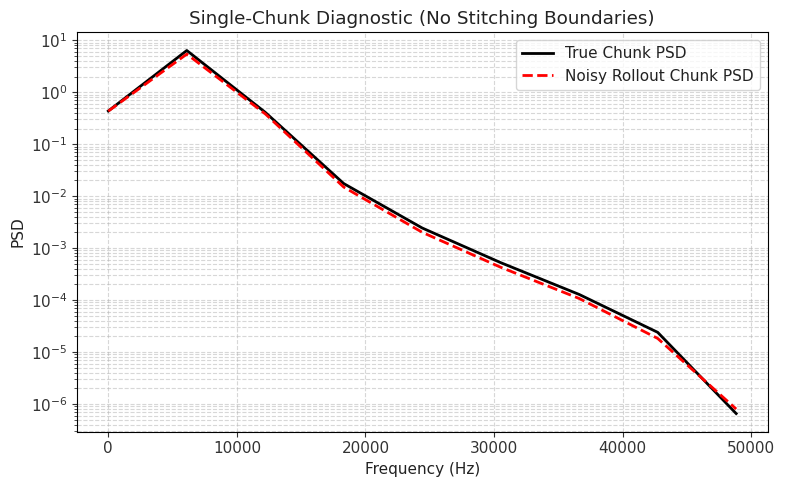

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

first = 0
last = 64

# extract a single continuous 64-step chunk from saved realizations
# this completely bypasses the chunk-stitching boundaries
single_chunk_pred = matrix_real[first, :last]  # First realization, first window
single_chunk_true = true_data_full[first, :last]

# compute the Welch PSD using the correct sampling frequency
fs = 1.0 / dt

f_pred, Pxx_pred = welch(single_chunk_pred, fs=fs, nperseg=16)
f_true, Pxx_true = welch(single_chunk_true, fs=fs, nperseg=16)

# plot the comparison
plt.figure(figsize=(8, 5))
plt.semilogy(f_true, Pxx_true, label='True Chunk PSD', color='black', lw=2)
plt.semilogy(f_pred, Pxx_pred, label='Noisy Rollout Chunk PSD', color='red', linestyle='--', lw=2)

plt.title("Single-Chunk Diagnostic (No Stitching Boundaries)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD")
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
plt.close('all')

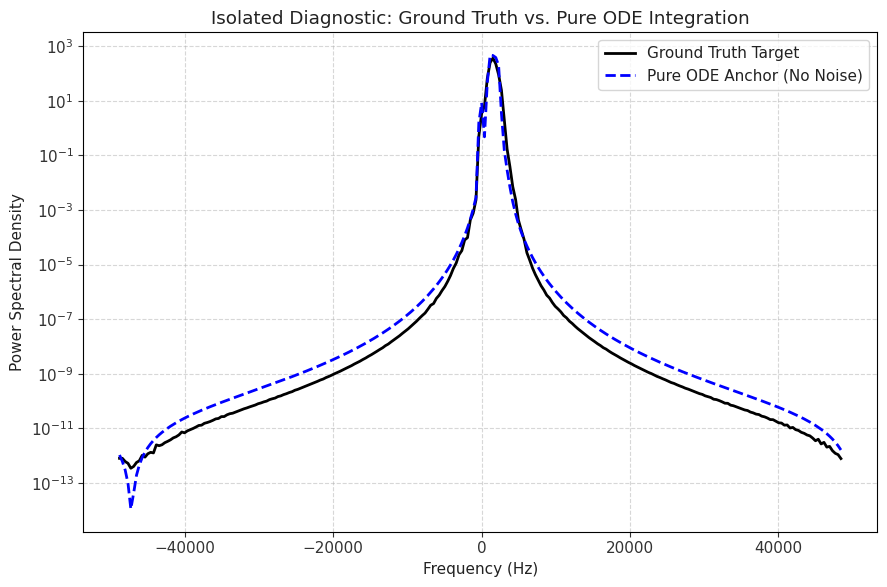

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# load data
data = np.loadtxt('fno_sindy_ensemble_summary.txt', skiprows=1)
t = data[:, 0]
true_real = data[:, 1]
true_imag = data[:, 2]
pred_pure_real = data[:, 7] # pred_real_pure_global
pred_pure_imag = data[:, 8] # pred_imag_pure_global

# reconstruct complex signals
true_complex = true_real + 1j * true_imag
pred_complex = pred_pure_real + 1j * pred_pure_imag

# welch
dt = np.mean(np.diff(t))
fs = 1.0 / dt
nperseg = 256  # High resolution window to inspect the tail behavior clearly

f_true, Pxx_true = welch(true_complex, fs=fs, nperseg=nperseg, return_onesided=False)
f_pred, Pxx_pred = welch(pred_complex, fs=fs, nperseg=nperseg, return_onesided=False)

# shift arrays for plotting
idx_true = np.argsort(f_true)
idx_pred = np.argsort(f_pred)

# plotting the spectra
plt.figure(figsize=(9, 6))
plt.semilogy(f_true[idx_true], Pxx_true[idx_true], label='Ground Truth Target', color='black', lw=2)
plt.semilogy(f_pred[idx_pred], Pxx_pred[idx_pred], label='Pure ODE Anchor (No Noise)', color='blue', linestyle='--', lw=2)

plt.title("Isolated Diagnostic: Ground Truth vs. Pure ODE Integration")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
# # # This is the original, dont change this anyhow, for peace of mind


# import numpy as np
# import torch
# from torchdiffeq import odeint_adjoint as odeint


# model.eval()
# # prepare ground truth & time variables
# a_1_trimmed_reconstructed = np.concatenate([a_1_train, a_1_val, a_1_test])
# true_data_full = np.stack(
#     [a_1_trimmed_reconstructed.real, a_1_trimmed_reconstructed.imag], axis=0
# ).astype(np.float32)

# total_snapshots = true_data_full.shape[1]
# history_len = 64
# pred_len    = 64
# t_eval_full = t_model[:total_snapshots]

# # ode part
# print("Running global continuous native ODE anchor via torchdiffeq...")
# with torch.no_grad():
#     t_steps_global = torch.linspace(
#         model.dt, 
#         total_snapshots * model.dt, 
#         steps=total_snapshots, 
#         dtype=torch.float64, 
#         device=device
#     )
#     z_init_global = torch.complex(
#         torch.tensor(true_data_full[0, 0], device=device), 
#         torch.tensor(true_data_full[1, 0], device=device)
#     ) # Native scalar/batch initialization matching CustomODEField
    
#     sol_global_complex = odeint(
#         model.vector_field, 
#         z_init_global, 
#         t_steps_global, 
#         method='rk4', 
#         options={'step_size': model.dt}
#     )
    
#     sol_global_complex = sol_global_complex.cpu().numpy()
#     pred_real_pure_global = sol_global_complex.real
#     pred_imag_pure_global = sol_global_complex.imag

# # ensemble configs
# num_realizations = 30
# print(f"Generating ensemble of {num_realizations} stochastic realizations...")

# all_realizations_real = []
# all_realizations_imag = []

# # LOOP OVER STOCHASTIC SEEDS (Autoregressive Rollout Engine)
# for seed in range(num_realizations):
#     np.random.seed(seed)
#     current_history = torch.tensor(true_data_full[:, :history_len]).unsqueeze(0).to(device)  
#     corrected_chunks = [true_data_full[:, :history_len]]
    
#     with torch.no_grad():
#         for start_idx in range(history_len, total_snapshots, pred_len):
#             if start_idx + pred_len > total_snapshots:
#                 break

#             # Execute unified hybrid forward pass from your model definition
#             ode_window, mu_win, std_win = model(current_history)
            
#             # match original squeeze
#             mu_w = mu_win.squeeze().cpu().numpy()     # Instantly maps to shape (64,)
#             sigma_w = std_win.squeeze().cpu().numpy() # Instantly maps to shape (64,)
            
#             # extract pristine phase angles from the continuous internal solver output
#             chunk = ode_window.squeeze(0).cpu().numpy()  
#             chunk_complex = chunk[0, :] + 1j * chunk[1, :]
#             theta_window = np.angle(chunk_complex) 
            
#             # compute power spectrum of current window for coherent noise shaping
#             state_fft = np.fft.fft(chunk_complex)[:pred_len // 2 + 1] 
#             r_power_spectrum = np.abs(state_fft)
            
            
#             # synthesize and shape stochastic noise profile
#             white_noise = np.random.normal(0.0, 1.0, size=pred_len)
#             noise_fft = np.fft.rfft(white_noise)
#             shaped_noise_fft = noise_fft * r_power_spectrum
#             coherent_noise = np.fft.irfft(shaped_noise_fft, n=pred_len) 
#             coherent_noise = (coherent_noise - np.mean(coherent_noise)) / (np.std(coherent_noise) + 1e-5)
            
#             # map stochastic amplitude variations on top of unbinned FNO statistics
#             r_corrected = mu_w + (coherent_noise * sigma_w)
#             r_corrected = np.clip(r_corrected, 0, None)
            
#             # reconstruct Cartesian targets using aligned internal phase arrays
#             real_corrected = r_corrected * np.cos(theta_window)
#             imag_corrected = r_corrected * np.sin(theta_window)
            
#             pred_numpy = np.stack([real_corrected, imag_corrected], axis=0) 
#             corrected_chunks.append(pred_numpy)
            
#             # Push forward the timeline window by replacing lookback memory blocks
#             old_history_np = current_history.squeeze(0).cpu().numpy()
#             new_history = np.concatenate([old_history_np, pred_numpy], axis=1)[:, -history_len:]
#             current_history = torch.tensor(new_history, dtype=torch.float32).unsqueeze(0).to(device)
            
#     realization_full = np.concatenate(corrected_chunks, axis=1)
#     all_realizations_real.append(realization_full[0, :])
#     all_realizations_imag.append(realization_full[1, :])

# # convert lists to solid arrays for analysis
# matrix_real = np.array(all_realizations_real)
# matrix_imag = np.array(all_realizations_imag)

# # Calculate global UQ statistics
# mean_real, std_real = np.mean(matrix_real, axis=0), np.std(matrix_real, axis=0)
# mean_imag, std_imag = np.mean(matrix_imag, axis=0), np.std(matrix_imag, axis=0)
# num_predicted_steps = mean_real.shape[0]

# true_data_matched = true_data_full[:, :num_predicted_steps]

# # SAVE MATRIX A: LINE TRACKERS & TIME REFERENCES
# np.savetxt('fno_sindy_ensemble_summary.txt', np.column_stack([
#     t_eval_full[:num_predicted_steps],
#     true_data_matched[0, :], true_data_matched[1, :],
#     mean_real, std_real, mean_imag, std_imag,
#     pred_real_pure_global[:num_predicted_steps], pred_imag_pure_global[:num_predicted_steps]
# ]), header='t true_real true_imag mean_real std_real mean_imag std_imag pred_real_pure pred_imag_pure', comments='')

# # SAVE MATRIX B: FULL FLATTENED ARRAYS FOR UQ DISTRIBUTION PLOTS
# np.savetxt('fno_sindy_ensemble_distributions.txt', np.column_stack([
#     matrix_real.flatten(),
#     matrix_imag.flatten()
# ]), header='flat_real flat_imag', comments='')

# print("Data exported successfully via native torchdiffeq pipelines. Ready for UQ script!")


In [57]:
# diag: compute and print raw global ode psd
from find_spectrum import hann2, pwelch2

# convert the torchdiffeq solution tensor
sol_global_complex_np = sol_global_complex

# extract sampling parameters matching your evaluation setup
dt_diag = model.dt
fs_diag = 1.0 / dt_diag

# setup matching Welch parameters (nFFT=128)
nFFT_diag = 64
window_diag = hann2(nFFT_diag)

# cimpute the true continuous baseline spectrum of the ODE solver
Pxx_ode_diag, F_ode_diag = pwelch2(sol_global_complex_np, nFFT_diag, fs_diag, window_diag)

# print the raw PSD values in linear scale to inspect the tail
print("\n=== RAW GLOBAL ODE PSD VALUES (Linear Scale) ===")
print(Pxx_ode_diag)

# print the PSD values converted to Decibels (dB)
print("\n=== GLOBAL ODE PSD VALUES (Decibel Scale [dB]) ===")
print(10 * np.log10(Pxx_ode_diag + 1e-15))


=== RAW GLOBAL ODE PSD VALUES (Linear Scale) ===
[6.26613605e+01 2.10927443e+02 7.23456122e+01 1.03203147e+00
 3.60984031e-02 4.77559067e-03 1.07929642e-03 3.30013467e-04
 1.22884701e-04 5.26104452e-05 2.50025506e-05 1.28869993e-05
 7.08803677e-06 4.11102470e-06 2.49173653e-06 1.56708305e-06
 1.01671990e-06 6.77182881e-07 4.61051056e-07 3.19626815e-07
 2.24796615e-07 1.59809699e-07 1.14401471e-07 8.21225079e-08
 5.88291278e-08 4.18061045e-08 2.92438080e-08 1.99195306e-08
 1.29994564e-08 7.91365827e-09 4.27639855e-09 1.83531308e-09
 4.39669215e-10]

=== GLOBAL ODE PSD VALUES (Decibel Scale [dB]) ===
[ 17.9699982   23.24133089  18.59412196   0.13692941 -14.4251201
 -23.20972905 -29.66859265 -34.81468337 -39.10502183 -42.78928023
 -46.02015685 -48.89848196 -51.49474038 -53.86049913 -56.03497881
 -58.04907985 -59.92798677 -61.69294029 -63.36250978 -64.95356792
 -66.48210231 -67.96396863 -69.41568388 -70.85537791 -72.30407583
 -73.78760288 -75.33966061 -77.00720877 -78.86074776 -81.0162265

In [ ]:
# combine the individual real and imaginary paths into complex numbers 
ensemble_matrix = matrix_real + 1j * matrix_imag
np.save('fno_ensemble_coefficients.npy', ensemble_matrix)

print(f"[SUCCESS] Exported full {ensemble_matrix.shape} matrix to 'fno_ensemble_coefficients.npy'!")
print("Data exported successfully. Ready for UQ script!")

[SUCCESS] Exported full (30, 5312) matrix to 'fno_ensemble_coefficients.npy'!
Data exported successfully. Ready for UQ script!


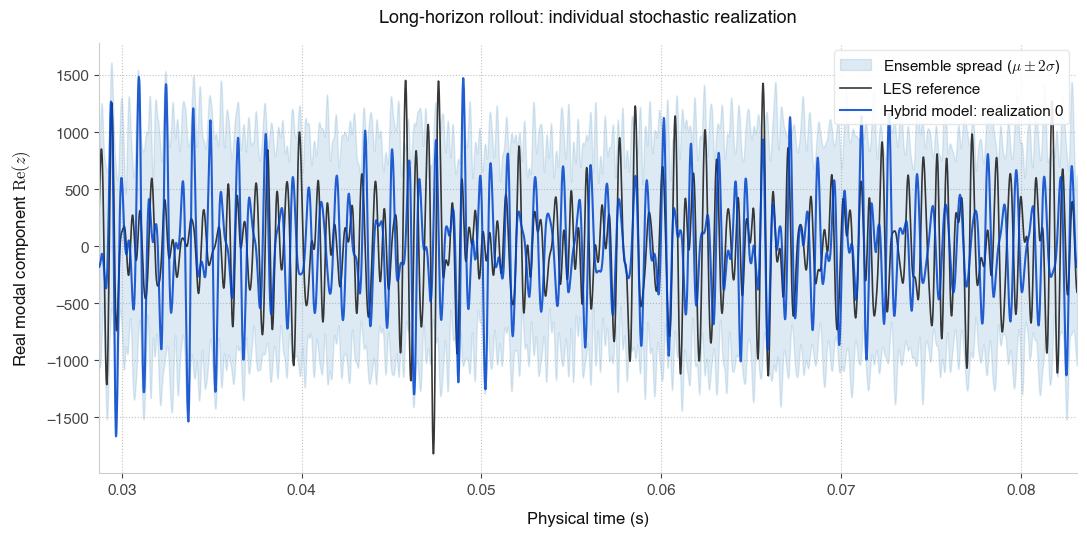

Figure saved as: fno_mixed_ode_time_rollout_clean.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# LOAD SUMMARY STATISTICS AND A SINGLE REALIZATION
# =====================================================================
data = np.loadtxt(
    'fno_sindy_ensemble_summary.txt',
    skiprows=1
)

t = data[:, 0]
true_real = data[:, 1]
mean_real = data[:, 3]
std_real = data[:, 4]

ensemble_coefs = np.load('fno_ensemble_coefficients.npy')

# Select realization 0 and match the summary-record length.
single_real_real = ensemble_coefs[0, :].real

if len(single_real_real) < len(t):
    raise ValueError(
        "The selected realization is shorter than the summary record. "
        "Use exports covering the same time interval."
    )

single_real_real = single_real_real[:len(t)]

# =====================================================================
# PLOT STYLE
# =====================================================================
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'figure.facecolor': '#FFFFFF',
    'axes.facecolor': '#FFFFFF',
    'text.color': '#111111',
    'axes.labelcolor': '#111111',
    'xtick.color': '#444444',
    'ytick.color': '#444444',
})

fig, ax = plt.subplots(figsize=(11, 5.5))

# Pointwise ensemble spread, not a confidence interval for the mean.
ax.fill_between(
    t,
    mean_real - 2 * std_real,
    mean_real + 2 * std_real,
    color='#1f77b4',
    alpha=0.15,
    label=r'Ensemble spread ($\mu \pm 2\sigma$)',
    zorder=1
)

# LES reference
ax.plot(
    t,
    true_real,
    label='LES reference',
    color='#222222',
    lw=1.2,
    alpha=0.9,
    zorder=2
)

# Single stochastic realization
ax.plot(
    t,
    single_real_real,
    label='Hybrid model: realization 0',
    color='#0044cc',
    lw=1.5,
    alpha=0.85,
    zorder=3
)

# =====================================================================
# AXES AND LEGEND
# =====================================================================
ax.set_title(
    'Long-horizon rollout: individual stochastic realization',
    pad=15,
    weight='bold'
)
ax.set_xlabel('Physical time (s)', labelpad=10)
ax.set_ylabel(r'Real modal component $\mathrm{Re}(z)$', labelpad=10)
ax.set_xlim(t.min(), t.max())

ax.grid(
    True,
    linestyle=':',
    alpha=0.5,
    color='#888888'
)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

legend = ax.legend(
    loc='upper right',
    framealpha=0.9,
    facecolor='#FFFFFF',
    edgecolor='#E5E5E5'
)

for text in legend.get_texts():
    text.set_color('#111111')

# =====================================================================
# SAVE
# =====================================================================
fig.tight_layout()

output_filename = 'fno_mixed_ode_time_rollout_clean.png'
fig.savefig(
    output_filename,
    dpi=400,
    bbox_inches='tight'
)

plt.show()

print(f'Figure saved as: {output_filename}')

In [63]:
# import numpy as np

# # need to check boundary issues, gibbs phenomenon
# # Let's look at steps 61 through 66 (Python index 60 to 65)
# start_idx = 60
# end_idx = 66

# print("="*60)
# print(f"DIAGNOSTIC LOG: Ensemble Boundary Transition (Steps {start_idx+1} to {end_idx})")
# print("="*60)

# for path_idx in range(min(3, ensemble_matrix.shape[0])):
#     print(f"\n--- Realization Path {path_idx} ---")
#     for t_idx in range(start_idx, end_idx):
#         val = ensemble_matrix[path_idx, t_idx]
        
#         # Highlight step 64 and 65 (the chunk transition interface)
#         marker = " <== END CHUNK N" if t_idx == 63 else (" <== START CHUNK N+1" if t_idx == 64 else "")
        
#         print(f"  Step {t_idx+1:02d} | Real: {val.real:11.4e} | Imag: {val.imag:11.4e} | Mag: {np.abs(val):11.4e}{marker}")
# print("="*60)

In [62]:
# print("Sample Pred Mean Max:", pred_mean.max().item())
# print("Sample Pred Std Mean:", pred_std.mean().item())
# print("Sample Coherent Noise Std:", coherent_noise.std().item())

--- Data Processing Summary ---
Total rows loaded: 5312
Maximum real-component spread index: 544
Maximum ensemble standard deviation of Re(z): 683.04
Magnitude of ensemble-mean coordinate at that index: 58.40


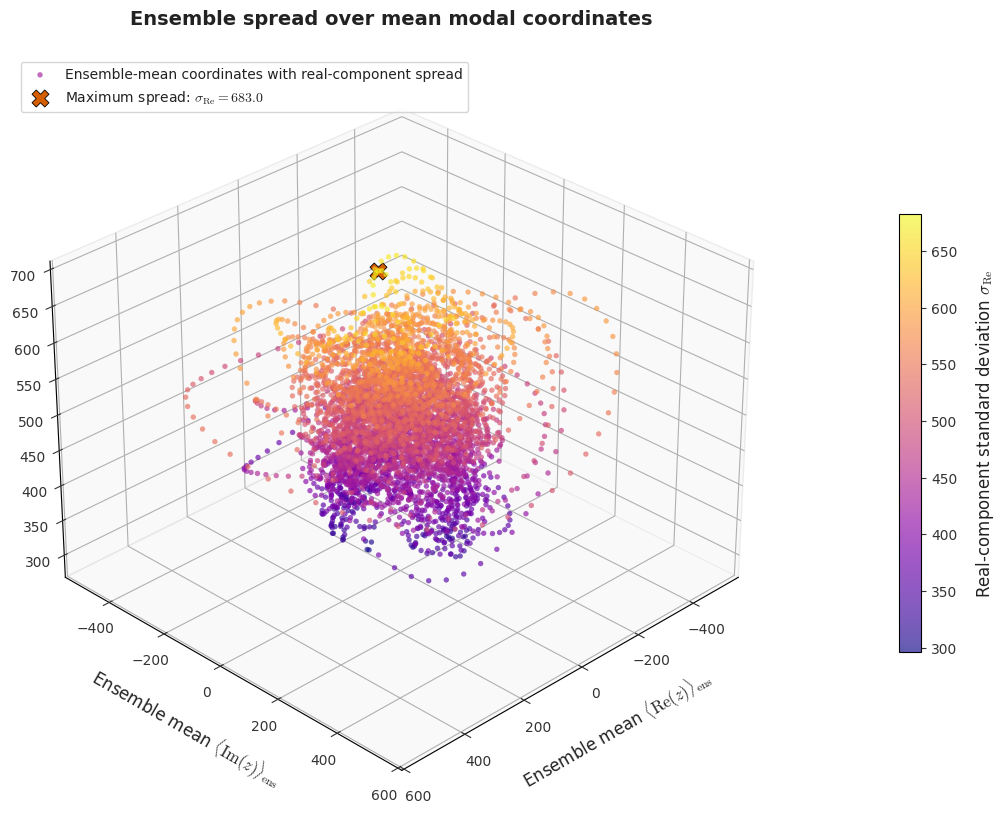

[SUCCESS] Saved 'stochastic_wavepacket_diffusion_manifold_3d.png'.


In [64]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# LOAD EXPORTED ENSEMBLE STATISTICS
# =====================================================================
data = np.loadtxt(
    'fno_sindy_ensemble_summary.txt',
    skiprows=1
)

t = data[:, 0]
true_real, true_imag = data[:, 1], data[:, 2]
mean_real, std_real = data[:, 3], data[:, 4]
mean_imag, std_imag = data[:, 5], data[:, 6]

# Magnitude of the ensemble-mean complex coordinate.
# This is distinct from the ensemble mean of the magnitudes.
r_mean = np.abs(mean_real + 1j * mean_imag)

# Maximum ensemble standard deviation of the real component.
max_std_idx = np.argmax(std_real)

print("--- Data Processing Summary ---")
print(f"Total rows loaded: {len(t)}")
print(f"Maximum real-component spread index: {max_std_idx}")
print(
    "Maximum ensemble standard deviation of Re(z): "
    f"{std_real[max_std_idx]:.2f}"
)
print(
    "Magnitude of ensemble-mean coordinate at that index: "
    f"{r_mean[max_std_idx]:.2f}"
)

# =====================================================================
# WHITE-BACKGROUND FIGURE STYLE
# =====================================================================
plt.style.use('default')
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "mathtext.fontset": "cm",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig = plt.figure(figsize=(12, 9), facecolor='white')
ax = fig.add_subplot(111, projection='3d')

# Each point represents one time sample:
# (ensemble mean real part, ensemble mean imaginary part,
#  ensemble standard deviation of the real part).
scatter = ax.scatter(
    mean_real,
    mean_imag,
    std_real,
    c=std_real,
    cmap='plasma',
    s=15,
    alpha=0.65,
    edgecolors='none',
    label='Ensemble-mean coordinates with real-component spread'
)

ax.scatter(
    mean_real[max_std_idx],
    mean_imag[max_std_idx],
    std_real[max_std_idx],
    color='#D55E00',
    edgecolors='black',
    linewidths=0.6,
    marker='X',
    s=150,
    depthshade=False,
    label=(
        r'Maximum spread: '
        rf'$\sigma_{{\mathrm{{Re}}}}={std_real[max_std_idx]:.1f}$'
    )
)

ax.set_title(
    'Ensemble spread over mean modal coordinates',
    fontsize=14,
    fontweight='semibold',
    pad=22
)

ax.set_xlabel(
    r'Ensemble mean $\langle\operatorname{Re}(z)\rangle_{\mathrm{ens}}$',
    fontsize=12,
    labelpad=12
)
ax.set_ylabel(
    r'Ensemble mean $\langle\operatorname{Im}(z)\rangle_{\mathrm{ens}}$',
    fontsize=12,
    labelpad=12
)
ax.set_zlabel(
    r'Real-component standard deviation $\sigma_{\mathrm{Re}}$',
    fontsize=12,
    labelpad=12
)

# Pale coordinate panes retain depth without a dark background.
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.set_facecolor((0.96, 0.96, 0.96, 1.0))
    axis.pane.set_edgecolor('#DDDDDD')

ax.tick_params(labelsize=10, pad=3)
ax.grid(True)
ax.view_init(elev=30, azim=45)

cbar = fig.colorbar(
    scatter,
    ax=ax,
    shrink=0.58,
    aspect=20,
    pad=0.12
)
cbar.set_label(
    r'Real-component standard deviation $\sigma_{\mathrm{Re}}$',
    fontsize=12,
    labelpad=12
)
cbar.ax.tick_params(labelsize=10)

ax.legend(
    loc='upper left',
    fontsize=10,
    frameon=True,
    facecolor='white',
    edgecolor='#CCCCCC'
)

fig.subplots_adjust(
    left=0.02,
    right=0.92,
    bottom=0.06,
    top=0.90
)

output_stem = 'stochastic_wavepacket_diffusion_manifold_3d'

fig.savefig(
    f'{output_stem}.png',
    dpi=300,
    facecolor='white',
    bbox_inches='tight'
)

plt.show()

print(f"[SUCCESS] Saved '{output_stem}.png'.")

<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\m'
<>:55: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\m'
<>:55: SyntaxWarning: invalid escape sequence '\m'
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_2462/234558279.py:47: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('$\mathcal{R}e(z)$ (Real Pressure Component)', fontsize=11, color='#CBD5E1')
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_2462/234558279.py:48: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('$\mathcal{I}m(z)$ (Imaginary Pressure Component)', fontsize=11, color='#CBD5E1')
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_2462/234558279.py:55: SyntaxWarning: invalid escape sequence '\m'
  cbar.set_label('Normalized Phase Space Density $P(\mathcal{R}e, \mathcal{I}m)$', fontsize=10, color='#CBD5E1')


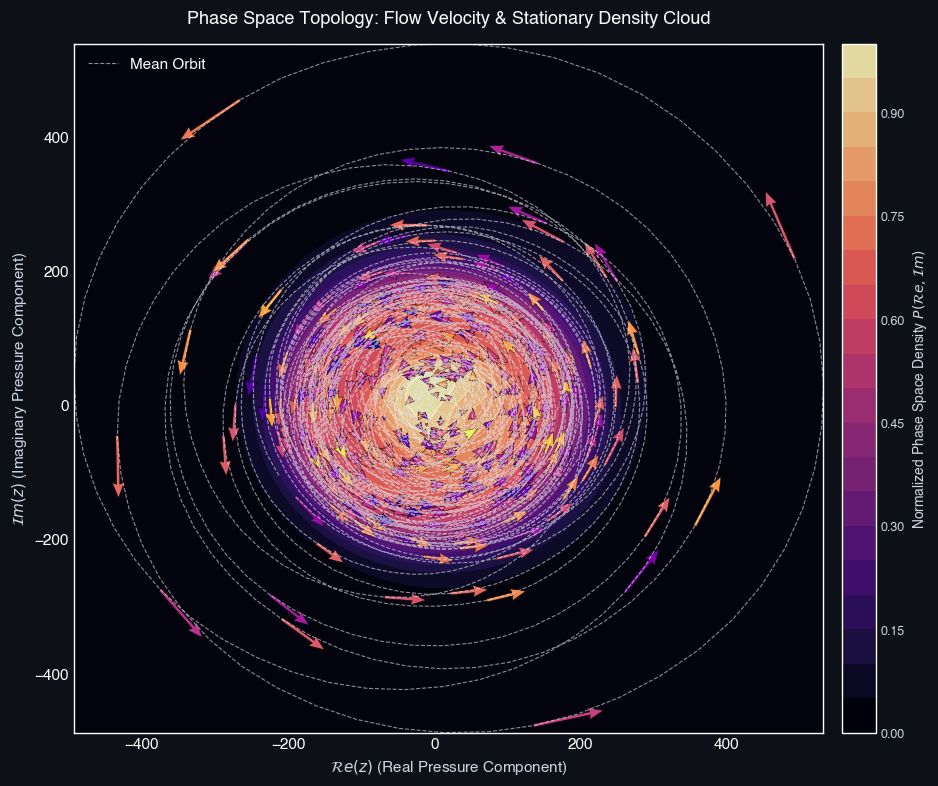

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st

# dark theme
plt.style.use('dark_background')

# load dataset
data = np.loadtxt('fno_sindy_ensemble_summary.txt', skiprows=1)
mean_real, std_real = data[:, 3], data[:, 4]
mean_imag = data[:, 5]

# compute 2D Density (KDE) over the phase space
x_grid, y_grid = np.mgrid[mean_real.min():mean_real.max():120j, 
                         mean_imag.min():mean_imag.max():120j]
positions = np.vstack([x_grid.ravel(), y_grid.ravel()])
values = np.vstack([mean_real, mean_imag])
kernel = st.gaussian_kde(values)
f = np.reshape(kernel(positions).T, x_grid.shape)

# normalize density for cleaner colorbar scaling [0, 1]
f_norm = f / np.max(f)

# compute Trajectory Velocities (dx/dt, dy/dt) for Vector Arrows
dx = np.gradient(mean_real)
dy = np.gradient(mean_imag)

# setup Figure
fig, ax = plt.subplots(figsize=(10, 8), facecolor='#0D1117')
ax.set_facecolor('#0D1117')

# density Contours in background (using dark magma palette)
cf = ax.contourf(x_grid, y_grid, f_norm, levels=20, cmap='magma', alpha=0.9)

# streamlines showing trajectory direction and speed (increased skip to 14 to reduce clutter)
skip = (slice(None, None, 14))
quiv = ax.quiver(mean_real[skip], mean_imag[skip], dx[skip], dy[skip], std_real[skip],
                  cmap='plasma', scale=None, width=0.004, headwidth=4, headlength=5,
                  edgecolor='black', linewidth=0.3)

# traj centerline
ax.plot(mean_real, mean_imag, color='#E2E8F0', linewidth=0.8, linestyle='--', alpha=0.6, label='Mean Orbit')

# formatting & Labels
ax.set_title('Phase Space Topology: Flow Velocity & Stationary Density Cloud', 
             fontsize=13, fontweight='bold', pad=15, color='#F8FAFC')
ax.set_xlabel('$\mathcal{R}e(z)$ (Real Pressure Component)', fontsize=11, color='#CBD5E1')
ax.set_ylabel('$\mathcal{I}m(z)$ (Imaginary Pressure Component)', fontsize=11, color='#CBD5E1')

# custom dark grid
ax.grid(True, linestyle=':', alpha=0.2, color='#94A3B8')

# colorbars
cbar = fig.colorbar(cf, ax=ax, pad=0.02)
cbar.set_label('Normalized Phase Space Density $P(\mathcal{R}e, \mathcal{I}m)$', fontsize=10, color='#CBD5E1')
cbar.ax.tick_params(labelsize=9, colors='#CBD5E1')

ax.legend(loc='upper left', facecolor='#161B22', edgecolor='#30363D', labelcolor='#F8FAFC')

plt.tight_layout()
plt.savefig('phase_space_density_dark.png', dpi=300, facecolor=fig.get_facecolor(), edgecolor='none')
plt.show()

<>:37: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:37: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\s'
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_2462/4155528860.py:37: SyntaxWarning: invalid escape sequence '\s'
  cb.set_label('Ensemble Spread ($\sigma_{ensemble}$)', fontsize=11)
/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_2462/4155528860.py:43: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel('Ensemble Uncertainty Spread ($\sigma_{ensemble}$)', fontsize=11)


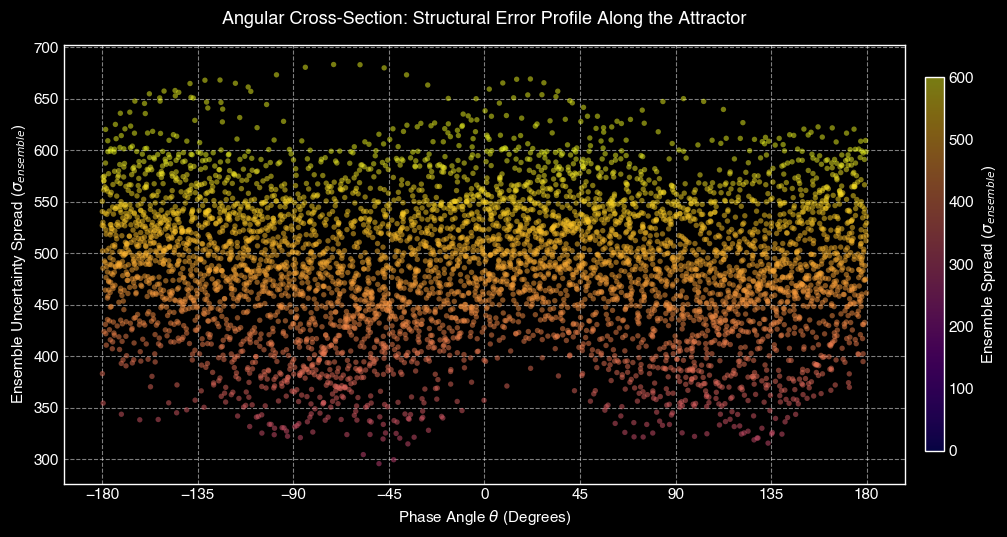

In [ ]:
# angular slice check

import numpy as np
import matplotlib.pyplot as plt

# load dataset
data = np.loadtxt('fno_sindy_ensemble_summary.txt', skiprows=1)
mean_real, std_real  = data[:, 3], data[:, 4]
mean_imag, std_imag  = data[:, 5], data[:, 6]


mean_real_c = mean_real
mean_imag_c = mean_imag
std_real_c = std_real

# transform to pola
# calc the phase angle (from -pi to pi) for every point in the core
angles = np.arctan2(mean_imag_c, mean_real_c)

# convert radians to degrees for x-axis interpretation bounded to (-180 to 180)
angles_deg = np.degrees(angles)

# generate the cross-sectional profile
plt.figure(figsize=(11, 5.5))

# plot the unrolled angular cross-section
# color by spread value using 'plasma' for viz
sc = plt.scatter(angles_deg, std_real_c, c=std_real_c, cmap='plasma',
                 s=15, alpha=0.5, edgecolors='none', vmin=0, vmax=600)

# add a colorbar
cb = plt.colorbar(sc, pad=0.02, shrink=0.85)
cb.set_label('Ensemble Spread ($\sigma_{ensemble}$)', fontsize=11)

# formatting aesthetics & Typography
plt.title('Angular Cross-Section: Structural Error Profile Along the Attractor', 
          fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Phase Angle $\\theta$ (Degrees)', fontsize=11)
plt.ylabel('Ensemble Uncertainty Spread ($\sigma_{ensemble}$)', fontsize=11)

# set clean ticks to mark the quadrants clearly
plt.xticks([-180, -135, -90, -45, 0, 45, 90, 135, 180])
plt.grid(True, linestyle='--', alpha=0.5)
# plt.xlim(-180, 180)
# plt.ylim(0, 600)

# annonate the structural architecture of the saddle peaks
# plt.annotate('Saddle Peak 1', xy=(-60, 530), xytext=(-120, 550),
#              arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
#              fontsize=10, fontweight='bold')

# plt.annotate('Saddle Peak 2', xy=(110, 530), xytext=(40, 550),
#              arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
#              fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('attractor_angular_slice.png', dpi=300)
plt.show()

In [ ]:
# ensemble KL to see the probability match
import numpy as np
from scipy.stats import ks_2samp

print("=" * 60)
print("  EVALUATING DOWNSTREAM ENSEMBLE DISTRIBUTION HULL (KS-TEST)")
print("=" * 60)

# compute true wave envelope magnitudes
# Shape [2, Time_Steps] (Real index 0, Imag index 1)
true_complex_full = true_data_matched[0, :] + 1j * true_data_matched[1, :]
true_envelopes = np.abs(true_complex_full)

# compute full generated ensemble wave envelope magnitudes
# matrix structures flattened to evaluate the global continuous field distribution
matrix_complex_full = matrix_real + 1j * matrix_imag
pred_envelopes_flat = np.abs(matrix_complex_full).flatten()

# run the Non-Parametric Two-Sample Kolmogorov-Smirnov Test
# this evaluates the maximum vertical distance between the two empirical CDFs
ks_statistic, p_value = ks_2samp(true_envelopes, pred_envelopes_flat)

print(f"\n-> True Envelope Samples:      {len(true_envelopes)}")
print(f"-> Ensemble Envelope Samples:  {len(pred_envelopes_flat)}")
print("-" * 60)
print(f"-> KS STATISTIC (Max CDF Distance D): {ks_statistic:.06f}")
print(f"-> ASYMPTOTIC P-VALUE:               {p_value:.06e}")
print("=" * 60)


# heuristic threshold for diagnostics
# threshold benchmarks adjusted for strict continuous spatial/temporal matching
if ks_statistic < 0.08:
    print("STATUS: Flawless structural alignment. Empirical CDFs match perfectly.")
elif ks_statistic < 0.18:
    print("STATUS: Acceptable macro alignment. Envelope bounds match well.")
else:
    print("STATUS: Distribution distortion detected. Model variance is skewed.")


# heuristic comparision, will be stale value, rerun

  EVALUATING DOWNSTREAM ENSEMBLE DISTRIBUTION HULL (KS-TEST)

-> True Envelope Samples:      5312
-> Ensemble Envelope Samples:  159360
------------------------------------------------------------
-> KS STATISTIC (Max CDF Distance D): 0.096988
-> ASYMPTOTIC P-VALUE:               1.519781e-42
STATUS: Acceptable macro alignment. Envelope bounds match well.


In [ ]:
# load the data
data = np.loadtxt('fno_sindy_ensemble_summary.txt', skiprows=1)
mean_real, std_real  = data[:, 3], data[:, 4]
mean_imag, std_imag  = data[:, 5], data[:, 6]

# calculate total spread magnitude directly for every point (Length: 5312)
sigma_ensemble_c = np.sqrt(std_real**2 + std_imag**2)

# calculate angles directly for every point (Length: 5312)
angles = np.arctan2(mean_imag, mean_real)
angles_deg = np.degrees(angles)

# binning stat
bin_edges = np.arange(-180, 182, 2)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

mean_profile = []
percentile_95_profile = []

for i in range(len(bin_edges) - 1):
    mask = (angles_deg >= bin_edges[i]) & (angles_deg < bin_edges[i+1])
    if np.sum(mask) > 0:
        mean_profile.append(np.mean(sigma_ensemble_c[mask]))
        percentile_95_profile.append(np.percentile(sigma_ensemble_c[mask], 95))
    else:
        mean_profile.append(0)
        percentile_95_profile.append(0)

mean_profile = np.array(mean_profile)
percentile_95_profile = np.array(percentile_95_profile)

# find exact centers of both peaks
left_half_mask = bin_centers < 0
right_half_mask = bin_centers >= 0

# find peak of the mean cloud or the peak of the 95th percentile envelope
true_peak1_idx = np.argmax(mean_profile * left_half_mask)
true_peak2_idx = np.argmax(mean_profile * right_half_mask)

print(f"True Center of Saddle Peak 1: {bin_centers[true_peak1_idx]:.2f}°")
print(f"True Center of Saddle Peak 2: {bin_centers[true_peak2_idx]:.2f}°")

angular_distance = bin_centers[true_peak2_idx] - bin_centers[true_peak1_idx]
print(f"Absolute Angular Distance: {angular_distance:.2f}°")

True Center of Saddle Peak 1: -59.00°
True Center of Saddle Peak 2: 35.00°
Absolute Angular Distance: 94.00°


In [ ]:
# =====================================================================
# Windowed spatial phase regression + FNO convective phase velocity
#
# Spatial:
#   theta_psi(x) ~ kx * x + b
#
# Temporal:
#   omega(t) = d/dt arg[z_FNO(t)]
#
# Phase velocity:
#   U_phase = |omega| / |kx|
# =====================================================================

import numpy as np
import h5py as h

# ---------------------------------------------------------------------
# Physical parameters
# ---------------------------------------------------------------------

Dj_physical = 0.0169   # Jet nozzle diameter [m]
Uj_physical = 302.0    # Jet exit velocity [m/s]

data_path = (
    '/Users/icarus/Desktop/SPODcode/spod_matlab/'
    'spod_complete_continuous_database.mat'
)
ml_path = 'fno_ensemble_coefficients.npy'

target_st = 0.1
mode_idx = 0

# Spatial phase-regression settings
r_target = 0.2          # r / D_j
x1_target = 3.0         # x / D_j
x2_target = 6.0         # x / D_j


# ---------------------------------------------------------------------
# 1. Load SPOD mode, physical grid, and time vector
# ---------------------------------------------------------------------

print("[INFO] Loading SPOD database, coordinates, time vector, and FNO ensemble...")

with h.File(data_path, 'r') as file:

    st_vector = np.squeeze(file['St_vector'][:])
    target_fi = int(np.argmin(np.abs(st_vector - target_st)))
    st_actual = float(st_vector[target_fi])

    # Leading complex SPOD spatial mode
    psi_grid_raw = file['P'][mode_idx, :, :, target_fi]
    psi_1_spatial = (
        np.asarray(psi_grid_raw['real'])
        + 1j * np.asarray(psi_grid_raw['imag'])
    )

    # Time vector
    t_uniform = np.squeeze(file['t_uniform'][:])
    dt = float(np.mean(np.diff(t_uniform)))

    # Actual spatial coordinates from database
    x_nondim = (
        np.sort(np.unique(np.asarray(file['x_ij'][:]).ravel()))
        / Dj_physical
    )

    r_nondim = (
        np.sort(np.unique(np.asarray(file['y_ij'][:]).ravel()))
        / Dj_physical
    )


# ---------------------------------------------------------------------
# 2. Ensure SPOD mode orientation matches [x, r]
# ---------------------------------------------------------------------

nx = len(x_nondim)
nr = len(r_nondim)

if psi_1_spatial.shape == (nr, nx):
    psi_1_spatial = psi_1_spatial.T

elif psi_1_spatial.shape != (nx, nr):
    raise ValueError(
        "SPOD spatial mode shape does not match coordinate dimensions:\n"
        f"psi shape = {psi_1_spatial.shape}, "
        f"expected {(nx, nr)} or {(nr, nx)}"
    )

x_grid = x_nondim
r_grid = r_nondim

print(f"[INFO] Resolved SPOD bin: St = {st_actual:.4f}")
print(f"[INFO] Spatial grid: nx = {nx}, nr = {nr}")
print(
    f"[INFO] Domain: x/D_j = [{x_grid[0]:.3f}, {x_grid[-1]:.3f}], "
    f"r/D_j = [{r_grid[0]:.3f}, {r_grid[-1]:.3f}]"
)
print(f"[INFO] Sampling interval: dt = {dt:.6e} s")


# ---------------------------------------------------------------------
# 3. Load FNO stochastic ensemble
# ---------------------------------------------------------------------

ensemble_matrix = np.load(ml_path)

if ensemble_matrix.ndim == 1:
    ensemble_matrix = ensemble_matrix[np.newaxis, :]

n_realizations, n_timesteps = ensemble_matrix.shape

print(
    f"[INFO] Loaded {n_realizations} FNO realizations, "
    f"{n_timesteps} timesteps each."
)


# ---------------------------------------------------------------------
# 4. Extract spatial SPOD phase at selected radial location
# ---------------------------------------------------------------------

r_slice_idx = int(np.argmin(np.abs(r_grid - r_target)))
r_actual = float(r_grid[r_slice_idx])

psi_slice = psi_1_spatial[:, r_slice_idx]

# Unwrapped spatial phase
spatial_phase = np.unwrap(np.angle(psi_slice))


# ---------------------------------------------------------------------
# 5. Spatial phase-resolution diagnostic
# ---------------------------------------------------------------------

dphase_step = np.diff(spatial_phase)
max_step = float(np.max(np.abs(dphase_step)))

if max_step > np.pi / 2:
    print(
        f"[WARN] Maximum unwrapped spatial phase increment = "
        f"{max_step:.3f} rad."
    )
    print(
        "[WARN] Spatial phase varies rapidly; inspect the selected "
        "radial slice and regression window."
    )


# ---------------------------------------------------------------------
# 6. Windowed linear regression for effective streamwise wavenumber
# ---------------------------------------------------------------------

idx1 = int(np.argmin(np.abs(x_grid - x1_target)))
idx2 = int(np.argmin(np.abs(x_grid - x2_target)))

if idx2 < idx1:
    idx1, idx2 = idx2, idx1

x1_actual = float(x_grid[idx1])
x2_actual = float(x_grid[idx2])
delta_x = x2_actual - x1_actual

x_window = x_grid[idx1:idx2 + 1]
phase_window = spatial_phase[idx1:idx2 + 1]

if len(x_window) < 3:
    raise ValueError("Too few spatial samples in selected regression window.")

# Linear fit:
# theta(x) = kx * (x / D_j) + b
kx_nondim, phase_intercept = np.polyfit(
    x_window,
    phase_window,
    1
)

phase_fit = kx_nondim * x_window + phase_intercept
residual = phase_window - phase_fit

ss_res = np.sum(residual**2)
ss_tot = np.sum(
    (phase_window - np.mean(phase_window))**2
)

kx_fit_r2 = (
    1.0 - ss_res / ss_tot
    if ss_tot > 1e-14
    else np.nan
)


# ---------------------------------------------------------------------
# 7. Local spatial-wavenumber variability
# ---------------------------------------------------------------------

local_kx = np.gradient(spatial_phase, x_grid)

kx_local_window = local_kx[idx1:idx2 + 1]
kx_local_std = float(np.std(kx_local_window))

delta_phi = float(
    spatial_phase[idx2] - spatial_phase[idx1]
)

# kx_nondim has units rad / D_j
# physical kx has units rad / m
kx_physical = kx_nondim / Dj_physical

# Wavelength is a positive magnitude
lambda_z_nondim = (
    2.0 * np.pi / np.abs(kx_nondim)
    if np.abs(kx_nondim) > 1e-14
    else np.nan
)

lambda_z_physical = lambda_z_nondim * Dj_physical


# ---------------------------------------------------------------------
# 8. Temporal carrier frequency from FNO ensemble
# ---------------------------------------------------------------------

omega_realizations = []

for i in range(n_realizations):

    phase_i = np.unwrap(
        np.angle(ensemble_matrix[i, :])
    )

    # Instantaneous angular frequency [rad/s]
    omega_i = np.gradient(
        phase_i,
        dt
    )

    omega_realizations.append(omega_i)

omega_realizations = np.asarray(omega_realizations)

# Ensemble-average instantaneous frequency at each time
mean_omega_t = np.mean(
    omega_realizations,
    axis=0
)

# Remove 5% from each temporal boundary to reduce derivative edge effects
edge_trim = max(
    1,
    len(mean_omega_t) // 20
)

if len(mean_omega_t) > 2 * edge_trim:
    omega_trimmed = mean_omega_t[
        edge_trim:-edge_trim
    ]
else:
    omega_trimmed = mean_omega_t

# Robust representative angular frequency
mean_omega_signed = float(
    np.median(omega_trimmed)
)

omega_mag = np.abs(mean_omega_signed)

tracked_freq_hz = (
    omega_mag / (2.0 * np.pi)
)


# ---------------------------------------------------------------------
# 9. Directional sign diagnostic
# ---------------------------------------------------------------------

sign_kx = np.sign(kx_nondim)
sign_omega = np.sign(mean_omega_signed)

if sign_kx != 0 and sign_omega != 0 and sign_kx != sign_omega:
    print(
        "[INFO] Spatial and temporal phase slopes have opposite signs. "
        "This may arise from the adopted travelling-wave phase convention; "
        "phase-speed magnitude is evaluated using |omega|/|kx|."
    )


# ---------------------------------------------------------------------
# 10. Physical phase velocity
# ---------------------------------------------------------------------

if np.abs(kx_physical) < 1e-14:
    mean_uc_val = np.nan
    uc_ratio = np.nan
else:
    mean_uc_val = (
        omega_mag
        / np.abs(kx_physical)
    )

    uc_ratio = (
        mean_uc_val
        / Uj_physical
    )


# ---------------------------------------------------------------------
# 11. Reference comparison
# Gryazev et al. (2026): U_phase / U_j approximately 0.63
# ---------------------------------------------------------------------

reference_uc_ratio = 0.63

relative_error_reference = (
    100.0
    * np.abs(
        uc_ratio - reference_uc_ratio
    )
    / reference_uc_ratio
)


# ---------------------------------------------------------------------
# 12. Results
# ---------------------------------------------------------------------

print("\n" + "=" * 72)
print("          SPOD--FNO CONVECTIVE PHASE-SPEED VALIDATION")
print("=" * 72)

print(
    f"Resolved SPOD Strouhal number:       "
    f"{st_actual:.4f}"
)

print(
    f"FNO tracked temporal frequency:      "
    f"{tracked_freq_hz:.2f} Hz"
)

print(
    f"Median signed angular frequency:      "
    f"{mean_omega_signed:.2f} rad/s"
)

print(
    f"Radial phase slice:                   "
    f"r/D_j = {r_actual:.3f}"
)

print(
    f"Evaluation window:                    "
    f"x/D_j = {x1_actual:.3f} to {x2_actual:.3f}"
)

print(
    f"Window length:                        "
    f"{delta_x:.3f} D_j"
)

print("-" * 72)

print(
    f"Accumulated spatial phase:            "
    f"{delta_phi:.4f} rad (signed)"
)

print(
    f"Effective fitted k_x D_j:             "
    f"{kx_nondim:.4f} rad"
)

print(
    f"Spatial phase-fit R^2:                "
    f"{kx_fit_r2:.4f}"
)

print(
    f"Local k_x standard deviation:         "
    f"{kx_local_std:.4f} rad/D_j"
)

if (
    np.abs(kx_nondim) > 1e-14
    and kx_local_std < 0.1 * np.abs(kx_nondim)
):
    print(
        "Local wavenumber diagnostic:          "
        "approximately uniform over window"
    )
else:
    print(
        "Local wavenumber diagnostic:          "
        "varies across selected window"
    )

print(
    f"Physical |k_x|:                       "
    f"{np.abs(kx_physical):.4f} rad/m"
)

print(
    f"Carrier wavelength lambda_z/D_j:      "
    f"{lambda_z_nondim:.3f}"
)

print(
    f"Carrier wavelength lambda_z:          "
    f"{lambda_z_physical:.5f} m"
)

print("-" * 72)

print(
    f"Calculated phase speed U_phase:       "
    f"{mean_uc_val:.2f} m/s"
)

print(
    f"Calculated U_phase / U_j:             "
    f"{uc_ratio:.4f} ({100.0 * uc_ratio:.2f}%)"
)

print(
    f"Gryazev et al. reference U_phase/U_j: "
    f"{reference_uc_ratio:.4f}"
)

print(
    f"Relative difference from reference:   "
    f"{relative_error_reference:.2f}%"
)

print("=" * 72)

[INFO] Loading SPOD database, coordinates, time vector, and FNO ensemble...
[INFO] Resolved SPOD bin: St = 0.0854
[INFO] Spatial grid: nx = 100, nr = 51
[INFO] Domain: x/D_j = [0.100, 10.020], r/D_j = [0.000, 5.010]
[INFO] Sampling interval: dt = 1.024027e-05 s
[INFO] Loaded 30 FNO realizations, 5312 timesteps each.
[WARN] Maximum unwrapped spatial phase increment = 2.982 rad.
[WARN] Spatial phase varies rapidly; inspect the selected radial slice and regression window.
[INFO] Spatial and temporal phase slopes have opposite signs. This may arise from the adopted travelling-wave phase convention; phase-speed magnitude is evaluated using |omega|/|kx|.

          SPOD--FNO CONVECTIVE PHASE-SPEED VALIDATION
Resolved SPOD Strouhal number:       0.0854
FNO tracked temporal frequency:      1596.76 Hz
Median signed angular frequency:      10032.73 rad/s
Radial phase slice:                   r/D_j = 0.200
Evaluation window:                    x/D_j = 3.006 to 6.012
Window length:                

In [ ]:
# for temporal coeffs, not the reconstructed one


import numpy as np

# Current coefficient exports
summary_path = "fno_sindy_ensemble_summary.txt"
ensemble_path = "fno_ensemble_coefficients.npy"

summary = np.loadtxt(summary_path, skiprows=1, ndmin=2)
ensemble = np.load(ensemble_path, allow_pickle=False)

if summary.shape[1] < 3:
    raise ValueError("Expected summary columns: time, LES real, LES imaginary.")

if ensemble.ndim == 1:
    ensemble = ensemble[np.newaxis, :]

if ensemble.ndim != 2 or not np.iscomplexobj(ensemble):
    raise ValueError(
        "Expected complex ensemble coefficients with shape "
        "[realization, time]."
    )

ensemble = np.asarray(ensemble, dtype=np.complex128)
num_realizations, num_samples = ensemble.shape

if num_realizations < 2:
    raise ValueError("At least two realizations are needed for ensemble spread.")

if num_samples == 0:
    raise ValueError("Coefficient records are empty.")

# Summary columns: time, LES real, LES imaginary, ...
z_les = (
    summary[:, 1].astype(np.float64)
    + 1j * summary[:, 2].astype(np.float64)
)

if num_samples != len(z_les):
    raise ValueError(
        f"Record lengths differ: LES={len(z_les)}, "
        f"ensemble={num_samples}. Use matching exports."
    )

if not np.all(np.isfinite(z_les)) or not np.all(np.isfinite(ensemble)):
    raise ValueError("Coefficient arrays contain non-finite values.")

# Full-record coefficient mean squares, including the initial history.
E_les = float(np.mean(np.abs(z_les) ** 2))
E_per_realization = np.mean(np.abs(ensemble) ** 2, axis=1)

if not np.isfinite(E_les) or E_les <= 0:
    raise ValueError("LES coefficient mean square must be positive and finite.")

if not np.all(np.isfinite(E_per_realization)):
    raise ValueError("Calculated ensemble mean squares contain non-finite values.")

# Normalize each realization by the same LES reference: LES = 100%.
relative_levels = 100.0 * E_per_realization / E_les

mean_level = float(np.mean(relative_levels))
std_level = float(np.std(relative_levels, ddof=1))
p05_level, p95_level = np.percentile(relative_levels, [5, 95])

# Signed bias of the ensemble mean relative to LES.
signed_bias_pct = mean_level - 100.0
relative_error_pct = abs(signed_bias_pct)

les_inside = p05_level <= 100.0 <= p95_level

print("\n--- Coefficient mean square relative to LES ---")
print(f"Realizations:            {num_realizations}")
print(f"Samples per realization: {num_samples}")
print("LES reference:           100.00%")
print(
    f"FNO ensemble:            {mean_level:.2f}% ± {std_level:.2f}% of LES"
)
print("                         (mean ± 1 standard deviation)")
print(
    f"Signed mean bias:        {signed_bias_pct:+.2f}%"
)
print(
    f"Spread of signed bias:   {std_level:.2f} percentage points"
)
print(
    f"Absolute mean bias:      {relative_error_pct:.2f}%"
)
print(
    f"5th–95th percentiles:    [{p05_level:.2f}%, {p95_level:.2f}%] of LES"
)
print(
    f"LES inside interval:    {'Yes' if les_inside else 'No'}"
)

print("\n--- LaTeX ---")
print(
    rf"The coefficient mean square across the ${num_realizations}$ "
    rf"stochastic realizations is "
    rf"$({mean_level:.2f}\pm{std_level:.2f})\%$ of the LES reference, "
    rf"where the spread denotes one standard deviation across realizations."
)
print(
    rf"The ensemble-mean bias is ${signed_bias_pct:+.2f}\%$, "
    rf"and the empirical 5th--95th percentile interval is "
    rf"$[{p05_level:.2f},\,{p95_level:.2f}]\%$ of the LES reference."
)


--- Coefficient mean square relative to LES ---
Realizations:            30
Samples per realization: 5312
LES reference:           100.00%
FNO ensemble:            128.58% ± 14.38% of LES
                         (mean ± 1 standard deviation)
Signed mean bias:        +28.58%
Spread of signed bias:   14.38 percentage points
Absolute mean bias:      28.58%
5th–95th percentiles:    [105.04%, 148.36%] of LES
LES inside interval:    No

--- LaTeX ---
The coefficient mean square across the $30$ stochastic realizations is $(128.58\pm14.38)\%$ of the LES reference, where the spread denotes one standard deviation across realizations.
The ensemble-mean bias is $+28.58\%$, and the empirical 5th--95th percentile interval is $[105.04,\,148.36]\%$ of the LES reference.


In [ ]:
mean_level = float(np.mean(relative_levels))
std_level = float(np.std(relative_levels, ddof=1))

lower = mean_level - 2 * std_level
upper = mean_level + 2 * std_level

print(
    f"Coefficient mean square: "
    f"{mean_level:.2f}% ± {2 * std_level:.2f}% of LES "
    "(mean ± 2 standard deviations)"
)
print(f"Interval: [{lower:.2f}%, {upper:.2f}%] of LES")

Coefficient mean square: 128.58% ± 28.76% of LES (mean ± 2 standard deviations)
Interval: [99.82%, 157.34%] of LES


In [ ]:
# from skimage.metrics import structural_similarity as ssim

# def compute_field_metrics(ground, pred, name, data_range=None, units=""):
#     if data_range is None:
#         data_range = (
#             max(np.max(ground), np.max(pred))
#             - min(np.min(ground), np.min(pred))
#         )

#     score_ssim = ssim(ground, pred, data_range=data_range)
#     l2_error = np.linalg.norm(ground - pred) / np.linalg.norm(ground)
#     linf_error = np.max(np.abs(ground - pred))

#     print(f"--- {name} Metrics ---")
#     print(f"  * SSIM Score:        {score_ssim:.6f}")
#     print(f"  * Relative L2 Error: {l2_error * 100:.4f}%")
#     print(f"  * Max L_inf Error:   {linf_error:.6e} {units}\n")

#     return score_ssim, l2_error


# # Inverse-SPOD pressure RMS fields
# ssim_p, l2_p = compute_field_metrics(
#     p_rms_les,
#     p_rms_model,
#     "Inverse-SPOD Pressure RMS",
#     units="Pa",
# )

# # Magnitude of the cylindrical Laplacian of the RMS fields
# ssim_lap, l2_lap = compute_field_metrics(
#     lap_les,
#     lap_model,
#     "RMS-Map Cylindrical Curvature",
#     units="Pa/m²",
# )

--- Inverse-SPOD Pressure RMS Metrics ---
  * SSIM Score:        0.998370
  * Relative L2 Error: 5.6456%
  * Max L_inf Error:   9.459737e+00 Pa

--- RMS-Map Cylindrical Curvature Metrics ---
  * SSIM Score:        0.998764
  * Relative L2 Error: 5.6312%
  * Max L_inf Error:   2.450895e+05 Pa/m²



In [ ]:
# # relative enery error

# energy_ratio = (
#     np.sum(p_rms_model**2) / np.sum(p_rms_les**2)
# )
# energy_bias_pct = 100.0 * (energy_ratio - 1.0)
# energy_error_pct = abs(energy_bias_pct)

# print(f"Pressure mean-square bias: {energy_bias_pct:+.6f}%")
# print(f"Relative pressure mean-square error: {energy_error_pct:.6f}%")

Pressure mean-square bias: -10.969777%
Relative pressure mean-square error: 10.969777%


In [ ]:
"""Inner- and outer-boundary wavenumber validation from inverse-SPOD pressure."""

from pathlib import Path
import numpy as np
import h5py as h
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt


# -----------------------------------------------------------------------------
# Physical parameters and file paths
# -----------------------------------------------------------------------------
D_j = 0.0169
U_j = 302.0
a_0 = 343.0
mode_idx = 0

data_path = (
    "/Users/icarus/Desktop/SPODcode/spod_matlab/"
    "spod_complete_continuous_database.mat"
)

reconstruction_dir = Path(
    "/Users/icarus/Desktop/SPODcode/spod_matlab/"
    "fno_invspod_all_samples_output"
)
summary_path = reconstruction_dir / "ensemble_rms_summary.mat"
reference_path = reconstruction_dir / "les_rank1_reference.mat"

output_name = "full_fno_ensemble_validation_r5.png"
chunk_size = 256


# -----------------------------------------------------------------------------
# Publication-style plotting defaults
# -----------------------------------------------------------------------------
plt.style.use("default")
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11,
        "axes.titleweight": "semibold",
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.8,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#111111",
        "legend.frameon": True,
        "legend.framealpha": 0.95,
        "savefig.facecolor": "white",
    }
)

filter_color = "#D55E00"
analytical_color = "#009E73"
les_color = "#111111"
model_color = "#0072B2"
passband_color = "#F0E442"
grid_color = "#B8B8B8"


# -----------------------------------------------------------------------------
# Load spatial coordinates and reconstruction metadata
# -----------------------------------------------------------------------------
print("[INFO] Loading spatial coordinates...")

with h.File(data_path, "r") as file:
    x_raw = np.sort(np.unique(file["x_ij"][:])) / D_j
    r_raw = np.sort(np.unique(file["y_ij"][:])) / D_j

nx = len(x_raw)
nr = len(r_raw)

with h.File(summary_path, "r") as file:
    st_actual = float(np.asarray(file["st_actual"][:]).squeeze())
    saved_mode_idx = int(
        np.asarray(file["mode_index"][:]).squeeze()
    ) - 1

    # MATLAB [ensemble, r, x] appears in HDF5 as [x, r, ensemble].
    rms_shape = file["rms_ensemble"].shape
    if len(rms_shape) != 3 or rms_shape[:2] != (nx, nr):
        raise ValueError(f"Unexpected saved RMS ensemble shape: {rms_shape}")
    num_realizations = rms_shape[2]

if saved_mode_idx != mode_idx:
    raise ValueError("Saved reconstruction uses a different SPOD mode.")

pressure_paths = [
    reconstruction_dir / f"pressure_realization_{i:02d}.mat"
    for i in range(1, num_realizations + 1)
]

missing = [path.name for path in pressure_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing {len(missing)} full-pressure realization files. "
        "Rerun reconstruct_fno_invspod.m with save_all_pressure = true. "
        f"First missing file: {missing[0]}"
    )

inner_idx = int(np.argmin(np.abs(r_raw - 0.5)))
outer_idx = int(np.argmin(np.abs(r_raw - 5.0)))

r_inner_val = float(r_raw[inner_idx])
r_outer_val = float(r_raw[outer_idx])

print(f"[INFO] Resolved St: {st_actual:.6f}")
print(f"[INFO] Ensemble realizations: {num_realizations}")


# -----------------------------------------------------------------------------
# Wavenumber grid and spatial transform
# Retain the original spatial quadrature and wavenumber sampling convention.
# -----------------------------------------------------------------------------
omega_exact = 2.0 * np.pi * st_actual * U_j / D_j
k_0_exact = omega_exact / a_0

x_dim = x_raw * D_j
dx_weights = np.gradient(x_dim)

L_x = float(x_dim[-1] - x_dim[0])
kx = 2.0 * np.pi * np.fft.fftfreq(nx, d=L_x / nx)
kx_shift = np.fft.fftshift(kx)

# Rows: wavenumber; columns: streamwise location.
transform_matrix = (
    np.exp(-1j * np.outer(kx_shift, x_dim))
    * dx_weights[np.newaxis, :]
)


# -----------------------------------------------------------------------------
# Reference time interval
# -----------------------------------------------------------------------------
with h.File(reference_path, "r") as file:
    t_reference = np.asarray(file["t_relative"][:]).ravel()
    valid_reference = np.asarray(
        file["valid_time"][:]
    ).ravel().astype(bool)

if valid_reference.shape != t_reference.shape:
    raise ValueError("Reference validity mask and time vector differ in length.")

if not np.any(valid_reference):
    raise ValueError("No valid reference time samples.")


# -----------------------------------------------------------------------------
# Time-averaged squared spatial Fourier magnitude of real pressure
# -----------------------------------------------------------------------------
def pressure_spectra(path, variable, radial_indices):
    """Read radial pressure lines in chunks and average |spatial DFT|²."""
    accumulated = np.zeros(
        (len(radial_indices), len(kx_shift)),
        dtype=np.float64,
    )
    sample_count = 0

    with h.File(path, "r") as file:
        time = np.asarray(file["t_relative"][:]).ravel()
        valid = np.asarray(file["valid_time"][:]).ravel().astype(bool)

        if time.shape != t_reference.shape or not np.allclose(
            time, t_reference, rtol=0.0, atol=1e-12
        ):
            raise ValueError(f"Time alignment differs in {path.name}.")

        if not np.array_equal(valid, valid_reference):
            raise ValueError(f"Valid time interval differs in {path.name}.")

        pressure = file[variable]

        # MATLAB [time, r, x] -> HDF5 [x, r, time].
        expected_shape = (nx, nr, len(time))
        if pressure.shape != expected_shape:
            raise ValueError(
                f"{path.name}: pressure shape {pressure.shape}, "
                f"expected {expected_shape}."
            )

        for start in range(0, len(time), chunk_size):
            stop = min(start + chunk_size, len(time))
            keep = valid[start:stop]

            if not np.any(keep):
                continue

            for row, radial_idx in enumerate(radial_indices):
                # Shape [x, valid time samples].
                line = np.asarray(
                    pressure[:, radial_idx, start:stop],
                    dtype=np.float64,
                )[:, keep]

                if not np.all(np.isfinite(line)):
                    raise ValueError(
                        f"Non-finite pressure in valid samples: {path.name}"
                    )

                spatial_transform = transform_matrix @ line
                accumulated[row] += np.sum(
                    np.abs(spatial_transform) ** 2,
                    axis=1,
                )

            sample_count += int(np.count_nonzero(keep))

    if sample_count == 0:
        raise ValueError(f"No valid pressure samples in {path.name}.")

    return accumulated / sample_count


print("[INFO] Computing LES pressure wavenumber spectra...")

les_spectra = pressure_spectra(
    reference_path,
    "p_reference",
    [inner_idx, outer_idx],
)

power_inner_les = les_spectra[0]
power_outer_les = les_spectra[1]

power_inner_model = np.zeros_like(power_inner_les)
power_outer_model = np.zeros_like(power_outer_les)

for i, path in enumerate(pressure_paths, start=1):
    realization_spectrum = pressure_spectra(
        path,
        "p_predicted",
        [inner_idx, outer_idx],
    )

    power_inner_model += realization_spectrum[0]
    power_outer_model += realization_spectrum[1]

    print(f"[INFO] Processed pressure realization {i}/{num_realizations}")

power_inner_model /= num_realizations
power_outer_model /= num_realizations


# -----------------------------------------------------------------------------
# RMS Fourier magnitudes under common inner-reference normalization
#
# S(kx) = sqrt(mean(|Fourier_x[p']|²))
# These are finite-record RMS Fourier magnitudes, not a density-normalized PSD.
# -----------------------------------------------------------------------------
S_inner = np.sqrt(power_inner_les)
S_inner_model = np.sqrt(power_inner_model)
S_outer_les = np.sqrt(power_outer_les)
S_outer_model = np.sqrt(power_outer_model)

normalization = float(np.max(S_inner))
if not np.isfinite(normalization) or normalization <= 0.0:
    raise ValueError("The inner-reference spectrum has zero/invalid magnitude.")

S_inner_norm = S_inner / normalization
S_inner_model_norm = S_inner_model / normalization
S_outer_les_norm = S_outer_les / normalization
S_outer_model_norm = S_outer_model / normalization

# Aggregate offset across the evaluated wavenumber grid.
# This is a spectral aggregate, not the spatial RMS-map norm offset.
les_spectral_sum = float(np.sum(power_outer_les))
model_spectral_sum = float(np.sum(power_outer_model))

if (
    not np.isfinite(les_spectral_sum)
    or not np.isfinite(model_spectral_sum)
    or les_spectral_sum <= 0.0
    or model_spectral_sum <= 0.0
):
    raise ValueError("Outer-boundary spectral energy must be finite and positive.")

spectral_offset_dB = 10.0 * np.log10(
    model_spectral_sum / les_spectral_sum
)

print(
    "[METRIC] Aggregate outer-spectrum level offset: "
    f"{spectral_offset_dB:+.4f} dB"
)


# Inner-boundary offset uses the same full wavenumber grid as the outer one.
inner_les_spectral_sum = float(np.sum(power_inner_les))
inner_model_spectral_sum = float(np.sum(power_inner_model))
if (
    not np.isfinite(inner_les_spectral_sum)
    or not np.isfinite(inner_model_spectral_sum)
    or inner_les_spectral_sum <= 0.0
    or inner_model_spectral_sum <= 0.0
):
    raise ValueError("Inner-boundary spectral energy must be finite and positive.")

inner_spectral_offset_dB = 10.0 * np.log10(
    inner_model_spectral_sum / inner_les_spectral_sum
)
print(
    "[METRIC] Aggregate inner-spectrum level offset: "
    f"{inner_spectral_offset_dB:+.4f} dB"
)
print(
    f"[INFO] Sampled radii: inner r/D_j={r_inner_val:.6f}, "
    f"outer r/D_j={r_outer_val:.6f}"
)
print("[INFO] Both offsets use the full evaluated wavenumber grid, "
      "not only the displayed range.")


# -----------------------------------------------------------------------------
# Schematic cylindrical transfer envelope
# -----------------------------------------------------------------------------
r_inner = r_inner_val * D_j
r_outer = r_outer_val * D_j
delta_r = r_outer - r_inner
geom_factor = np.sqrt(r_inner / r_outer)

k_r_sq = k_0_exact**2 - kx_shift**2
evanescent_decay = np.exp(
    -np.sqrt(np.maximum(-k_r_sq, 0.0)) * delta_r
)

H_filter = geom_factor * np.where(
    k_r_sq >= 0.0, 1.0, evanescent_decay
)

# Retained as a schematic reference at the selected SPOD-bin frequency.
S_outer_reference = S_inner_norm * H_filter


def magnitude_db(values, floor=1e-12):
    return 20.0 * np.log10(np.maximum(values, floor))


S_inner_dB = magnitude_db(S_inner_norm)
S_inner_model_dB = magnitude_db(S_inner_model_norm)
S_outer_reference_dB = magnitude_db(S_outer_reference)
S_outer_les_dB = magnitude_db(S_outer_les_norm)
S_outer_model_dB = magnitude_db(S_outer_model_norm)


# -----------------------------------------------------------------------------
# Publication figure
# -----------------------------------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(
    3,
    1,
    figsize=(9.2, 10.2),
    sharex=True,
    constrained_layout=True,
)

for ax in (ax1, ax2, ax3):
    ax.set_facecolor("white")
    ax.grid(
        True,
        color=grid_color,
        linestyle=":",
        linewidth=0.7,
        alpha=0.8,
    )
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=9)

    ax.axvspan(
        -k_0_exact,
        k_0_exact,
        color=passband_color,
        alpha=0.18,
        linewidth=0,
        zorder=0,
    )
    ax.axvline(
        -k_0_exact, color="#8A7F00", lw=0.8, ls=":", zorder=1
    )
    ax.axvline(
        k_0_exact, color="#8A7F00", lw=0.8, ls=":", zorder=1
    )


# (a) Cylindrical transfer envelope
# Dense sampling for displaying the analytical envelope only.
kx_display = np.sort(
    np.unique(
        np.r_[np.linspace(-400.0, 400.0, 4001),
              -k_0_exact, k_0_exact]
    )
)

H_display = geom_factor * np.exp(
    -np.sqrt(np.maximum(kx_display**2 - k_0_exact**2, 0.0))
    * delta_r
)

ax1.plot(
    kx_display,
    H_display,
    color=filter_color,
    linewidth=2.2,
    label=r"Schematic cylindrical transfer $|H(k_x,\Delta r)|$",
    zorder=3,
)

ax1.set_xlim(-400.0, 400.0)
ax1.set_ylim(-0.02, 0.40)
ax1.set_ylabel(r"Transfer magnitude $|H(k_x)|$")
ax1.set_title(
    rf"(a) Cylindrical reference envelope "
    rf"($St={st_actual:.4f}$, $k_0={k_0_exact:.1f}\,\mathrm{{rad/m}}$)"
)
ax1.legend(
    loc="upper right",
    fontsize=8.5,
    facecolor="white",
    edgecolor="#B0B0B0",
)
ax1.text(
    0.02,
    0.08,
    r"Shading: $|k_x|\leq k_0$",
    transform=ax1.transAxes,
    fontsize=8.5,
    color="#5F5700",
)


# (b) Inner-boundary spectra, calculated directly from real pressure.
# Do not normalize the model by its own peak: retain the amplitude bias.
ax2.plot(
    kx_shift,
    S_inner_dB,
    color=les_color,
    linewidth=2.1,
    linestyle="-",
    label=rf"LES inner boundary ($r/D_j={r_inner_val:.4f}$)",
    zorder=4,
)
ax2.plot(
    kx_shift,
    S_inner_model_dB,
    color=model_color,
    linewidth=2.0,
    linestyle="--",
    label=(rf"Model ensemble "
           rf"(aggregate offset {inner_spectral_offset_dB:+.2f} dB)"),
    zorder=5,
)
ax2.set_ylim(-60.0, 5.0)
ax2.set_ylabel("Normalized RMS Fourier magnitude [dB]")
ax2.set_title("(b) Inner-boundary spectrum under common normalization")
ax2.legend(
    loc="upper right", fontsize=8.2,
    facecolor="white", edgecolor="#B0B0B0",
)

# (c) Outer-boundary spectra and schematic transferred LES reference.
ax3.plot(
    kx_shift,
    S_outer_reference_dB,
    color=analytical_color,
    linewidth=1.9,
    linestyle=":",
    label="Transferred inner-reference envelope",
    zorder=3,
)
ax3.plot(
    kx_shift,
    S_outer_les_dB,
    color=les_color,
    linewidth=2.1,
    linestyle="-",
    label=rf"LES outer boundary ($r/D_j={r_outer_val:.2f}$)",
    zorder=4,
)
ax3.plot(
    kx_shift,
    S_outer_model_dB,
    color=model_color,
    linewidth=2.0,
    linestyle="--",
    label=(
        rf"Model ensemble "
        rf"(aggregate offset {spectral_offset_dB:+.2f} dB)"
    ),
    zorder=5,
)

ax3.set_xlim(-400.0, 400.0)
ax3.set_ylim(-60.0, 5.0)
ax3.set_xlabel(r"Streamwise wavenumber $k_x$ [rad m$^{-1}$]")
ax3.set_ylabel("Normalized RMS Fourier magnitude [dB]")
ax3.set_title("(c) Outer-boundary spectrum under common normalization")
ax3.legend(
    loc="upper right",
    fontsize=8.2,
    facecolor="white",
    edgecolor="#B0B0B0",
)

fig.savefig(
    output_name,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.close(fig)

print(f"[SUCCESS] Saved wavenumber validation figure: '{output_name}'")


[INFO] Loading spatial coordinates...
[INFO] Resolved St: 0.085386
[INFO] Ensemble realizations: 30
[INFO] Computing LES pressure wavenumber spectra...
[INFO] Processed pressure realization 1/30
[INFO] Processed pressure realization 2/30
[INFO] Processed pressure realization 3/30
[INFO] Processed pressure realization 4/30
[INFO] Processed pressure realization 5/30
[INFO] Processed pressure realization 6/30
[INFO] Processed pressure realization 7/30
[INFO] Processed pressure realization 8/30
[INFO] Processed pressure realization 9/30
[INFO] Processed pressure realization 10/30
[INFO] Processed pressure realization 11/30
[INFO] Processed pressure realization 12/30
[INFO] Processed pressure realization 13/30
[INFO] Processed pressure realization 14/30
[INFO] Processed pressure realization 15/30
[INFO] Processed pressure realization 16/30
[INFO] Processed pressure realization 17/30
[INFO] Processed pressure realization 18/30
[INFO] Processed pressure realization 19/30
[INFO] Processed pres

In [ ]:
"""Finite-segment autocorrelation validation for the retained SPOD mode."""

import numpy as np
import h5py as h
from scipy.signal import correlate
from scipy.integrate import trapezoid
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt


# -----------------------------------------------------------------------------
# Physical parameters and file paths
# -----------------------------------------------------------------------------
D_j = 0.0169
U_j = 302.0
target_st = 0.1
mode_idx = 0
chunk_len = 64
t_convective = D_j / U_j

data_path = (
    "/Users/icarus/Desktop/SPODcode/spod_matlab/"
    "spod_complete_continuous_database.mat"
)
ml_path = "fno_ensemble_coefficients.npy"
output_name = "spod_modal_autocorrelation.png"


# -----------------------------------------------------------------------------
# Publication-style plotting defaults
# -----------------------------------------------------------------------------
plt.style.use("default")
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11,
        "axes.titleweight": "semibold",
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.8,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#111111",
        "legend.frameon": True,
        "legend.framealpha": 0.95,
        "savefig.facecolor": "white",
    }
)

les_color = "#111111"
model_color = "#0072B2"
band_color = "#56B4E9"
threshold_color = "#D55E00"
grid_color = "#B8B8B8"


# -----------------------------------------------------------------------------
# Load the LES modal coordinate and sampling interval
# -----------------------------------------------------------------------------
print("[INFO] Loading SPOD modal database...")

with h.File(data_path, "r") as file:
    st_vector = np.squeeze(file["St_vector"][:])
    target_fi = int(np.argmin(np.abs(st_vector - target_st)))
    st_actual = float(st_vector[target_fi])

    a_real_series = file["A_coeffs_continuous_real"][:, mode_idx, target_fi]
    a_imag_series = file["A_coeffs_continuous_imag"][:, mode_idx, target_fi]
    a_true = np.asarray(a_real_series + 1j * a_imag_series).squeeze()

    t_uniform = np.squeeze(file["t_uniform"][:])
    dt = float(np.mean(np.diff(t_uniform)))

print(
    f"[INFO] Resolved Strouhal number: St = {st_actual:.4f} "
    f"(frequency-bin index {target_fi})"
)
print(
    f"[INFO] Sampling interval: {dt:.6e} s "
    f"(sampling frequency {1.0 / dt:.1f} Hz)"
)


# -----------------------------------------------------------------------------
# Load the stochastic ensemble
# -----------------------------------------------------------------------------
ensemble_matrix = np.load(ml_path)
if ensemble_matrix.ndim == 1:
    ensemble_matrix = ensemble_matrix[np.newaxis, :]
if ensemble_matrix.ndim != 2:
    raise ValueError("Expected ensemble coefficients with shape [realization, time].")

n_realizations, n_steps = ensemble_matrix.shape
if chunk_len < 2:
    raise ValueError("chunk_len must contain at least two samples.")
if len(a_true) < chunk_len or n_steps < chunk_len:
    raise ValueError("Each input trajectory must contain at least one full segment.")

print(
    f"[INFO] Loaded {n_realizations} realizations with "
    f"{n_steps} samples each."
)


# -----------------------------------------------------------------------------
# Segment-averaged sample autocorrelation
# -----------------------------------------------------------------------------
max_lags = chunk_len
tau_vec = np.arange(max_lags) * dt
tau_norm = tau_vec / t_convective


def extract_segment_autocorrelations(signal_2d, segment_length, lag_count):
    """Return normalized ACFs from non-overlapping, locally centered segments.

    Parameters
    ----------
    signal_2d : ndarray, shape (n_realizations, n_timesteps)
        Complex trajectories.
    segment_length : int
        Number of samples in every non-overlapping segment.
    lag_count : int
        Number of non-negative lags to retain.

    Notes
    -----
    The estimator uses the raw lagged sum divided by its zero-lag value. It
    does not divide lag m by the number of available pairs, segment_length-m.
    This reproduces the finite-segment estimator reported in the dissertation.
    """
    if lag_count > segment_length:
        raise ValueError("lag_count cannot exceed segment_length.")

    signal_2d = np.asarray(signal_2d)
    n_reals, total_len = signal_2d.shape
    n_segments_per_real = total_len // segment_length
    segment_acf_list = []

    for realization in range(n_reals):
        for segment_index in range(n_segments_per_real):
            start = segment_index * segment_length
            stop = start + segment_length
            segment = signal_2d[realization, start:stop]
            segment_zero_mean = segment - np.mean(segment)

            c_0 = np.sum(np.abs(segment_zero_mean) ** 2)
            if c_0 < 1e-12:
                continue

            # scipy.signal.correlate conjugates its second operand. The slice
            # begins at zero lag and retains the requested non-negative lags.
            cross_corr = correlate(
                segment_zero_mean,
                segment_zero_mean,
                mode="full",
                method="fft",
            )
            zero_lag_idx = segment_length - 1
            r_normalized = (
                cross_corr[zero_lag_idx : zero_lag_idx + lag_count] / c_0
            )
            segment_acf_list.append(r_normalized)

    if not segment_acf_list:
        raise ValueError("No non-degenerate segments were available for ACF analysis.")

    return np.asarray(segment_acf_list)


true_segments_acf = extract_segment_autocorrelations(
    a_true[np.newaxis, :], chunk_len, max_lags
)
fno_segments_acf = extract_segment_autocorrelations(
    ensemble_matrix, chunk_len, max_lags
)

R_true_mean = np.mean(true_segments_acf, axis=0)
R_fno_mean = np.mean(fno_segments_acf, axis=0)

R_fno_mean_real = np.real(R_fno_mean)
R_fno_mean_env = np.abs(R_fno_mean)

# These are sample standard deviations across the individual segment ACFs.
# They describe inter-segment spread and are not confidence intervals.
R_fno_std_real = np.std(np.real(fno_segments_acf), axis=0, ddof=1)
R_fno_std_env = np.std(np.abs(fno_segments_acf), axis=0, ddof=1)


# -----------------------------------------------------------------------------
# Characteristic decorrelation timescales
# -----------------------------------------------------------------------------
def compute_decorrelation_timescales(tau_arr, r_complex):
    """Compute the interpolated first 1/e crossing and envelope integral."""
    envelope = np.abs(r_complex)
    threshold = 1.0 / np.e
    crossings = np.flatnonzero(envelope <= threshold)

    if crossings.size and crossings[0] > 0:
        i = int(crossings[0])
        t0, t1 = tau_arr[i - 1], tau_arr[i]
        y0, y1 = envelope[i - 1], envelope[i]
        if np.isclose(y1, y0):
            tau_1e = float(t1)
        else:
            tau_1e = float(t0 + (threshold - y0) * (t1 - t0) / (y1 - y0))
    elif crossings.size:
        tau_1e = float(tau_arr[crossings[0]])
    else:
        tau_1e = np.nan

    tau_int = float(trapezoid(envelope, x=tau_arr))
    return tau_1e, tau_int


tau_1e_true, tau_int_true = compute_decorrelation_timescales(
    tau_norm, R_true_mean
)
tau_1e_pred, tau_int_pred = compute_decorrelation_timescales(
    tau_norm, R_fno_mean
)

tau_1e_error = 100.0 * abs(tau_1e_pred - tau_1e_true) / tau_1e_true

print(f"[METRICS] Convective timescale D_j/U_j : {t_convective * 1e6:.2f} us")
print(
    f"[METRICS] Maximum evaluated lag       : "
    f"{tau_norm[-1]:.2f} D_j/U_j ({max_lags - 1} lag intervals)"
)
print(f"[METRICS] LES segments                 : {len(true_segments_acf)}")
print(f"[METRICS] Model segments               : {len(fno_segments_acf)}")
print(
    f"[METRICS] LES tau_1/e / tau_int       : "
    f"{tau_1e_true:.2f} / {tau_int_true:.2f} D_j/U_j"
)
print(
    f"[METRICS] Model tau_1/e / tau_int     : "
    f"{tau_1e_pred:.2f} / {tau_int_pred:.2f} D_j/U_j"
)
print(f"[METRICS] tau_1/e relative difference : {tau_1e_error:.2f}%")


# -----------------------------------------------------------------------------
# Publication figure
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(9.0, 7.0),
    sharex=True,
    constrained_layout=True,
)

for ax in (ax1, ax2):
    ax.set_facecolor("white")
    ax.grid(True, color=grid_color, linestyle=":", linewidth=0.7, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=9)


# (a) Real part of the normalized complex ACF
ax1.fill_between(
    tau_norm,
    R_fno_mean_real - R_fno_std_real,
    R_fno_mean_real + R_fno_std_real,
    color=band_color,
    alpha=0.28,
    linewidth=0,
    label=r"Model inter-segment spread ($\pm1\sigma$)",
    zorder=1,
)
ax1.plot(
    tau_norm,
    np.real(R_true_mean),
    color=les_color,
    linewidth=2.1,
    linestyle="-",
    label="LES",
    zorder=3,
)
ax1.plot(
    tau_norm,
    R_fno_mean_real,
    color=model_color,
    linewidth=2.0,
    linestyle="--",
    label="Stochastic ensemble mean",
    zorder=4,
)

ax1.axhline(0.0, color="#777777", linewidth=0.7, zorder=0)
ax1.set_xlim(0.0, tau_norm[-1])
ax1.set_ylim(-1.05, 1.05)
ax1.set_ylabel(r"$\operatorname{Re}\{R_{aa}(\tau)\}$")
ax1.set_title(
    rf"(a) Real autocorrelation ($St={st_actual:.4f}$, $L={chunk_len}$)"
)
ax1.legend(
    loc="lower right",
    fontsize=8.5,
    facecolor="white",
    edgecolor="#B0B0B0",
)


# (b) Modulus of the mean complex ACF
ax2.fill_between(
    tau_norm,
    np.maximum(R_fno_mean_env - R_fno_std_env, 0.0),
    R_fno_mean_env + R_fno_std_env,
    color=band_color,
    alpha=0.28,
    linewidth=0,
    label=r"Model inter-segment spread ($\pm1\sigma$)",
    zorder=1,
)
ax2.plot(
    tau_norm,
    np.abs(R_true_mean),
    color=les_color,
    linewidth=2.1,
    linestyle="-",
    label=rf"LES ($\tau_{{1/e}}={tau_1e_true:.2f}\,D_j/U_j$)",
    zorder=3,
)
ax2.plot(
    tau_norm,
    R_fno_mean_env,
    color=model_color,
    linewidth=2.0,
    linestyle="--",
    label=rf"Model ($\tau_{{1/e}}={tau_1e_pred:.2f}\,D_j/U_j$)",
    zorder=4,
)
ax2.axhline(
    1.0 / np.e,
    color=threshold_color,
    linestyle=":",
    linewidth=1.6,
    label=r"$1/e$ threshold",
    zorder=2,
)

ax2.set_xlim(0.0, tau_norm[-1])
ax2.set_ylim(0.0, 1.05)
ax2.set_xlabel(r"Time lag $\tau/(D_j/U_j)$")
ax2.set_ylabel(r"$|R_{aa}(\tau)|$")
ax2.set_title("(b) Correlation envelope and decorrelation scale")
ax2.legend(
    loc="upper right",
    fontsize=8.5,
    facecolor="white",
    edgecolor="#B0B0B0",
)

fig.savefig(output_name, dpi=300, bbox_inches="tight", facecolor="white")
plt.close(fig)

print(f"[SUCCESS] Saved autocorrelation figure: '{output_name}'")


[INFO] Loading SPOD modal database...
[INFO] Resolved Strouhal number: St = 0.0854 (frequency-bin index 2)
[INFO] Sampling interval: 1.024027e-05 s (sampling frequency 97653.7 Hz)
[INFO] Loaded 30 realizations with 5312 samples each.
[METRICS] Convective timescale D_j/U_j : 55.96 us
[METRICS] Maximum evaluated lag       : 11.53 D_j/U_j (63 lag intervals)
[METRICS] LES segments                 : 83
[METRICS] Model segments               : 2490
[METRICS] LES tau_1/e / tau_int       : 5.51 / 4.63 D_j/U_j
[METRICS] Model tau_1/e / tau_int     : 5.48 / 4.50 D_j/U_j
[METRICS] tau_1/e relative difference : 0.57%
[SUCCESS] Saved autocorrelation figure: 'spod_modal_autocorrelation.png'


In [ ]:
"""Spatial RMS pressure reconstruction and empirical ensemble spread."""

import numpy as np
import h5py as h
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# -----------------------------------------------------------------------------
# Physical parameters and file paths
# -----------------------------------------------------------------------------
data_path = (
    "/Users/icarus/Desktop/SPODcode/spod_matlab/"
    "spod_complete_continuous_database.mat"
)

reconstruction_path = "/Users/icarus/Desktop/SPODcode/spod_matlab/fno_invspod_all_samples_output/ensemble_rms_summary.mat"
output_name = "ensemble_spatial_uq_dashboard.png"

Dj = 0.0169
mode_idx = 0


# -----------------------------------------------------------------------------
# Publication-style plotting defaults
# -----------------------------------------------------------------------------
plt.style.use("default")
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11,
        "axes.titleweight": "semibold",
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.8,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#111111",
        "legend.frameon": True,
        "legend.framealpha": 0.95,
        "savefig.facecolor": "white",
    }
)

grid_color = "#B8B8B8"
profile_colors = ["#0072B2", "#D55E00", "#009E73"]


# -----------------------------------------------------------------------------
# Load spatial coordinates
# -----------------------------------------------------------------------------
print("[INFO] Loading spatial coordinates...")

with h.File(data_path, "r") as file:
    x_grid = np.sort(np.unique(file["x_ij"][:])) / Dj
    r_grid = np.sort(np.unique(file["y_ij"][:])) / Dj

nx_grid = len(x_grid)
nr_grid = len(r_grid)

plot_extent = [
    float(x_grid[0]),
    float(x_grid[-1]),
    float(r_grid[0]),
    float(r_grid[-1]),
]


# -----------------------------------------------------------------------------
# Load inverse-SPOD RMS fields
# -----------------------------------------------------------------------------
print("[INFO] Loading per-realization inverse-SPOD RMS fields...")

with h.File(reconstruction_path, "r") as file:
    st_actual = float(
        np.asarray(file["st_actual"][:]).squeeze()
    )

    saved_mode_idx = (
        int(np.asarray(file["mode_index"][:]).squeeze()) - 1
    )

    if saved_mode_idx != mode_idx:
        raise ValueError(
            "Saved reconstruction uses a different SPOD mode."
        )

    # MATLAB [ensemble, r, x] -> HDF5 [x, r, ensemble].
    rms_ensemble_stack = np.asarray(
        file["rms_ensemble"][:],
        dtype=np.float64,
    ).transpose(2, 1, 0)

    # MATLAB [r, x] -> HDF5 [x, r].
    rms_true = np.asarray(
        file["rms_reference"][:],
        dtype=np.float64,
    ).T

if rms_ensemble_stack.ndim != 3:
    raise ValueError(
        "Expected RMS fields with shape [realization, r, x]."
    )

num_realizations = rms_ensemble_stack.shape[0]

if rms_ensemble_stack.shape[1:] != (nr_grid, nx_grid):
    raise ValueError(
        f"Ensemble RMS shape {rms_ensemble_stack.shape} does not "
        f"match spatial grid {(nr_grid, nx_grid)}."
    )

if rms_true.shape != (nr_grid, nx_grid):
    raise ValueError(
        f"LES RMS shape {rms_true.shape} does not match "
        f"spatial grid {(nr_grid, nx_grid)}."
    )

if num_realizations < 2:
    raise ValueError(
        "At least two realizations are required for sample standard deviation."
    )

for name, field in [
    ("LES", rms_true),
    ("Ensemble", rms_ensemble_stack),
]:
    if not np.all(np.isfinite(field)):
        raise ValueError(f"{name} RMS contains non-finite values.")
    if np.any(field < 0):
        raise ValueError(f"{name} RMS contains negative values.")

print(f"[INFO] Resolved St: {st_actual:.6f}")
print(f"[INFO] Ensemble realizations: {num_realizations}")
print(f"[INFO] Spatial RMS shape: {(nr_grid, nx_grid)}")


# -----------------------------------------------------------------------------
# Ensemble statistics of per-realization RMS pressure
# -----------------------------------------------------------------------------
# These are statistics across individual RMS fields.
# The ensemble mean here is not the pooled RMS used in the earlier comparison.
mu_rms = np.mean(rms_ensemble_stack, axis=0)
sigma_rms = np.std(rms_ensemble_stack, axis=0, ddof=1)
rms_p05 = np.percentile(rms_ensemble_stack, 5.0, axis=0)
rms_p95 = np.percentile(rms_ensemble_stack, 95.0, axis=0)


# -----------------------------------------------------------------------------
# Four-panel dashboard
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13.4, 8.2),
    constrained_layout=True,
)
ax_mu, ax_sigma = axes[0]
ax_x_cut, ax_r_cut = axes[1]

for ax in (ax_mu, ax_sigma):
    ax.set_xlabel(r"Streamwise distance $x/D_j$")
    ax.set_ylabel(r"Radial distance $r/D_j$")
    ax.set_xlim(plot_extent[0], plot_extent[1])
    ax.set_ylim(plot_extent[2], plot_extent[3])
    ax.set_aspect("equal")
    ax.tick_params(labelsize=9)


# (a) Ensemble-mean RMS pressure field
mean_vmax = float(np.percentile(mu_rms, 99.5))
im0 = ax_mu.imshow(
    mu_rms,
    cmap="inferno",
    origin="lower",
    extent=plot_extent,
    interpolation="bicubic",
    aspect="equal",
    vmin=0.0,
    vmax=mean_vmax,
)
ax_mu.set_title(
    r"(a) Ensemble-mean RMS pressure $\mu_{\mathrm{rms}}(x,r)$"
)
cb0 = fig.colorbar(im0, ax=ax_mu, pad=0.02, fraction=0.046)
cb0.set_label("Mean RMS pressure [Pa]")
cb0.ax.tick_params(labelsize=8.5)


# (b) Ensemble standard deviation of the RMS pressure field
spread_vmax = float(np.percentile(sigma_rms, 99.5))
im1 = ax_sigma.imshow(
    sigma_rms,
    cmap="viridis",
    origin="lower",
    extent=plot_extent,
    interpolation="bicubic",
    aspect="equal",
    vmin=0.0,
    vmax=spread_vmax,
)
ax_sigma.set_title(
    r"(b) RMS-pressure ensemble spread $\sigma_{\mathrm{ens}}(x,r)$"
)
cb1 = fig.colorbar(im1, ax=ax_sigma, pad=0.02, fraction=0.046)
cb1.set_label(
    r"RMS-pressure standard deviation $\sigma_{\mathrm{ens}}$ [Pa]"
)
cb1.ax.tick_params(labelsize=8.5)


def style_profile_axis(ax):
    """Apply common publication styling to a profile axis."""
    ax.set_facecolor("white")
    ax.grid(
        True,
        color=grid_color,
        linestyle=":",
        linewidth=0.7,
        alpha=0.8,
    )
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=9)


style_profile_axis(ax_x_cut)
style_profile_axis(ax_r_cut)


# (c) Streamwise RMS-pressure profiles
ax_x_cut.set_xlim(plot_extent[0], plot_extent[1])
ax_x_cut.set_xlabel(r"Streamwise distance $x/D_j$")
ax_x_cut.set_ylabel(r"RMS pressure $p'_{\mathrm{rms}}$ [Pa]")
ax_x_cut.set_title("(c) Streamwise profiles and ensemble spread")

r_stations = [0.5, 1.0, 2.0]
streamwise_station_labels = []

for r_target, color in zip(r_stations, profile_colors):
    r_idx = int(np.argmin(np.abs(r_grid - r_target)))
    r_actual = float(r_grid[r_idx])
    streamwise_station_labels.append(
        (color, rf"$r/D_j={r_actual:.1f}$")
    )

    ax_x_cut.fill_between(
        x_grid,
        rms_p05[r_idx, :],
        rms_p95[r_idx, :],
        color=color,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )
    ax_x_cut.plot(
        x_grid,
        rms_true[r_idx, :],
        color=color,
        linestyle="-",
        linewidth=2.0,
        zorder=3,
    )
    ax_x_cut.plot(
        x_grid,
        mu_rms[r_idx, :],
        color=color,
        linestyle="--",
        linewidth=1.8,
        zorder=4,
    )


# (d) Radial RMS-pressure profiles
ax_r_cut.set_xlim(plot_extent[2], plot_extent[3])
ax_r_cut.set_xlabel(r"Radial distance $r/D_j$")
ax_r_cut.set_ylabel(r"RMS pressure $p'_{\mathrm{rms}}$ [Pa]")
ax_r_cut.set_title("(d) Radial profiles and ensemble spread")

x_stations = [4.0, 6.0, 9.0]
radial_station_labels = []

for x_target, color in zip(x_stations, profile_colors):
    x_idx = int(np.argmin(np.abs(x_grid - x_target)))
    x_actual = float(x_grid[x_idx])
    radial_station_labels.append(
        (color, rf"$x/D_j={x_actual:.1f}$")
    )

    ax_r_cut.fill_between(
        r_grid,
        rms_p05[:, x_idx],
        rms_p95[:, x_idx],
        color=color,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )
    ax_r_cut.plot(
        r_grid,
        rms_true[:, x_idx],
        color=color,
        linestyle="-",
        linewidth=2.0,
        zorder=3,
    )
    ax_r_cut.plot(
        r_grid,
        mu_rms[:, x_idx],
        color=color,
        linestyle="--",
        linewidth=1.8,
        zorder=4,
    )


# Compact legends separate line meaning from station color.
style_handles = [
    Line2D(
        [0], [0],
        color="#333333",
        lw=2.0,
        linestyle="-",
        label="LES",
    ),
    Line2D(
        [0], [0],
        color="#333333",
        lw=1.8,
        linestyle="--",
        label="Ensemble mean",
    ),
    Patch(
        facecolor="#999999",
        alpha=0.25,
        edgecolor="none",
        label="5th–95th percentiles",
    ),
]

station_handles_x = [
    Line2D([0], [0], color=color, lw=3, label=label)
    for color, label in streamwise_station_labels
]
station_handles_r = [
    Line2D([0], [0], color=color, lw=3, label=label)
    for color, label in radial_station_labels
]

legend_x_1 = ax_x_cut.legend(
    handles=style_handles,
    loc="upper right",
    fontsize=8,
    facecolor="white",
    edgecolor="#B0B0B0",
)
ax_x_cut.add_artist(legend_x_1)
ax_x_cut.legend(
    handles=station_handles_x,
    loc="upper left",
    fontsize=8,
    facecolor="white",
    edgecolor="#B0B0B0",
)

legend_r_1 = ax_r_cut.legend(
    handles=style_handles,
    loc="upper right",
    fontsize=8,
    facecolor="white",
    edgecolor="#B0B0B0",
)
ax_r_cut.add_artist(legend_r_1)
ax_r_cut.legend(
    handles=station_handles_r,
    loc="upper left",
    fontsize=8,
    facecolor="white",
    edgecolor="#B0B0B0",
)

fig.suptitle(
    (
        "Spatial RMS pressure and ensemble spread "
        rf"($N_{{\mathrm{{ens}}}}={num_realizations},\ St={st_actual:.4f}$)"
    ),
    fontsize=13,
    fontweight="semibold",
)

fig.savefig(
    output_name,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

print(f"[SUCCESS] Spatial RMS dashboard saved: '{output_name}'")

[INFO] Loading spatial coordinates...
[INFO] Loading per-realization inverse-SPOD RMS fields...
[INFO] Resolved St: 0.085386
[INFO] Ensemble realizations: 30
[INFO] Spatial RMS shape: (51, 100)
[SUCCESS] Spatial RMS dashboard saved: 'ensemble_spatial_uq_dashboard.png'


/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_2253/59445327.py:404: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
# Print the mean scalar amplitude across realizations at key step transitions
print("Steps 60-63:", np.mean(ensemble_coefs[:, 60:64], axis=0))
print("Steps 64-68:", np.mean(ensemble_coefs[:, 64:69], axis=0))

Steps 60-63: [-374.98570247 +98.98088288j -368.03985251-127.15513971j
 -235.94840699-312.09419761j  -22.12397583-393.05840779j]
Steps 64-68: [202.04115828-341.36891242j 360.24100385-172.47056071j
 397.51938371 +57.4732788j  299.86323846+270.39085195j
  99.13824974+393.46463308j]


In [ ]:
# just pressure construction verification after this

In [ ]:
import numpy as np
import h5py as h

data_path = '/Users/icarus/Desktop/SPODcode/spod_matlab/spod_complete_continuous_database.mat'
target_st_list = np.array([0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0])

x_peak_vals, r_peak_vals = [], []

with h.File(data_path, 'r') as file:
    st_vector = np.squeeze(file['St_vector'][:])
    mode_idx = 0

    for target_st in target_st_list:
        fi = int(np.argmin(np.abs(st_vector - target_st)))
        psi_raw = file['P'][mode_idx, :, :, fi]
        psi = psi_raw['real'] + 1j * psi_raw['imag']  # [nx, nr]

        env = np.abs(psi) ** 2  # single-mode RMS envelope proxy
        ix, ir = np.unravel_index(np.argmax(env), env.shape)

        nx_grid, nr_grid = psi.shape
        x_axis = np.linspace(0, 10, nx_grid)
        r_axis = np.linspace(0, 5, nr_grid)

        x_peak_vals.append(x_axis[ix])
        r_peak_vals.append(r_axis[ir])

for st, xp, rp in zip(target_st_list, x_peak_vals, r_peak_vals):
    print(f"St={st:.2f}  x_peak={xp:.2f}  r_peak={rp:.2f}")

St=0.05  x_peak=8.79  r_peak=0.00
St=0.10  x_peak=8.18  r_peak=0.80
St=0.20  x_peak=8.48  r_peak=0.50
St=0.30  x_peak=5.45  r_peak=0.00
St=0.40  x_peak=5.15  r_peak=0.00
St=0.50  x_peak=4.85  r_peak=0.30
St=0.70  x_peak=3.33  r_peak=0.40
St=1.00  x_peak=1.52  r_peak=0.50


In [ ]:
"""Reconstructed outer-boundary pressure-level profile and ensemble spread."""

import numpy as np
import h5py as h
import matplotlib.pyplot as plt


# -----------------------------------------------------------------------------
# Physical parameters and file paths
# -----------------------------------------------------------------------------
data_path = (
    "/Users/icarus/Desktop/SPODcode/spod_matlab/"
    "spod_complete_continuous_database.mat"
)

reconstruction_path = "/Users/icarus/Desktop/SPODcode/spod_matlab/fno_invspod_all_samples_output/ensemble_rms_summary.mat"

output_name = "acoustic_directivity_polar_uq.png"

Dj = 0.0169
mode_idx = 0
p_ref = 20e-6


# -----------------------------------------------------------------------------
# Publication-style plotting defaults
# -----------------------------------------------------------------------------
plt.style.use("default")
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11,
        "axes.titleweight": "semibold",
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.8,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
        "text.color": "#111111",
        "legend.frameon": True,
        "legend.framealpha": 0.95,
        "savefig.facecolor": "white",
    }
)

les_color = "#111111"
model_color = "#0072B2"
band_color = "#56B4E9"
peak_color = "#D55E00"
grid_color = "#B8B8B8"


# -----------------------------------------------------------------------------
# Load spatial coordinates
# -----------------------------------------------------------------------------
print("[INFO] Loading spatial coordinates...")

with h.File(data_path, "r") as file:
    x_grid = np.sort(np.unique(file["x_ij"][:])) / Dj
    r_grid = np.sort(np.unique(file["y_ij"][:])) / Dj

nx_grid = len(x_grid)
nr_grid = len(r_grid)


# -----------------------------------------------------------------------------
# Load inverse-SPOD RMS pressure fields
# -----------------------------------------------------------------------------
print("[INFO] Loading inverse-SPOD RMS pressure fields...")

with h.File(reconstruction_path, "r") as file:
    st_actual = float(
        np.asarray(file["st_actual"][:]).squeeze()
    )

    saved_mode_idx = (
        int(np.asarray(file["mode_index"][:]).squeeze()) - 1
    )

    if saved_mode_idx != mode_idx:
        raise ValueError(
            "Saved reconstruction uses a different SPOD mode."
        )

    # MATLAB [ensemble, r, x] -> HDF5 [x, r, ensemble].
    rms_ensemble = np.asarray(
        file["rms_ensemble"][:],
        dtype=np.float64,
    ).transpose(2, 1, 0)

    # MATLAB [r, x] -> HDF5 [x, r].
    rms_true = np.asarray(
        file["rms_reference"][:],
        dtype=np.float64,
    ).T

if rms_ensemble.ndim != 3:
    raise ValueError(
        "Expected RMS fields with shape [realization, r, x]."
    )

num_realizations = rms_ensemble.shape[0]

if num_realizations < 1:
    raise ValueError("No ensemble realizations found.")

if rms_ensemble.shape[1:] != (nr_grid, nx_grid):
    raise ValueError(
        f"Ensemble RMS shape {rms_ensemble.shape} does not match "
        f"spatial grid {(nr_grid, nx_grid)}."
    )

if rms_true.shape != (nr_grid, nx_grid):
    raise ValueError(
        f"LES RMS shape {rms_true.shape} does not match "
        f"spatial grid {(nr_grid, nx_grid)}."
    )

for name, field in [
    ("LES", rms_true),
    ("Ensemble", rms_ensemble),
]:
    if not np.all(np.isfinite(field)):
        raise ValueError(f"{name} RMS contains non-finite values.")
    if np.any(field < 0):
        raise ValueError(f"{name} RMS contains negative values.")

print(f"[INFO] Resolved St: {st_actual:.6f}")
print(f"[INFO] Ensemble realizations: {num_realizations}")


# -----------------------------------------------------------------------------
# Outer radial boundary parameterized by observer angle
# -----------------------------------------------------------------------------
# Samples lie at fixed cylindrical radius, not fixed spherical distance.
r_far_idx = -1
r_far_val = float(r_grid[r_far_idx])

theta_rad = np.arctan2(r_far_val, x_grid)
theta_deg = np.rad2deg(theta_rad)
sort_idx = np.argsort(theta_rad)

theta_rad_sorted = theta_rad[sort_idx]
theta_deg_sorted = theta_deg[sort_idx]


# -----------------------------------------------------------------------------
# Reconstructed pressure levels and empirical ensemble interval
# -----------------------------------------------------------------------------
p_rms_true_far = rms_true[r_far_idx, :][sort_idx]

p_rms_ensemble_far = rms_ensemble[:, r_far_idx, :][:, sort_idx]

spl_true = 20.0 * np.log10(
    np.maximum(p_rms_true_far, 1e-12) / p_ref
)

spl_ensemble = 20.0 * np.log10(
    np.maximum(p_rms_ensemble_far, 1e-12) / p_ref
)

# Statistics across realizations in dB space.
# The shaded interval is not a confidence interval for the ensemble mean.
spl_mean = np.mean(spl_ensemble, axis=0)
spl_p05 = np.percentile(spl_ensemble, 5.0, axis=0)
spl_p95 = np.percentile(spl_ensemble, 95.0, axis=0)

peak_idx = int(np.argmax(spl_true))
peak_theta_deg = float(theta_deg_sorted[peak_idx])

spl_min_plot = 60.0
spl_max_plot = 110.0


# -----------------------------------------------------------------------------
# Figure layout
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(12.8, 5.8), constrained_layout=True)
gs = fig.add_gridspec(
    1, 2, width_ratios=[1.05, 1.15], wspace=0.18
)

mean_label = "Stochastic ensemble mean"
spread_label = "5th–95th ensemble percentiles"


# (a) Polar representation
ax_polar = fig.add_subplot(gs[0, 0], projection="polar")
ax_polar.set_facecolor("white")
ax_polar.set_thetamin(0)
ax_polar.set_thetamax(90)
ax_polar.set_ylim(spl_min_plot, spl_max_plot)
ax_polar.set_rlabel_position(78)
ax_polar.tick_params(colors="#222222", labelsize=9, pad=2)
ax_polar.grid(
    True, color=grid_color, linestyle=":", linewidth=0.7, alpha=0.8
)
ax_polar.spines["polar"].set_color("#555555")

ax_polar.fill_between(
    theta_rad_sorted,
    spl_p05,
    spl_p95,
    color=band_color,
    alpha=0.28,
    linewidth=0,
    label=spread_label,
    zorder=1,
)
ax_polar.plot(
    theta_rad_sorted,
    spl_true,
    color=les_color,
    linewidth=2.1,
    label="LES reference",
    zorder=3,
)
ax_polar.plot(
    theta_rad_sorted,
    spl_mean,
    color=model_color,
    linewidth=2.0,
    linestyle="--",
    label=mean_label,
    zorder=4,
)
ax_polar.plot(
    [theta_rad_sorted[peak_idx], theta_rad_sorted[peak_idx]],
    [spl_min_plot, spl_true[peak_idx]],
    color=peak_color,
    linestyle=":",
    linewidth=1.5,
    zorder=2,
)

ax_polar.set_title(
    rf"(a) Polar boundary profile ($r/D_j={r_far_val:.2f}$)",
    pad=18,
)
ax_polar.legend(
    loc="lower center",
    bbox_to_anchor=(0.50, -0.17),
    fontsize=8.5,
    facecolor="white",
    edgecolor="#B0B0B0",
)


# (b) Cartesian angular profile
ax_cart = fig.add_subplot(gs[0, 1])
ax_cart.set_facecolor("white")
ax_cart.grid(
    True, color=grid_color, linestyle=":", linewidth=0.7, alpha=0.8
)
ax_cart.set_axisbelow(True)
ax_cart.set_xlim(25.0, 90.0)
ax_cart.set_ylim(spl_min_plot, spl_max_plot)

ax_cart.fill_between(
    theta_deg_sorted,
    spl_p05,
    spl_p95,
    color=band_color,
    alpha=0.28,
    linewidth=0,
    label=spread_label,
    zorder=1,
)
ax_cart.plot(
    theta_deg_sorted,
    spl_true,
    color=les_color,
    linewidth=2.1,
    label="LES reference",
    zorder=3,
)
ax_cart.plot(
    theta_deg_sorted,
    spl_mean,
    color=model_color,
    linewidth=2.0,
    linestyle="--",
    label=mean_label,
    zorder=4,
)
ax_cart.axvline(
    peak_theta_deg,
    color=peak_color,
    linestyle=":",
    linewidth=1.5,
    label=rf"LES boundary maximum: ${peak_theta_deg:.1f}^\circ$",
    zorder=2,
)

ax_cart.set_xlabel(
    r"Observer angle $\theta=\operatorname{atan2}(r,x)$ [$^\circ$]"
)
ax_cart.set_ylabel(
    r"Reconstructed pressure level [dB re $20\,\mu$Pa]"
)
ax_cart.set_title("(b) Angular profile and ensemble spread")
ax_cart.spines["top"].set_visible(False)
ax_cart.spines["right"].set_visible(False)
ax_cart.legend(
    loc="best",
    fontsize=8.5,
    facecolor="white",
    edgecolor="#B0B0B0",
)

fig.suptitle(
    (
        "Reconstructed outer-boundary pressure level "
        rf"($N_{{\mathrm{{ens}}}}={num_realizations},\ St={st_actual:.4f}$)"
    ),
    fontsize=13,
    fontweight="semibold",
)

fig.savefig(
    output_name,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

print(f"[SUCCESS] Directivity figure saved: '{output_name}'")
print(f"[INFO] LES boundary maximum angle: {peak_theta_deg:.2f} degrees")

[INFO] Loading spatial coordinates...
[INFO] Loading inverse-SPOD RMS pressure fields...
[INFO] Resolved St: 0.085386
[INFO] Ensemble realizations: 30
[SUCCESS] Directivity figure saved: 'acoustic_directivity_polar_uq.png'
[INFO] LES boundary maximum angle: 26.57 degrees


/var/folders/54/562w1nvs3bndzw3hrm6tpznc0000gn/T/ipykernel_2253/2691588154.py:331: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
# with h.File(data_path, "r") as file:
#     st_vector = np.squeeze(file["St_vector"][:])
#     target_fi = int(np.argmin(np.abs(st_vector - target_st)))
#     st_actual = float(st_vector[target_fi])

#     x_grid = np.sort(np.unique(file["x_ij"][:])) / Dj
#     r_grid = np.sort(np.unique(file["y_ij"][:])) / Dj

#     psi_grid_raw = file["P"][mode_idx, :, :, target_fi]
#     psi_1_spatial = psi_grid_raw["real"] + 1j * psi_grid_raw["imag"]

#     a_real = file["A_coeffs_continuous_real"][:, mode_idx, target_fi]
#     a_imag = file["A_coeffs_continuous_imag"][:, mode_idx, target_fi]
#     a_true_complex = np.asarray(a_real + 1j * a_imag).squeeze()

# psi_norm = psi_1_spatial.T
# nr_grid, nx_grid = psi_norm.shape

# # x_grid and r_grid are already normalized by Dj.
# dx = np.diff(x_grid)
# dr = np.diff(r_grid)

# print("\n=== DATASET SPATIAL GRID ===")

# for name, grid, spacing in [
#     ("Streamwise x/Dj", x_grid, dx),
#     ("Radial r/Dj", r_grid, dr),
# ]:
#     if spacing.size == 0:
#         print(f"{name}: insufficient points to calculate spacing")
#         continue

#     uniform = np.allclose(
#         spacing, np.median(spacing),
#         rtol=1e-4, atol=1e-8
#     )

#     print(f"\n{name}")
#     print(f"  Number of points: {grid.size}")
#     print(f"  Range:           {grid[0]:.8f} to {grid[-1]:.8f}")
#     print(f"  Minimum spacing: {spacing.min():.8f}")
#     print(f"  Median spacing:  {np.median(spacing):.8f}")
#     print(f"  Mean spacing:    {spacing.mean():.8f}")
#     print(f"  Maximum spacing: {spacing.max():.8f}")
#     print(f"  Approximately uniform: {uniform}")

# print(f"\nSPOD spatial shape (nr, nx): {psi_norm.shape}")
# print(f"Coordinate shape (nr, nx):   {(r_grid.size, x_grid.size)}")

# if psi_norm.shape != (r_grid.size, x_grid.size):
#     raise ValueError("SPOD spatial shape does not match coordinate lengths.")


=== DATASET SPATIAL GRID ===

Streamwise x/Dj
  Number of points: 100
  Range:           0.10019725 to 10.01972485
  Minimum spacing: 0.10019588
  Median spacing:  0.10019732
  Mean spacing:    0.10019726
  Maximum spacing: 0.10019779
  Approximately uniform: True

Radial r/Dj
  Number of points: 51
  Range:           0.00000000 to 5.00986242
  Minimum spacing: 0.10019684
  Median spacing:  0.10019732
  Mean spacing:    0.10019725
  Maximum spacing: 0.10019779
  Approximately uniform: True

SPOD spatial shape (nr, nx): (51, 100)
Coordinate shape (nr, nx):   (51, 100)


In [ ]:
"""
Stochastic validation of the RMS instantaneous cylindrical pressure Laplacian.

This computes

    L_LES(x,r) =
        sqrt( mean_t [ (nabla_c^2 p'_LES(x,r,t))^2 ] )

and

    L_FNO(x,r) =
        sqrt( mean_{e,t} [ (nabla_c^2 p'_e(x,r,t))^2 ] )

where

    nabla_c^2 p =
        d^2 p / dx^2
        + d^2 p / dr^2
        + (1/r) dp/dr,

with the regular axisymmetric limit

    [d^2 p / dr^2 + (1/r) dp/dr]_{r=0}
        = 2 d^2 p / dr^2.

IMPORTANT:
This is RMS of the instantaneous pressure Laplacian,
NOT the Laplacian of the RMS pressure map.

The script reuses the same reconstructed-pressure files, valid-time mask,
physical coordinate grid, and chunked HDF5 reading convention as the
outer-boundary wavenumber validation script.
"""

from pathlib import Path

import h5py as h
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import savemat
from skimage.metrics import structural_similarity


# -----------------------------------------------------------------------------
# Physical parameters and file paths
# -----------------------------------------------------------------------------
D_j = 0.0169
mode_idx = 0

data_path = (
    "/Users/icarus/Desktop/SPODcode/spod_matlab/"
    "spod_complete_continuous_database.mat"
)

reconstruction_dir = Path(
    "/Users/icarus/Desktop/SPODcode/spod_matlab/"
    "fno_invspod_all_samples_output"
)

summary_path = reconstruction_dir / "ensemble_rms_summary.mat"
reference_path = reconstruction_dir / "les_rank1_reference.mat"

output_figure = "spod_ground_vs_ml_2x2_instantaneous_laplacian.png"
output_data = "pressure_laplacian_rms_summary.mat"

chunk_size = 128


# -----------------------------------------------------------------------------
# Plotting defaults
# -----------------------------------------------------------------------------
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "mathtext.fontset": "cm",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 11,
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
    }
)


# -----------------------------------------------------------------------------
# Load spatial coordinates and reconstruction metadata
# -----------------------------------------------------------------------------
print("[INFO] Loading spatial coordinates...")

with h.File(data_path, "r") as file:
    x_raw = np.sort(np.unique(file["x_ij"][:])) / D_j
    r_raw = np.sort(np.unique(file["y_ij"][:])) / D_j

nx = len(x_raw)
nr = len(r_raw)

if nx < 3 or nr < 3:
    raise ValueError("At least three points are required in x and r.")

# Physical coordinates in metres. Spatial derivatives must be dimensional
# because the resulting Laplacian has units Pa m^-2.
x_dim = x_raw * D_j
r_dim = r_raw * D_j

if np.any(np.diff(x_dim) <= 0.0):
    raise ValueError("x grid must be strictly increasing.")

if np.any(np.diff(r_dim) <= 0.0):
    raise ValueError("r grid must be strictly increasing.")

with h.File(summary_path, "r") as file:
    st_actual = float(np.asarray(file["st_actual"][:]).squeeze())
    saved_mode_idx = int(np.asarray(file["mode_index"][:]).squeeze()) - 1

    # MATLAB [ensemble, r, x] appears in HDF5 as [x, r, ensemble].
    rms_shape = file["rms_ensemble"].shape
    if len(rms_shape) != 3 or rms_shape[:2] != (nx, nr):
        raise ValueError(f"Unexpected saved RMS ensemble shape: {rms_shape}")

    num_realizations = rms_shape[2]

if saved_mode_idx != mode_idx:
    raise ValueError("Saved reconstruction uses a different SPOD mode.")

pressure_paths = [
    reconstruction_dir / f"pressure_realization_{i:02d}.mat"
    for i in range(1, num_realizations + 1)
]

missing = [path.name for path in pressure_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing {len(missing)} full-pressure realization files. "
        "Rerun reconstruct_fno_invspod.m with save_all_pressure = true. "
        f"First missing file: {missing[0]}"
    )

print(f"[INFO] Resolved St: {st_actual:.6f}")
print(f"[INFO] Ensemble realizations: {num_realizations}")
print(f"[INFO] Spatial grid: nx={nx}, nr={nr}")


# -----------------------------------------------------------------------------
# Common valid time interval
# -----------------------------------------------------------------------------
with h.File(reference_path, "r") as file:
    t_reference = np.asarray(file["t_relative"][:]).ravel()
    valid_reference = np.asarray(file["valid_time"][:]).ravel().astype(bool)

if valid_reference.shape != t_reference.shape:
    raise ValueError("Reference validity mask and time vector differ in length.")

if not np.any(valid_reference):
    raise ValueError("No valid reference time samples.")

num_valid = int(np.count_nonzero(valid_reference))

print(f"[INFO] Valid pressure samples: {num_valid}")


# -----------------------------------------------------------------------------
# Cylindrical Laplacian
# -----------------------------------------------------------------------------
axis_idx = int(np.argmin(np.abs(r_dim)))
has_axis = np.isclose(
    r_dim[axis_idx],
    0.0,
    rtol=0.0,
    atol=max(1e-14, 1e-10 * D_j),
)

if has_axis:
    print(f"[INFO] Axis point detected at radial index {axis_idx}.")
else:
    print(
        "[INFO] No r=0 point detected; using the standard cylindrical operator "
        "on all sampled radii."
    )


def cylindrical_laplacian(pressure_chunk):
    """
    Cylindrical Laplacian of axisymmetric pressure.

    Parameters
    ----------
    pressure_chunk : ndarray, shape [x, r, time]
        Real reconstructed pressure in Pa.

    Returns
    -------
    lap : ndarray, shape [x, r, time]
        Instantaneous cylindrical pressure Laplacian in Pa m^-2.
    """
    pressure_chunk = np.asarray(pressure_chunk, dtype=np.float64)

    if pressure_chunk.ndim != 3:
        raise ValueError(
            f"Expected [x, r, time] pressure array, got {pressure_chunk.shape}."
        )

    # Streamwise derivatives.
    dp_dx = np.gradient(
        pressure_chunk,
        x_dim,
        axis=0,
        edge_order=2,
    )
    d2p_dx2 = np.gradient(
        dp_dx,
        x_dim,
        axis=0,
        edge_order=2,
    )

    # Radial derivatives.
    dp_dr = np.gradient(
        pressure_chunk,
        r_dim,
        axis=1,
        edge_order=2,
    )
    d2p_dr2 = np.gradient(
        dp_dr,
        r_dim,
        axis=1,
        edge_order=2,
    )

    lap = d2p_dx2 + d2p_dr2

    if has_axis:
        non_axis = np.ones(nr, dtype=bool)
        non_axis[axis_idx] = False

        lap[:, non_axis, :] += (
            dp_dr[:, non_axis, :]
            / r_dim[non_axis][np.newaxis, :, np.newaxis]
        )

        # Axisymmetric regularity:
        # lim_{r->0} [(1/r) dp/dr] = d2p/dr2,
        # hence radial part = 2 d2p/dr2 at r=0.
        lap[:, axis_idx, :] = (
            d2p_dx2[:, axis_idx, :]
            + 2.0 * d2p_dr2[:, axis_idx, :]
        )
    else:
        lap += dp_dr / r_dim[np.newaxis, :, np.newaxis]

    return lap


# -----------------------------------------------------------------------------
# Chunked RMS of instantaneous pressure Laplacian
# -----------------------------------------------------------------------------
def laplacian_rms_from_file(path, variable):
    """
    Compute sqrt(mean_t[(nabla_c^2 p)^2]) on the common valid interval.

    Returns
    -------
    rms_laplacian : ndarray, shape [x, r]
        RMS instantaneous cylindrical pressure Laplacian in Pa m^-2.
    sample_count : int
        Number of valid time samples accumulated.
    """
    accumulated_sq = np.zeros((nx, nr), dtype=np.float64)
    sample_count = 0

    with h.File(path, "r") as file:
        time = np.asarray(file["t_relative"][:]).ravel()
        valid = np.asarray(file["valid_time"][:]).ravel().astype(bool)

        if time.shape != t_reference.shape or not np.allclose(
            time,
            t_reference,
            rtol=0.0,
            atol=1e-12,
        ):
            raise ValueError(f"Time alignment differs in {path.name}.")

        if not np.array_equal(valid, valid_reference):
            raise ValueError(f"Valid time interval differs in {path.name}.")

        pressure = file[variable]

        # MATLAB [time, r, x] -> HDF5 [x, r, time].
        expected_shape = (nx, nr, len(time))
        if pressure.shape != expected_shape:
            raise ValueError(
                f"{path.name}: pressure shape {pressure.shape}, "
                f"expected {expected_shape}."
            )

        for start in range(0, len(time), chunk_size):
            stop = min(start + chunk_size, len(time))
            keep = valid[start:stop]

            if not np.any(keep):
                continue

            # Read the whole spatial field for this time chunk.
            p_chunk = np.asarray(
                pressure[:, :, start:stop],
                dtype=np.float64,
            )[:, :, keep]

            if not np.all(np.isfinite(p_chunk)):
                raise ValueError(
                    f"Non-finite pressure in valid samples: {path.name}"
                )

            lap_chunk = cylindrical_laplacian(p_chunk)

            accumulated_sq += np.sum(lap_chunk**2, axis=2)
            sample_count += lap_chunk.shape[2]

    if sample_count == 0:
        raise ValueError(f"No valid pressure samples in {path.name}.")

    return np.sqrt(accumulated_sq / sample_count), sample_count


# -----------------------------------------------------------------------------
# LES statistic
# -----------------------------------------------------------------------------
print("[INFO] Computing LES RMS instantaneous pressure Laplacian...")

lap_rms_les, les_count = laplacian_rms_from_file(
    reference_path,
    "p_reference",
)

if les_count != num_valid:
    raise RuntimeError(
        f"LES accumulated {les_count} valid samples; expected {num_valid}."
    )


# -----------------------------------------------------------------------------
# Stochastic ensemble statistic
# -----------------------------------------------------------------------------
print("[INFO] Computing realization-level RMS pressure Laplacians...")

lap_rms_ensemble = np.empty(
    (num_realizations, nx, nr),
    dtype=np.float64,
)

for i, path in enumerate(pressure_paths):
    field, count = laplacian_rms_from_file(
        path,
        "p_predicted",
    )

    if count != num_valid:
        raise RuntimeError(
            f"{path.name}: accumulated {count} valid samples; "
            f"expected {num_valid}."
        )

    lap_rms_ensemble[i] = field

    print(
        f"[INFO] Processed pressure realization "
        f"{i + 1}/{num_realizations}"
    )

# Pooled time-and-ensemble RMS:
#
# sqrt( mean_e mean_t [(nabla_c^2 p_e)^2] )
#
# Since each realization has the same number of valid samples, this is
# equivalently sqrt(mean_e[(realization RMS)^2]).
lap_rms_model = np.sqrt(
    np.mean(lap_rms_ensemble**2, axis=0)
)

# These are optional UQ summaries of the realization-level RMS fields.
lap_rms_ensemble_mean = np.mean(lap_rms_ensemble, axis=0)
lap_rms_ensemble_std = np.std(
    lap_rms_ensemble,
    axis=0,
    ddof=1,
)


# -----------------------------------------------------------------------------
# Spatial comparison metrics
# -----------------------------------------------------------------------------
difference = lap_rms_model - lap_rms_les

les_norm = np.linalg.norm(lap_rms_les)
model_norm = np.linalg.norm(lap_rms_model)

if les_norm <= 0.0:
    raise ValueError("LES RMS-Laplacian field has zero norm.")

relative_l2 = np.linalg.norm(difference) / les_norm
max_abs_difference = float(np.max(np.abs(difference)))
norm_ratio = float(model_norm / les_norm)

data_min = float(min(np.min(lap_rms_les), np.min(lap_rms_model)))
data_max = float(max(np.max(lap_rms_les), np.max(lap_rms_model)))
data_range = data_max - data_min

if data_range <= 0.0:
    raise ValueError("Combined RMS-Laplacian data range is zero.")

ssim_value = structural_similarity(
    lap_rms_les,
    lap_rms_model,
    data_range=data_range,
)

les_peak = float(np.max(lap_rms_les))
model_peak = float(np.max(lap_rms_model))

print()
print("============================================================")
print("RMS OF INSTANTANEOUS CYLINDRICAL PRESSURE LAPLACIAN")
print("============================================================")
print(f"LES valid samples              : {les_count}")
print(f"Model realizations             : {num_realizations}")
print(
    f"Model pooled samples           : "
    f"{num_realizations * num_valid}"
)
print(f"SSIM                           : {ssim_value:.6f}")
print(f"Relative L2 error              : {100.0 * relative_l2:.4f}%")
print(
    f"Maximum absolute difference    : "
    f"{max_abs_difference:.6e} Pa/m^2"
)
print(f"LES peak RMS Laplacian         : {les_peak:.6e} Pa/m^2")
print(f"Model peak RMS Laplacian       : {model_peak:.6e} Pa/m^2")
print(f"Model / LES spatial norm ratio : {norm_ratio:.6f}")
print("============================================================")
print()


# -----------------------------------------------------------------------------
# Save the calculated fields
# -----------------------------------------------------------------------------
savemat(
    output_data,
    {
        "x_over_Dj": x_raw,
        "r_over_Dj": r_raw,
        "st_actual": st_actual,
        "valid_time": valid_reference.astype(np.uint8),
        "laplacian_rms_les": lap_rms_les,
        "laplacian_rms_model_pooled": lap_rms_model,
        "laplacian_rms_ensemble": lap_rms_ensemble,
        "laplacian_rms_ensemble_mean": lap_rms_ensemble_mean,
        "laplacian_rms_ensemble_std": lap_rms_ensemble_std,
        "ssim": ssim_value,
        "relative_l2": relative_l2,
        "max_abs_difference": max_abs_difference,
        "norm_ratio": norm_ratio,
        "les_peak": les_peak,
        "model_peak": model_peak,
    },
)

print(f"[SUCCESS] Saved numerical summary: '{output_data}'")


# -----------------------------------------------------------------------------
# Validation figure: original RMS pressure maps + new RMS instantaneous Laplacian
# -----------------------------------------------------------------------------
# IMPORTANT:
# interpolation="bicubic" is used ONLY for figure rendering.
# All numerical derivatives and all reported metrics above use the original
# unsmoothed native-grid arrays.

print("[INFO] Loading pooled RMS pressure fields for the top-row comparison...")

with h.File(summary_path, "r") as file:
    # MATLAB [r, x] is exposed by h5py as [x, r].
    p_rms_les = np.asarray(
        file["rms_reference"][:],
        dtype=np.float64,
    ).T

    p_rms_model = np.asarray(
        file["rms_pooled"][:],
        dtype=np.float64,
    ).T

for name, field in [
    ("LES RMS", p_rms_les),
    ("Model RMS", p_rms_model),
]:
    if field.shape != (nr, nx):
        raise ValueError(
            f"{name} shape {field.shape}; expected {(nr, nx)}."
        )

    if not np.all(np.isfinite(field)):
        raise ValueError(f"{name} contains non-finite values.")


# The Laplacian arrays were computed as [x, r]; transpose only for plotting
# so imshow receives [r, x], exactly like the original RMS plotting script.
lap_plot_les = lap_rms_les.T
lap_plot_model = lap_rms_model.T

plot_extent = [
    float(x_raw[0]),
    float(x_raw[-1]),
    float(r_raw[0]),
    float(r_raw[-1]),
]

# One common scale per row for direct LES/model comparison.
vmax_p = float(
    max(
        np.percentile(p_rms_les, 98.5),
        np.percentile(p_rms_model, 98.5),
    )
)

vmax_lap = float(
    max(
        np.percentile(lap_plot_les, 98.5),
        np.percentile(lap_plot_model, 98.5),
    )
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.4, 7.2),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for axis in axes.flat:
    axis.set_facecolor("white")
    axis.set_aspect("equal")
    axis.set_xlim(plot_extent[0], plot_extent[1])
    axis.set_ylim(plot_extent[2], plot_extent[3])
    axis.tick_params(labelsize=8.5)


# Row 1: RMS pressure maps
im00 = axes[0, 0].imshow(
    p_rms_les,
    cmap="magma",
    origin="lower",
    extent=plot_extent,
    aspect="equal",
    vmin=0.0,
    vmax=vmax_p,
    interpolation="bicubic",
)

axes[0, 0].set_title("(a) LES retained-mode RMS pressure")

im01 = axes[0, 1].imshow(
    p_rms_model,
    cmap="magma",
    origin="lower",
    extent=plot_extent,
    aspect="equal",
    vmin=0.0,
    vmax=vmax_p,
    interpolation="bicubic",
)

axes[0, 1].set_title("(b) Model ensemble pooled RMS pressure")

cb0 = fig.colorbar(
    im01,
    ax=axes[0, :],
    pad=0.02,
    fraction=0.035,
)
cb0.set_label(r"RMS pressure $p'_{\rm rms}$ [Pa]")
cb0.ax.tick_params(labelsize=8.5)


# Row 2: RMS of the instantaneous cylindrical pressure Laplacian
im10 = axes[1, 0].imshow(
    lap_plot_les,
    cmap="viridis",
    origin="lower",
    extent=plot_extent,
    aspect="equal",
    vmin=0.0,
    vmax=vmax_lap,
    interpolation="bicubic",
)

axes[1, 0].set_title(
    r"(c) LES RMS instantaneous curvature "
    r"$\mathrm{RMS}(\nabla_{\rm cyl}^2 p')$"
)

im11 = axes[1, 1].imshow(
    lap_plot_model,
    cmap="viridis",
    origin="lower",
    extent=plot_extent,
    aspect="equal",
    vmin=0.0,
    vmax=vmax_lap,
    interpolation="bicubic",
)

axes[1, 1].set_title(
    r"(d) Model pooled RMS instantaneous curvature "
    r"$\mathrm{RMS}(\nabla_{\rm cyl}^2 p')$"
)

cb1 = fig.colorbar(
    im11,
    ax=axes[1, :],
    pad=0.02,
    fraction=0.035,
)
cb1.set_label(
    r"RMS cylindrical pressure Laplacian [Pa m$^{-2}$]"
)
cb1.ax.tick_params(labelsize=8.5)


# Axis labels
for axis in axes[:, 0]:
    axis.set_ylabel(r"Radial distance $r/D_j$")

for axis in axes[1, :]:
    axis.set_xlabel(r"Streamwise distance $x/D_j$")

fig.suptitle(
    rf"Fixed-mode spatial reconstruction ($St={st_actual:.4f}$)",
    fontsize=13,
    fontweight="semibold",
)

fig.savefig(
    output_figure,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.close(fig)

print(
    "[SUCCESS] Saved bicubic 2x2 validation figure: "
    f"'{output_figure}'"
)


[INFO] Loading pooled RMS pressure fields for the top-row comparison...
[SUCCESS] Saved bicubic 2x2 validation figure: 'pressure_laplacian_rms_validation.png'


In [ ]:
import numpy as np
from scipy.io import loadmat
from skimage.metrics import structural_similarity

# Saved by your updated instantaneous-Laplacian script.
summary_path = "pressure_laplacian_rms_summary.mat"
data = loadmat(summary_path)

les = np.asarray(data["laplacian_rms_les"], dtype=np.float64)
model = np.asarray(
    data["laplacian_rms_model_pooled"], dtype=np.float64
)
ensemble = np.asarray(
    data["laplacian_rms_ensemble"], dtype=np.float64
)

if les.shape != model.shape or les.ndim != 2:
    raise ValueError("Expected matching two-dimensional LES/model fields.")

if ensemble.ndim != 3 or ensemble.shape[1:] != les.shape:
    raise ValueError("Expected ensemble shape [realization, x, r].")

for name, field in [("LES", les), ("Model", model), ("Ensemble", ensemble)]:
    if not np.all(np.isfinite(field)) or np.any(field < 0):
        raise ValueError(f"{name} RMS field contains invalid values.")

# Verify the stored model field is the pooled ensemble RMS.
pooled_check = np.sqrt(np.mean(ensemble**2, axis=0))
np.testing.assert_allclose(
    model, pooled_check, rtol=1e-12, atol=0.0,
    err_msg="Saved model field differs from pooled ensemble RMS."
)

les_norm = np.linalg.norm(les)
data_range = max(les.max(), model.max()) - min(les.min(), model.min())

if les_norm <= 0 or data_range <= 0:
    raise ValueError("Reference norm and SSIM data range must be positive.")

difference = model - les

calculated = {
    "ssim": float(structural_similarity(les, model, data_range=data_range)),
    "relative_l2": float(np.linalg.norm(difference) / les_norm),
    "max_abs_difference": float(np.max(np.abs(difference))),
    "norm_ratio": float(np.linalg.norm(model) / les_norm),
    "les_peak": float(np.max(les)),
    "model_peak": float(np.max(model)),
}

print("\n--- Recalculated RMS instantaneous pressure-Laplacian metrics ---")
print(f"Resolved St:                 {float(data['st_actual'].squeeze()):.6f}")
print(f"Realizations:                {ensemble.shape[0]}")
print(f"Valid samples per record:    {np.count_nonzero(data['valid_time'])}")
print(f"Field shape [x, r]:          {les.shape}")
print(f"SSIM:                        {calculated['ssim']:.6f}")
print(f"Relative L2 error:           {100 * calculated['relative_l2']:.4f}%")
print(f"Maximum absolute difference: {calculated['max_abs_difference']:.6e} Pa/m²")
print(f"LES peak RMS Laplacian:      {calculated['les_peak']:.6e} Pa/m²")
print(f"Model peak RMS Laplacian:    {calculated['model_peak']:.6e} Pa/m²")
print(f"Model / LES norm ratio:      {calculated['norm_ratio']:.6f}")

print("\n--- Comparison with stored metrics ---")
for key, value in calculated.items():
    stored = float(np.asarray(data[key]).squeeze())
    matches = np.isclose(value, stored, rtol=1e-10, atol=1e-12)
    print(f"{key:24s}: {'MATCH' if matches else 'MISMATCH'}")

print("\n[PASS] Stored model RMS matches pooling of all realization RMS fields.")


--- Recalculated RMS instantaneous pressure-Laplacian metrics ---
Resolved St:                 0.085386
Realizations:                30
Valid samples per record:    5184
Field shape [x, r]:          (100, 51)
SSIM:                        0.999141
Relative L2 error:           5.6559%
Maximum absolute difference: 7.265714e+05 Pa/m²
LES peak RMS Laplacian:      1.267716e+07 Pa/m²
Model peak RMS Laplacian:    1.195059e+07 Pa/m²
Model / LES norm ratio:      0.943454

--- Comparison with stored metrics ---
ssim                    : MATCH
relative_l2             : MATCH
max_abs_difference      : MATCH
norm_ratio              : MATCH
les_peak                : MATCH
model_peak              : MATCH

[PASS] Stored model RMS matches pooling of all realization RMS fields.
